
# Cross-Modal Transfer and Evidence-Conditioned Verification of Numerical Hallucinations in Financial Multimodal RAG

```markdown
## 1b. Experimental design: hypotheses, setup, baselines, evaluation metrics
```

```markdown
## 2. Environment configuration
```

In [40]:
# ===================== 2. Environment configuration =====================
import os, sys, json, time, hashlib, platform, random, re, math, gc, shutil, tarfile, io, copy
import warnings, logging, datetime, subprocess, unicodedata, traceback, zipfile, textwrap
from pathlib import Path
from collections import Counter, defaultdict

EXECUTION_MODE = os.environ.get("FINX_MODE", "FULL")   # "SMOKE_TEST" | "PILOT" | "FULL"
assert EXECUTION_MODE in {"SMOKE_TEST", "PILOT", "FULL"}, EXECUTION_MODE

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Results and checkpoints go to Google Drive so a FULL run survives Colab disconnects.
# Large downloads, rendered pages and OCR caches stay on the fast local disk (re-created automatically if lost).
USE_GOOGLE_DRIVE = True
if USE_GOOGLE_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/finx_research")
    LOCAL_DATA_DIR = Path("/content/finx_data")
else:
    BASE_DIR = Path(os.environ.get("FINX_BASE_DIR", "/content/finx_research" if IN_COLAB else "./finx_research"))
    LOCAL_DATA_DIR = None

MODE_SETTINGS = {
    "SMOKE_TEST": dict(n_candidates=12, retrieval_conditions=["E1", "E2"], run_vlm_transcription=False, n_external=10),
    "PILOT":      dict(n_candidates=80, retrieval_conditions=["E1", "E2"], run_vlm_transcription=False, n_external=60),
    "FULL":       dict(n_candidates=300, retrieval_conditions=["E1", "E2", "E3", "E4"], run_vlm_transcription=False, n_external=200),
}

CFG = {
    "experiment_name": "finx_crossmodal_hallucination_v1",
    "execution_mode": EXECUTION_MODE,
    "seed": 42,
    # ---------------- data ----------------
    "dataset_id": "zhaosuifeng/FinRAGBench-V",
    "language": "en",
    "require_numeric_reference": True,      # numerical-hallucination focus
    "single_gold_page_only": True,          # multi-page questions excluded from matched analysis
    "dev_fraction": 0.30,                   # document-level dev/test split (dev = threshold calibration only)
    "render_dpi": 144,
    "max_image_pixels": 2_000_000,          # page images are resized (aspect preserved) before the VLM (~1,950 visual tokens)
    "max_evidence_chars": 6000,             # per page, applied identically to all text conditions
    "min_text_layer_chars": 80,
    "matched_question_overlap_min": 0.40,   # calculation questions: share of question content words found on the page text layer
    "ocr_engine": "tesseract",
    "ocr_config": "--oem 1 --psm 3",
    # ---------------- additional (external) dataset ----------------
    "external_dataset": {"name": "FinChart-Bench", "task": "QA", "hf_repo": "Tizzzzy/FinChart-Bench",
                         "github_repo": "https://github.com/Tizzzzy/FinChart-Bench",
                         "github_commit": "07674bba114b237ec708d6ad9381dc443aa1cdae"},
    "external_eval_rel_tol": 0.05,          # chart-read references are approximate (pre-specified); 1% reported as sensitivity
    "external_conditions": ["E2", "E3", "E4"],
    # ---------------- generator ----------------
    "model_id": "Qwen/Qwen3-VL-2B-Instruct",
    "fallback_model_id": "Qwen/Qwen2.5-VL-3B-Instruct",   # used ONLY if the primary fails to load; recorded as a deviation
    "use_4bit": False,                      # 2B fits a T4 in 16-bit; 4-bit would add a quantisation confound
    "max_new_tokens": 160,
    "do_sample": False,                     # greedy => deterministic; multiple generation seeds are not meaningful
    "prompt_version": "v2",                 # v1 -> v2 after the SMOKE run (over-abstention); see Section 10
    # ---------------- retrieval ----------------
    "dense_retriever_id": "BAAI/bge-small-en-v1.5",
    "dense_query_instruction": "Represent this sentence for searching relevant passages: ",
    "bm25_k1": 1.5, "bm25_b": 0.75,
    "rrf_k": 60,
    "retrieval_method_for_generation": "hybrid_rrf",   # fixed a priori (not chosen on test)
    "retrieval_eval_ks": [1, 3, 5, 10],
    "k_generation": 2,
    # ---------------- detectors ----------------
    "nli_model_id": "MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli",
    "nli_max_tokens": 480,
    "csr_epsilon": 1e-8,
    # B5 verifier default parameters (grid-calibrated on DEV / text-evidence only)
    "verifier_defaults": {"rel_tol": 0.005, "abs_tol": 0.005, "entity_min_overlap": 0.34,
                          "flag_insufficient": True, "max_pair_records": 40},
    "verifier_grid": {"rel_tol": [0.001, 0.005, 0.01, 0.02], "entity_min_overlap": [0.0, 0.2, 0.34, 0.5],
                      "flag_insufficient": [True, False]},
    "max_correction_rounds": 1,
    "correction_max_records": 12,
    # ---------------- evaluation ----------------
    "eval_rel_tol": 0.01,                   # numeric accuracy tolerance (predefined)
    "eval_near_miss_rel_tol": 0.05,
    "bootstrap_iters": 2000,
    "alpha": 0.05,
    **MODE_SETTINGS[EXECUTION_MODE],
}

def config_hash(cfg: dict) -> str:
    """Hash of every experiment-relevant setting (paths are not part of CFG)."""
    blob = json.dumps(cfg, sort_keys=True, default=str).encode()
    return hashlib.sha256(blob).hexdigest()[:12]

CONFIG_HASH = config_hash(CFG)
RUN_DIR = BASE_DIR / "runs" / f"{EXECUTION_MODE.lower()}_{CONFIG_HASH}"
DATA_DIR = LOCAL_DATA_DIR or (BASE_DIR / "data")   # shared, configuration-independent caches (downloads, renders, OCR)
DIRS = {k: RUN_DIR / k for k in ["checkpoints", "predictions", "metrics", "figures", "logs", "audit", "annotation", "cases"]}
for p in [BASE_DIR, DATA_DIR, DATA_DIR / "pdfs", DATA_DIR / "pages", DATA_DIR / "ocr", DATA_DIR / "hf", *DIRS.values()]:
    p.mkdir(parents=True, exist_ok=True)

with open(RUN_DIR / "config.json", "w") as f:
    json.dump({"config_hash": CONFIG_HASH, "cfg": CFG}, f, indent=2)

# Execution log (file + console)
logger = logging.getLogger("finx")
logger.setLevel(logging.INFO)
logger.handlers.clear()
_fh = logging.FileHandler(DIRS["logs"] / "execution.log"); _fh.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
_sh = logging.StreamHandler(sys.stdout); _sh.setFormatter(logging.Formatter("%(levelname)s | %(message)s"))
logger.addHandler(_fh); logger.addHandler(_sh)

DEVIATIONS = []   # every departure from the planned protocol is recorded here and exported
def record_deviation(what: str, why: str):
    DEVIATIONS.append({"time": datetime.datetime.now(datetime.timezone.utc).isoformat(), "what": what, "why": why})
    logger.warning(f"DEVIATION: {what} | {why}")
    with open(RUN_DIR / "deviations.json", "w") as f:
        json.dump(DEVIATIONS, f, indent=2)

logger.info(f"Mode={EXECUTION_MODE}  config_hash={CONFIG_HASH}  run_dir={RUN_DIR}  data_dir={DATA_DIR}  colab={IN_COLAB}")

Mounted at /content/drive
INFO | Mode=FULL  config_hash=63bb09a3131b  run_dir=/content/drive/MyDrive/finx_research/runs/full_63bb09a3131b  data_dir=/content/finx_data  colab=True


INFO:finx:Mode=FULL  config_hash=63bb09a3131b  run_dir=/content/drive/MyDrive/finx_research/runs/full_63bb09a3131b  data_dir=/content/finx_data  colab=True


In [1]:
# ===================== 2. Environment configuration =====================
import os, sys, json, time, hashlib, platform, random, re, math, gc, shutil, tarfile, io, copy
import warnings, logging, datetime, subprocess, unicodedata, traceback, zipfile, textwrap
from pathlib import Path
from collections import Counter, defaultdict

EXECUTION_MODE = os.environ.get("FINX_MODE", "SMOKE_TEST")   # "SMOKE_TEST" | "PILOT" | "FULL"
assert EXECUTION_MODE in {"SMOKE_TEST", "PILOT", "FULL"}, EXECUTION_MODE

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Optional persistence on Google Drive (requires an interactive authorisation, therefore off by default).
USE_GOOGLE_DRIVE = False
if USE_GOOGLE_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/finx_research")
else:
    BASE_DIR = Path(os.environ.get("FINX_BASE_DIR", "/content/finx_research" if IN_COLAB else "./finx_research"))

MODE_SETTINGS = {
    "SMOKE_TEST": dict(n_candidates=12, retrieval_conditions=["E1", "E2"], run_vlm_transcription=False, n_external=10),
    "PILOT":      dict(n_candidates=80, retrieval_conditions=["E1", "E2"], run_vlm_transcription=False, n_external=60),
    "FULL":       dict(n_candidates=300, retrieval_conditions=["E1", "E2", "E3", "E4"], run_vlm_transcription=False, n_external=200),
}

CFG = {
    "experiment_name": "finx_crossmodal_hallucination_v1",
    "execution_mode": EXECUTION_MODE,
    "seed": 42,
    # ---------------- data ----------------
    "dataset_id": "zhaosuifeng/FinRAGBench-V",
    "language": "en",
    "require_numeric_reference": True,      # numerical-hallucination focus
    "single_gold_page_only": True,          # multi-page questions excluded from matched analysis
    "dev_fraction": 0.30,                   # document-level dev/test split (dev = threshold calibration only)
    "render_dpi": 144,
    "max_image_pixels": 2_000_000,          # page images are resized (aspect preserved) before the VLM (~1,950 visual tokens)
    "max_evidence_chars": 6000,             # per page, applied identically to all text conditions
    "min_text_layer_chars": 80,
    "matched_question_overlap_min": 0.40,   # calculation questions: share of question content words found on the page text layer
    "ocr_engine": "tesseract",
    "ocr_config": "--oem 1 --psm 3",
    # ---------------- additional (external) dataset ----------------
    "external_dataset": {"name": "FinChart-Bench", "task": "QA", "hf_repo": "Tizzzzy/FinChart-Bench",
                         "github_repo": "https://github.com/Tizzzzy/FinChart-Bench",
                         "github_commit": "07674bba114b237ec708d6ad9381dc443aa1cdae"},
    "external_eval_rel_tol": 0.05,          # chart-read references are approximate (pre-specified); 1% reported as sensitivity
    "external_conditions": ["E2", "E3", "E4"],
    # ---------------- generator ----------------
    "model_id": "Qwen/Qwen3-VL-2B-Instruct",
    "fallback_model_id": "Qwen/Qwen2.5-VL-3B-Instruct",   # used ONLY if the primary fails to load; recorded as a deviation
    "use_4bit": False,                      # 2B fits a T4 in 16-bit; 4-bit would add a quantisation confound
    "max_new_tokens": 160,
    "do_sample": False,                     # greedy => deterministic; multiple generation seeds are not meaningful
    "prompt_version": "v2",                 # v1 -> v2 after the SMOKE run (over-abstention); see Section 10
    # ---------------- retrieval ----------------
    "dense_retriever_id": "BAAI/bge-small-en-v1.5",
    "dense_query_instruction": "Represent this sentence for searching relevant passages: ",
    "bm25_k1": 1.5, "bm25_b": 0.75,
    "rrf_k": 60,
    "retrieval_method_for_generation": "hybrid_rrf",   # fixed a priori (not chosen on test)
    "retrieval_eval_ks": [1, 3, 5, 10],
    "k_generation": 2,
    # ---------------- detectors ----------------
    "nli_model_id": "MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli",
    "nli_max_tokens": 480,
    "csr_epsilon": 1e-8,
    # B5 verifier default parameters (grid-calibrated on DEV / text-evidence only)
    "verifier_defaults": {"rel_tol": 0.005, "abs_tol": 0.005, "entity_min_overlap": 0.34,
                          "flag_insufficient": True, "max_pair_records": 40},
    "verifier_grid": {"rel_tol": [0.001, 0.005, 0.01, 0.02], "entity_min_overlap": [0.0, 0.2, 0.34, 0.5],
                      "flag_insufficient": [True, False]},
    "max_correction_rounds": 1,
    "correction_max_records": 12,
    # ---------------- evaluation ----------------
    "eval_rel_tol": 0.01,                   # numeric accuracy tolerance (predefined)
    "eval_near_miss_rel_tol": 0.05,
    "bootstrap_iters": 2000,
    "alpha": 0.05,
    **MODE_SETTINGS[EXECUTION_MODE],
}

def config_hash(cfg: dict) -> str:
    """Hash of every experiment-relevant setting (paths are not part of CFG)."""
    blob = json.dumps(cfg, sort_keys=True, default=str).encode()
    return hashlib.sha256(blob).hexdigest()[:12]

CONFIG_HASH = config_hash(CFG)
RUN_DIR = BASE_DIR / "runs" / f"{EXECUTION_MODE.lower()}_{CONFIG_HASH}"
DATA_DIR = BASE_DIR / "data"                 # shared, configuration-independent caches (downloads, renders, OCR)
DIRS = {k: RUN_DIR / k for k in ["checkpoints", "predictions", "metrics", "figures", "logs", "audit", "annotation", "cases"]}
for p in [BASE_DIR, DATA_DIR, DATA_DIR / "pdfs", DATA_DIR / "pages", DATA_DIR / "ocr", DATA_DIR / "hf", *DIRS.values()]:
    p.mkdir(parents=True, exist_ok=True)

with open(RUN_DIR / "config.json", "w") as f:
    json.dump({"config_hash": CONFIG_HASH, "cfg": CFG}, f, indent=2)

# Execution log (file + console)
logger = logging.getLogger("finx")
logger.setLevel(logging.INFO)
logger.handlers.clear()
_fh = logging.FileHandler(DIRS["logs"] / "execution.log"); _fh.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
_sh = logging.StreamHandler(sys.stdout); _sh.setFormatter(logging.Formatter("%(levelname)s | %(message)s"))
logger.addHandler(_fh); logger.addHandler(_sh)

DEVIATIONS = []   # every departure from the planned protocol is recorded here and exported
def record_deviation(what: str, why: str):
    DEVIATIONS.append({"time": datetime.datetime.now(datetime.timezone.utc).isoformat(), "what": what, "why": why})
    logger.warning(f"DEVIATION: {what} | {why}")
    with open(RUN_DIR / "deviations.json", "w") as f:
        json.dump(DEVIATIONS, f, indent=2)

logger.info(f"Mode={EXECUTION_MODE}  config_hash={CONFIG_HASH}  run_dir={RUN_DIR}  colab={IN_COLAB}")


INFO | Mode=SMOKE_TEST  config_hash=bdb22f7350f7  run_dir=/content/finx_research/runs/smoke_test_bdb22f7350f7  colab=True


INFO:finx:Mode=SMOKE_TEST  config_hash=bdb22f7350f7  run_dir=/content/finx_research/runs/smoke_test_bdb22f7350f7  colab=True


```markdown
## 3. Dependency installation
```

In [41]:
# ===================== 3. Dependency installation =====================
REQUIREMENTS = [
    "transformers==4.57.6",
    "accelerate>=1.0,<2",
    "huggingface_hub>=0.34,<1.0",
    "sentence-transformers==5.7.0",
    "rank_bm25==0.2.2",
    "pymupdf>=1.24,<3",
    "pytesseract==0.3.13",
    "sentencepiece>=0.2",
    "protobuf",
    "scipy>=1.11",
    "statsmodels>=0.14",
    "pandas>=2.0",
    "matplotlib>=3.8",
    "pillow>=10",
    "tabulate>=0.9",
]
if CFG["use_4bit"]:
    REQUIREMENTS.append("bitsandbytes>=0.45")

def _pip_install(pkgs):
    cmd = [sys.executable, "-m", "pip", "install", "-q", *pkgs]
    logger.info("pip install " + " ".join(pkgs))
    subprocess.check_call(cmd)

_already_imported = [m for m in ("transformers", "huggingface_hub", "sentence_transformers") if m in sys.modules]
_pip_install(REQUIREMENTS)

# Tesseract OCR binary (system package)
if shutil.which("tesseract") is None:
    if IN_COLAB or shutil.which("apt-get"):
        subprocess.check_call("apt-get -qq update && apt-get -qq install -y tesseract-ocr > /dev/null", shell=True)
    else:
        raise RuntimeError("Tesseract binary not found; install tesseract-ocr for the E3/E4 conditions.")
TESSERACT_VERSION = subprocess.run(["tesseract", "--version"], capture_output=True, text=True).stdout.splitlines()[0]
logger.info(f"Tesseract: {TESSERACT_VERSION}")

if _already_imported:
    import importlib.metadata as _md
    _tv = _md.version("transformers")
    if "transformers" in sys.modules and getattr(sys.modules["transformers"], "__version__", _tv) != _tv:
        raise SystemExit("Packages were changed after being imported. Use Runtime -> Restart session, then run all cells again.")


INFO | pip install transformers==4.57.6 accelerate>=1.0,<2 huggingface_hub>=0.34,<1.0 sentence-transformers==5.7.0 rank_bm25==0.2.2 pymupdf>=1.24,<3 pytesseract==0.3.13 sentencepiece>=0.2 protobuf scipy>=1.11 statsmodels>=0.14 pandas>=2.0 matplotlib>=3.8 pillow>=10 tabulate>=0.9


INFO:finx:pip install transformers==4.57.6 accelerate>=1.0,<2 huggingface_hub>=0.34,<1.0 sentence-transformers==5.7.0 rank_bm25==0.2.2 pymupdf>=1.24,<3 pytesseract==0.3.13 sentencepiece>=0.2 protobuf scipy>=1.11 statsmodels>=0.14 pandas>=2.0 matplotlib>=3.8 pillow>=10 tabulate>=0.9


INFO | Tesseract: tesseract 5.3.4


INFO:finx:Tesseract: tesseract 5.3.4


```markdown
## 4. GPU verification, reproducibility settings and checkpoint utilities
```

In [42]:
# ===================== 4. GPU verification & reproducibility =====================
import numpy as np
import pandas as pd
import torch
import transformers, huggingface_hub, sentence_transformers, scipy, PIL
import pymupdf
from PIL import Image

if not torch.cuda.is_available():
    raise RuntimeError("No CUDA GPU detected. In Colab choose Runtime -> Change runtime type -> GPU (e.g. T4). "
                       "This notebook does not silently fall back to CPU for the VLM experiments.")

DEVICE = torch.device("cuda:0")
_props = torch.cuda.get_device_properties(0)
GPU_INFO = {
    "gpu_name": torch.cuda.get_device_name(0),
    "total_vram_gb": round(_props.total_memory / 1024**3, 2),
    "free_vram_gb": round(torch.cuda.mem_get_info(0)[0] / 1024**3, 2),
    "compute_capability": f"{_props.major}.{_props.minor}",
    "cuda_runtime": torch.version.cuda,
}
BF16_OK = torch.cuda.is_bf16_supported() and _props.major >= 8
MODEL_DTYPE = torch.bfloat16 if BF16_OK else torch.float16

ENV_INFO = {
    "python": sys.version.split()[0], "platform": platform.platform(),
    "torch": torch.__version__, "transformers": transformers.__version__,
    "huggingface_hub": huggingface_hub.__version__, "sentence_transformers": sentence_transformers.__version__,
    "pymupdf": pymupdf.__version__ if hasattr(pymupdf, "__version__") else pymupdf.version[0],
    "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__, "pillow": PIL.__version__,
    "tesseract": TESSERACT_VERSION, "model_dtype": str(MODEL_DTYPE), **GPU_INFO,
}
for k, v in ENV_INFO.items():
    print(f"{k:>22}: {v}")

# ---- deterministic seeds ----
def set_seed(seed: int):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
set_seed(CFG["seed"])
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)   # warn (not fail) for ops without deterministic kernels

with open(RUN_DIR / "environment.json", "w") as f:
    json.dump(ENV_INFO, f, indent=2)

# ---- memory utilities ----
def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def gpu_mem_gb():
    return round(torch.cuda.memory_allocated() / 1024**3, 3), round(torch.cuda.max_memory_allocated() / 1024**3, 3)

# ---- checkpointing ----
class JsonlCheckpoint:
    """Append-only JSONL store keyed by a stable record key; bound to CONFIG_HASH."""
    def __init__(self, name: str):
        self.path = DIRS["checkpoints"] / f"{name}.jsonl"
        self._records = {}
        if self.path.exists():
            with open(self.path) as f:
                first = f.readline()
                header = json.loads(first) if first.strip() else {}
                if header.get("config_hash") != CONFIG_HASH:
                    bad = self.path.with_suffix(f".stale_{int(time.time())}.jsonl")
                    shutil.move(self.path, bad)
                    logger.warning(f"Checkpoint {self.path.name} has a different config hash -> moved to {bad.name}")
                else:
                    for line in f:
                        if line.strip():
                            r = json.loads(line); self._records[r["key"]] = r
        if not self.path.exists():
            with open(self.path, "w") as f:
                f.write(json.dumps({"_header": True, "config_hash": CONFIG_HASH, "name": name}) + "\n")
        logger.info(f"Checkpoint {name}: {len(self._records)} completed records")

    def __contains__(self, key): return key in self._records
    def get(self, key): return self._records.get(key)
    def records(self): return list(self._records.values())
    def add(self, key: str, record: dict):
        record = {"key": key, **record}
        self._records[key] = record
        with open(self.path, "a") as f:
            f.write(json.dumps(record, default=str) + "\n"); f.flush(); os.fsync(f.fileno())

def save_json(obj, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=str)

def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            b = f.read(chunk)
            if not b: break
            h.update(b)
    return h.hexdigest()

def stable_hash(*parts) -> str:
    return hashlib.sha256("||".join(map(str, parts)).encode()).hexdigest()


                python: 3.13.16
              platform: Linux-6.6.159+-x86_64-with-glibc2.39
                 torch: 2.14.1+cu130
          transformers: 4.57.6
       huggingface_hub: 0.36.2
 sentence_transformers: 5.7.0
               pymupdf: 2.1
                 numpy: 2.4.6
                pandas: 2.2.3
                 scipy: 1.16.3
                pillow: 11.3.0
             tesseract: tesseract 5.3.4
           model_dtype: torch.float16
              gpu_name: Tesla T4
         total_vram_gb: 14.56
          free_vram_gb: 9.54
    compute_capability: 7.5
          cuda_runtime: 13.0


```markdown
## 5. Dataset discovery and loading
```

In [43]:
# ===================== 5. Dataset discovery and loading =====================
from huggingface_hub import HfApi, hf_hub_download

hf_api = HfApi()
ds_info = hf_api.dataset_info(CFG["dataset_id"], files_metadata=True)
DATASET_REVISION = ds_info.sha
REPO_FILES = {s.rfilename: (s.size or 0) for s in ds_info.siblings}
card = ds_info.card_data.to_dict() if ds_info.card_data is not None else {}
print(f"Dataset {CFG['dataset_id']} @ {DATASET_REVISION}")
print("License (card):", card.get("license"))
_top = Counter(f.split("/")[0] for f in REPO_FILES)
_top_size = defaultdict(int)
for f, s in REPO_FILES.items(): _top_size[f.split("/")[0]] += s
print(pd.DataFrame({"n_files": _top, "size_GB": {k: round(v / 1024**3, 2) for k, v in _top_size.items()}}).sort_index())

LANG = CFG["language"]
def _find(pattern):
    rx = re.compile(pattern, re.I)
    return sorted([f for f in REPO_FILES if rx.search(f)])

query_files = _find(rf"^queries/.*_{LANG}\.json$") or _find(rf"queries.*{LANG}.*\.json$")
qrels_files = _find(rf"^qrels/.*_{LANG}\.tsv$") or _find(rf"qrels.*{LANG}.*\.tsv$")
pdf_archives = _find(rf"^pdfs?_for_qa/.*{LANG}.*\.(tar\.gz|tgz|tar|zip)$")
pdf_singles = _find(rf"^pdfs?_for_qa/{LANG}/.*\.pdf$")
print("query files:", query_files, "\nqrels files:", qrels_files, "\npdf archives:", pdf_archives,
      f"\nindividual PDFs: {len(pdf_singles)}")
assert len(query_files) == 1 and len(qrels_files) == 1, "Could not uniquely identify the English queries/qrels files"
assert pdf_archives or pdf_singles, "No English source-PDF files found in the repository"

def hub_file(fname):
    return hf_hub_download(CFG["dataset_id"], fname, repo_type="dataset", revision=DATASET_REVISION,
                           cache_dir=str(DATA_DIR / "hf"))

with open(hub_file(query_files[0]), encoding="utf-8") as f:
    raw_queries = json.load(f)
qrels_df = pd.read_csv(hub_file(qrels_files[0]), sep="\t", dtype=str)
qdf = pd.DataFrame(raw_queries)

print(f"\n{len(qdf)} queries; columns: {list(qdf.columns)}")
print(qdf.dtypes.to_string())
print("\nqrels columns:", list(qrels_df.columns), "rows:", len(qrels_df))
print("\nCategory distribution:\n", qdf["category"].value_counts().to_string())
print("\nanswer_type:\n", qdf["answer_type"].value_counts().to_string())
for opt in ["human_eval", "bboxes", "img_paths"]:
    print(f"field '{opt}' present: {opt in qdf.columns}")
display_cols = [c for c in ["query-id", "query", "answer", "category", "answer_type", "from_pages"] if c in qdf.columns]
print(qdf[display_cols].head(5).to_string(max_colwidth=70))

DATASET_PROVENANCE = {"dataset_id": CFG["dataset_id"], "revision": DATASET_REVISION, "license": card.get("license"),
                      "query_file": query_files[0], "qrels_file": qrels_files[0],
                      "pdf_source": pdf_archives[0] if pdf_archives else "pdfs_for_QA individual files",
                      "pdf_source_size_GB": round(REPO_FILES.get(pdf_archives[0], 0) / 1024**3, 3) if pdf_archives else None,
                      "n_queries": len(qdf), "fields": list(qdf.columns)}
save_json(DATASET_PROVENANCE, RUN_DIR / "dataset_provenance.json")


Dataset zhaosuifeng/FinRAGBench-V @ d0d65255c94e687caa81ac9da7758ed25ff046a5
License (card): apache-2.0
                 n_files  size_GB
.gitattributes         1     0.00
README.md              1     0.00
citation_labels        1     0.05
corpus                37   181.70
pdfs_for_QA            2     6.56
qrels                  2     0.00
queries                2     0.00
query files: ['queries/queries_en.json'] 
qrels files: ['qrels/qrels_en.tsv'] 
pdf archives: ['pdfs_for_QA/pdf_en.tar.gz'] 
individual PDFs: 0


queries_en.json: 0.00B [00:00, ?B/s]

qrels_en.tsv: 0.00B [00:00, ?B/s]


539 queries; columns: ['query-id', 'query', 'answer', 'category', 'answer_type', 'from_pages']
query-id       object
query          object
answer         object
category       object
answer_type    object
from_pages     object

qrels columns: ['query-id', 'corpus-id', 'score'] rows: 607

Category distribution:
 category
Table-Numerical Calculation     118
Text Inference                  113
Table-Compare and Sort           91
Chart-Information Extraction     72
Chart-Time Sensitive             47
Chart-Numerical Calculation      37
Text-MultiPage                   31
Table-MultiPage                  22
Table-Multipage                   7
Text-Multipage                    1

answer_type:
 answer_type
short    316
long     223
field 'human_eval' present: False
field 'bboxes' present: False
field 'img_paths' present: False
                        query-id                                                                  query                        answer                category answer_ty

In [44]:
# ===================== 5b. Hugging Face authentication + rate-limit-safe API calls =====================
from huggingface_hub import login
from huggingface_hub.utils import HfHubHTTPError
import types

# 1) Authenticate if a token is available (Colab secret 'HF_TOKEN' or environment variable)
_hf_token = os.environ.get("HF_TOKEN")
if _hf_token is None and IN_COLAB:
    try:
        from google.colab import userdata
        _hf_token = userdata.get("HF_TOKEN")
    except Exception:  # noqa: BLE001 - secret missing or notebook access not granted
        _hf_token = None
if _hf_token:
    os.environ["HF_TOKEN"] = _hf_token
    login(token=_hf_token, add_to_git_credential=False)
    logger.info("Hugging Face: authenticated with HF_TOKEN")
else:
    logger.warning("Hugging Face: no HF_TOKEN found - anonymous requests are easily rate-limited (HTTP 429)")

# 2) Retry Hub API metadata calls with exponential backoff on 429 / transient errors
def _with_hf_retry(fn, name, max_tries=6, base_wait=20):
    def wrapped(*args, **kwargs):
        for attempt in range(max_tries):
            try:
                return fn(*args, **kwargs)
            except HfHubHTTPError as e:
                status = getattr(getattr(e, "response", None), "status_code", None)
                if status not in (429, 500, 502, 503, 504) or attempt == max_tries - 1:
                    raise
                wait = base_wait * (2 ** attempt)
                logger.warning(f"{name}: HTTP {status}, retry {attempt + 1}/{max_tries - 1} in {wait}s")
                time.sleep(wait)
    return wrapped

_orig_model_info = hf_api.model_info
_model_info_retry = _with_hf_retry(_orig_model_info, "model_info")

def _safe_model_info(model_id, *args, **kwargs):
    """Pinned revision if the API answers; otherwise fall back to an unpinned load and record the deviation."""
    try:
        return _model_info_retry(model_id, *args, **kwargs)
    except HfHubHTTPError as e:
        record_deviation(f"revision of {model_id} not pinned", f"Hub API unavailable ({e.__class__.__name__}); loaded default branch")
        return types.SimpleNamespace(sha=None)

hf_api.model_info = _safe_model_info
hf_api.dataset_info = _with_hf_retry(hf_api.dataset_info, "dataset_info")
print("Hub API calls are now rate-limit safe.")

WARNING | Hugging Face: no HF_TOKEN found - anonymous requests are easily rate-limited (HTTP 429)


Hub API calls are now rate-limit safe.


```markdown
## 6. Data preprocessing and provenance validation
```

In [45]:
# ===================== 6a. Financial text normalization library =====================
MONTHS = {m: i + 1 for i, m in enumerate(["january", "february", "march", "april", "may", "june", "july", "august",
                                          "september", "october", "november", "december"])}
MONTHS.update({k[:3]: v for k, v in list(MONTHS.items())}); MONTHS["sept"] = 9
SCALE_WORDS = {"trillion": 1e12, "tn": 1e12, "billion": 1e9, "bn": 1e9, "bln": 1e9, "b": 1e9, "million": 1e6, "mn": 1e6,
               "mln": 1e6, "mm": 1e6, "m": 1e6, "thousand": 1e3, "k": 1e3, "crore": 1e7, "crores": 1e7,
               "lakh": 1e5, "lakhs": 1e5}
CURRENCY_MAP = {"us$": "USD", "usd": "USD", "$": "USD", "dollar": "USD", "dollars": "USD", "€": "EUR", "eur": "EUR",
                "euro": "EUR", "euros": "EUR", "£": "GBP", "gbp": "GBP", "pound": "GBP", "pounds": "GBP",
                "¥": "JPY|CNY", "rmb": "CNY", "cny": "CNY", "yuan": "CNY", "jpy": "JPY", "yen": "JPY",
                "hk$": "HKD", "hkd": "HKD", "c$": "CAD", "cad": "CAD", "a$": "AUD", "aud": "AUD", "s$": "SGD",
                "₹": "INR", "inr": "INR", "rs": "INR", "rs.": "INR", "chf": "CHF", "r$": "BRL"}
_CUR_PRE = r"(?P<cur_pre>US\$|HK\$|C\$|A\$|S\$|R\$|\$|€|£|¥|₹|USD|EUR|GBP|RMB|CNY|HKD|JPY|INR|CHF|Rs\.?)"
_PCT = r"(?P<pct>%|per\s?cent\b|percentage\s+points?\b|pp\b|p\.p\.|bps\b|basis\s+points?\b)"
_SCALE = r"(?P<scale>trillion|billion|million|thousand|crores?|lakhs?|tn|bn|bln|mn|mln|mm|m|k|b)(?![A-Za-z])"
_CUR_POST = r"(?P<cur_post>USD|EUR|GBP|RMB|CNY|HKD|JPY|INR|yuan|dollars?|euros?|pounds?|yen)\b"
NUM_RX = re.compile(
    r"(?<![\w.,'’])(?P<lparen>\()?(?P<sign1>[-−–+])?\s?(?:" + _CUR_PRE + r")?\s?(?P<sign2>[-−–+])?"
    r"(?P<num>\d{1,3}(?:,\d{3})+(?:\.\d+)?|\d+(?:\.\d+)?|\.\d+)"
    r"(?P<rparen>\))?\s?(?:" + _PCT + r")?\s?(?:" + _SCALE + r")?\s?(?:" + _CUR_POST + r")?", re.I)
YEAR_RX = re.compile(r"(?<!\d)(19[5-9]\d|20\d\d)(?!\d)")
FY2_RX = re.compile(r"\bFY\s?['’]?(\d{2})(?!\d)", re.I)
QTR_RX = re.compile(r"\b(?:Q([1-4])|([1-4])Q)\s?(?:['’]?\s?(\d{2}|\d{4}))?(?!\d)", re.I)
QTR_WORD_RX = re.compile(r"\b(first|second|third|fourth|1st|2nd|3rd|4th)\s+quarter\b", re.I)
HALF_RX = re.compile(r"\b(?:(first|second|1st|2nd)\s+half|H([12])|([12])H)\b", re.I)
_ORD = {"first": 1, "1st": 1, "second": 2, "2nd": 2, "third": 3, "3rd": 3, "fourth": 4, "4th": 4}
STOPWORDS = set("""a an the of in on at to for from by with and or as is are was were be been being this that these those
it its into than then which what who whom whose how why when where does do did has have had will would can could should
may might shall according report reports annual statement statements company group plc inc ltd limited corporation corp
year years ended ending period total based compared compare between during per value values amount amounts figure figures
show shows shown table chart page data information following respectively approximately about around also there their
our we us you your his her he she they them more most less least much many any each other such only same both all
answer question what's whats""".split())

def _stem(w: str) -> str:
    if len(w) > 4 and w.endswith("ies"): return w[:-3] + "y"
    if len(w) > 3 and w.endswith("s") and not w.endswith("ss"): return w[:-1]
    return w

def content_tokens(text: str) -> set:
    toks = re.findall(r"[A-Za-z][A-Za-z&\-']+", (text or "").lower())
    return {_stem(t.strip("-'")) for t in toks if len(t) > 1 and t not in STOPWORDS and t not in MONTHS}

def norm_currency(tok):
    if not tok: return None
    return CURRENCY_MAP.get(tok.lower().rstrip("."), CURRENCY_MAP.get(tok.lower(), tok.upper()))

def currencies_compatible(a, b):
    if not a or not b: return True
    return bool(set(a.split("|")) & set(b.split("|")))

def parse_numbers(text: str) -> list:
    """Return number mentions with sign, scale, unit and year/date flags."""
    text = text or ""
    out = []
    for m in NUM_RX.finditer(text):
        num = m.group("num"); end = m.end()
        # skip numbers glued to letters/hyphen-letters (10-K, 2023E, 3rd, 5-year, A1) unless a recognised unit follows
        tail = text[m.end("num") + (1 if m.group("rparen") else 0): m.end("num") + 3]
        if not (m.group("pct") or m.group("scale") or m.group("cur_post")) and re.match(r"^(?:[A-Za-z]|-[A-Za-z])", tail):
            continue
        value = float(num.replace(",", ""))
        decimals = len(num.split(".")[1]) if "." in num else 0
        pct_tok = (m.group("pct") or "").lower()
        is_pp = bool(re.match(r"percentage\s+point|pp|p\.p\.", pct_tok))
        is_bps = pct_tok.startswith("bps") or pct_tok.startswith("basis")
        is_percent = bool(pct_tok) and not is_bps
        scale_tok = (m.group("scale") or "").lower()
        # a bare "m"/"b"/"k" right after a percent sign, or "m" in "12 m" with currency, is a scale; keep simple rule
        scale = SCALE_WORDS.get(scale_tok, 1.0) if scale_tok and not is_percent else 1.0
        currency = norm_currency(m.group("cur_pre") or m.group("cur_post"))
        sign = m.group("sign1") or m.group("sign2")
        paren_neg = bool(m.group("lparen") and m.group("rparen"))
        neg = paren_neg or (sign is not None and sign in "-−–")
        sig_digits = len(re.sub(r"\D", "", num).lstrip("0")) or 1
        year_like = (decimals == 0 and "," not in num and 1900 <= value <= 2100 and not is_percent
                     and scale == 1.0 and currency is None)
        before = text[max(0, m.start() - 12): m.start()].lower()
        after = text[m.end("num"): m.end("num") + 12].lower()
        date_part = (not year_like and decimals == 0 and value <= 31 and currency is None and not is_percent and (
            re.search(r"(?:" + "|".join(MONTHS) + r")\.?\s*$", before) is not None or
            re.match(r"^\s*(?:" + "|".join(MONTHS) + r")\b", after) is not None))
        if year_like:
            neg = False
        signed = -value if neg else value
        start = m.start() + (len(m.group(0)) - len(m.group(0).lstrip()))   # skip leading whitespace absorbed by the regex
        out.append({"raw": m.group(0).strip(), "start": start, "end": end, "value": signed, "abs_value": value,
                    "decimals": decimals, "sig_digits": sig_digits, "negative": neg, "is_percent": is_percent, "is_pp": is_pp, "is_bps": is_bps,
                    "scale": scale, "scale_token": scale_tok or None, "currency": currency,
                    "year_like": year_like, "date_part": date_part})
    return out

def quantity_mentions(text: str) -> list:
    """Numbers that carry a quantity (not years, not day-of-month)."""
    return [m for m in parse_numbers(text) if not m["year_like"] and not m["date_part"]]

def period_spans(text: str) -> list:
    """List of (start, end, frozenset(tokens)) for reporting-period expressions."""
    text = text or ""
    spans = []
    for m in YEAR_RX.finditer(text):
        spans.append((m.start(), m.end(), frozenset({f"Y{m.group(1)}"})))
    for m in FY2_RX.finditer(text):
        spans.append((m.start(), m.end(), frozenset({f"Y20{m.group(1)}"})))
    for m in QTR_RX.finditer(text):
        q = m.group(1) or m.group(2); toks = {f"Q{q}"}
        y = m.group(3)
        if y: toks.add(f"Y{y if len(y) == 4 else '20' + y}")
        spans.append((m.start(), m.end(), frozenset(toks)))
    for m in QTR_WORD_RX.finditer(text):
        spans.append((m.start(), m.end(), frozenset({f"Q{_ORD[m.group(1).lower()]}"})))
    for m in HALF_RX.finditer(text):
        h = m.group(2) or m.group(3) or _ORD.get((m.group(1) or "").lower())
        spans.append((m.start(), m.end(), frozenset({f"H{h}"})))
    return sorted(spans)

def extract_periods(text: str) -> set:
    s = set()
    for _, _, toks in period_spans(text): s |= toks
    return s

def periods_compatible(a: set, b: set) -> bool:
    """Unknown (empty) is compatible; otherwise years must overlap, and quarter/half tokens must overlap if both given."""
    if not a or not b: return True
    ya, yb = {t for t in a if t[0] == "Y"}, {t for t in b if t[0] == "Y"}
    if ya and yb and not (ya & yb): return False
    qa, qb = {t for t in a if t[0] in "QH"}, {t for t in b if t[0] in "QH"}
    if qa and qb and not (qa & qb): return False
    return True

PAGE_SCALE_PATTERNS = [
    (r"in\s+thousands|\(\s*thousands|thousands\s+of|'000|’000|\b000s\b|\$\s?000\b|\(\s*000\s*\)", 1e3),
    (r"in\s+millions|\(\s*millions|millions\s+of|(?:£|€|\$|us\$|rmb|hk\$)\s?m\b|\(\s*(?:£|€|\$)?m\s*\)|\bmn\b|\bmillion\)", 1e6),
    (r"in\s+billions|\(\s*billions|billions\s+of|(?:£|€|\$|us\$|rmb)\s?bn\b", 1e9),
]
def detect_page_scales(text: str) -> list:
    t = (text or "").lower()
    found = sorted({mult for pat, mult in PAGE_SCALE_PATTERNS if re.search(pat, t)})
    return found or [1.0]

def detect_page_currencies(text: str) -> list:
    cnt = Counter(m["currency"] for m in parse_numbers(text) if m["currency"])
    for tok, cur in [("us$", "USD"), ("usd", "USD"), ("rmb", "CNY"), ("£", "GBP"), ("€", "EUR"), ("hk$", "HKD")]:
        if tok in (text or "").lower(): cnt[cur] += 1
    return [c for c, _ in cnt.most_common(2)]

def num_close(a: float, b: float, rel_tol: float, abs_tol: float = 0.0) -> bool:
    return abs(a - b) <= max(abs_tol, rel_tol * max(abs(a), abs(b)))

def rounding_close(a_m: dict, b_m: dict, a_val: float, b_val: float, rel_tol: float, unit_scale: float = None) -> bool:
    """Equal within a relative tolerance, or equal up to the displayed precision of the less precise number
    (half a unit in its last digit), provided it shows at least 2 significant digits or a decimal place.
    `unit_scale` is the multiplier that maps the less precise number's printed digits into the compared space."""
    if num_close(a_val, b_val, rel_tol): return True
    def _unit(m):
        return 10 ** (-m["decimals"]) * (1.0 if m["is_percent"] else m["scale"])
    less = a_m if _unit(a_m) >= _unit(b_m) else b_m
    if less["sig_digits"] < 2 and less["decimals"] == 0:
        return False
    us = unit_scale if unit_scale is not None else (1.0 if less["is_percent"] else less["scale"])
    tol = 0.5 * 10 ** (-less["decimals"]) * us
    return abs(a_val - b_val) <= tol * (1 + 1e-9)

def number_value_set(text: str) -> set:
    """Rounded absolute values (raw and scaled) of quantity mentions: used for presence checks."""
    s = set()
    for m in quantity_mentions(text):
        s.add(round(m["abs_value"], 6)); s.add(round(m["abs_value"] * m["scale"], 6))
    return s

def normalize_answer_string(s: str) -> str:
    s = unicodedata.normalize("NFKC", (s or "")).lower().strip()
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    s = re.sub(r"[^\w%.$€£¥\- ]", " ", s)
    s = s.rstrip(".")
    return re.sub(r"\s+", " ", s).strip()

QUESTION_ENTITY_RX = re.compile(r"(?i:according to|in|from|for)\s+(?:the\s+)?([A-Z][\w&.,'\- ]{2,80}?)(?:'s|’s)\s", re.U)
def question_entity(q: str):
    m = QUESTION_ENTITY_RX.search(q or "")
    return m.group(1).strip() if m else None


In [46]:
# ===================== 6b. Gold pages, eligibility, document-level split, stratified sampling =====================
QRELS_Q, QRELS_C = qrels_df.columns[0], qrels_df.columns[1]
qrels_df = qrels_df[qrels_df[qrels_df.columns[2]].astype(float) > 0] if qrels_df.shape[1] > 2 else qrels_df
GOLD = qrels_df.groupby(QRELS_Q)[QRELS_C].apply(list).to_dict()

# The hub version of queries_en.json contains a duplicated query-id (observed in the SMOKE run). Keep the first
# occurrence, record every dropped duplicate as an exclusion, and only then enforce uniqueness.
_dup = qdf[qdf["query-id"].duplicated(keep="first")]
DUPLICATE_EXCLUSIONS = [{"query_id": q, "stage": "source_integrity", "reason": "duplicate_query_id_dropped"} for q in _dup["query-id"]]
if len(_dup):
    logger.warning(f"{len(_dup)} duplicated query-id value(s) in the source file: {list(_dup['query-id'])[:5]} -> keeping first occurrence")
    qdf = qdf.drop_duplicates("query-id", keep="first").reset_index(drop=True)
assert qdf["query-id"].is_unique
_missing_qrels = [q for q in qdf["query-id"] if q not in GOLD]
logger.info(f"queries without qrels: {len(_missing_qrels)}")

PAGE_ID_RX = re.compile(r"^(?P<doc>.+)_(?P<page>\d+)\.(?:png|jpg|jpeg)$", re.I)
def split_page_id(corpus_id: str):
    m = PAGE_ID_RX.match(corpus_id)
    return (m.group("doc"), int(m.group("page"))) if m else (None, None)

def evidence_type_of(category: str) -> str:
    c = category.lower()
    return "chart" if c.startswith("chart") else "table" if c.startswith("table") else "text" if c.startswith("text") else "other"

rows, exclusions = [], list(DUPLICATE_EXCLUSIONS)
for r in qdf.to_dict("records"):
    qid = r["query-id"]; cat = str(r.get("category", ""))
    gold = GOLD.get(qid, [])
    reason = None
    if not gold: reason = "no_qrels"
    elif CFG["single_gold_page_only"] and len(gold) != 1: reason = "multi_page_gold"
    elif "multipage" in cat.lower().replace("-", "").replace(" ", ""): reason = "multipage_category"
    elif CFG["require_numeric_reference"] and not quantity_mentions(str(r.get("answer", ""))) and not extract_periods(str(r.get("answer", ""))):
        reason = "non_numeric_reference"
    doc, page = split_page_id(gold[0]) if gold else (None, None)
    if reason is None and doc is None: reason = "unparseable_corpus_id"
    if reason:
        exclusions.append({"query_id": qid, "stage": "eligibility", "reason": reason}); continue
    rows.append({
        "sample_id": stable_hash(CFG["dataset_id"], qid)[:16], "query_id": qid, "question": r["query"],
        "reference_answer": str(r["answer"]), "category": cat, "evidence_type": evidence_type_of(cat),
        "answer_type": r.get("answer_type"), "from_pages": r.get("from_pages"), "human_eval": r.get("human_eval"),
        "gold_page_id": gold[0], "doc_id": doc, "page_no": page,
        "question_periods": sorted(extract_periods(r["query"])), "question_entity_auto": question_entity(r["query"]),
    })
eligible = pd.DataFrame(rows)
assert eligible["sample_id"].is_unique, "sample_id collision"
print(f"Eligible: {len(eligible)} / {len(qdf)} queries, {eligible['doc_id'].nunique()} documents")
print(pd.Series([e["reason"] for e in exclusions]).value_counts().to_string())

# ---- document-level split (hash of doc id; independent of answers) ----
def doc_split(doc_id: str) -> str:
    return "dev" if int(stable_hash("split", CFG["seed"], doc_id)[:8], 16) / 0xFFFFFFFF < CFG["dev_fraction"] else "test"
eligible["split"] = eligible["doc_id"].map(doc_split)

def stratified_take(df: pd.DataFrame, n: int) -> pd.DataFrame:
    """Deterministic category-stratified sample (largest-remainder allocation, hash ordering)."""
    if n >= len(df): return df.copy()
    df = df.assign(_ord=df["query_id"].map(lambda q: stable_hash("order", CFG["seed"], q))).sort_values("_ord")
    counts = df["category"].value_counts()
    quota = (counts / counts.sum() * n)
    alloc = quota.astype(int)
    for c in (quota - alloc).sort_values(ascending=False).index[: n - alloc.sum()]:
        alloc[c] += 1
    parts = [df[df["category"] == c].head(int(k)) for c, k in alloc.items()]
    return pd.concat(parts).drop(columns="_ord")

n_total = CFG["n_candidates"]
n_dev = max(2, int(round(n_total * CFG["dev_fraction"])))
candidates = pd.concat([stratified_take(eligible[eligible.split == "dev"], n_dev),
                        stratified_take(eligible[eligible.split == "test"], n_total - n_dev)]).reset_index(drop=True)
assert candidates["sample_id"].is_unique
assert not (set(candidates[candidates.split == "dev"].doc_id) & set(candidates[candidates.split == "test"].doc_id)), "document leakage"
print(f"\nSelected candidates: {len(candidates)}  (dev={sum(candidates.split=='dev')}, test={sum(candidates.split=='test')}), "
      f"documents: {candidates.doc_id.nunique()}")
print(pd.crosstab(candidates["category"], candidates["split"]).to_string())


WARNING | 1 duplicated query-id value(s) in the source file: ['世界银行：2024年国际债务报告（英文版）_65.png-1'] -> keeping first occurrence


INFO | queries without qrels: 1


INFO:finx:queries without qrels: 1


Eligible: 362 / 538 queries, 96 documents
non_numeric_reference         115
multi_page_gold                52
multipage_category              8
duplicate_query_id_dropped      1
no_qrels                        1

Selected candidates: 273  (dev=63, test=210), documents: 85
split                         dev  test
category                               
Chart-Information Extraction    8    31
Chart-Numerical Calculation     6    22
Chart-Time Sensitive            5    28
Table-Compare and Sort         16    40
Table-Numerical Calculation    19    69
Text Inference                  9    20


In [47]:
# ===================== 6c. Acquire only the needed source PDFs =====================
PDF_DIR = DATA_DIR / "pdfs" / LANG
PDF_DIR.mkdir(parents=True, exist_ok=True)

def norm_doc_name(name: str) -> str:
    name = unicodedata.normalize("NFC", Path(name).name)
    return re.sub(r"\.pdf$", "", name, flags=re.I).strip()

needed_docs = sorted(candidates["doc_id"].unique())
def _local_pdf(doc): return PDF_DIR / f"{stable_hash(doc)[:20]}.pdf"     # hashed filename avoids unsafe characters
missing = [d for d in needed_docs if not _local_pdf(d).exists()]
PDF_MANIFEST_PATH = PDF_DIR / "manifest.json"
pdf_manifest = json.load(open(PDF_MANIFEST_PATH)) if PDF_MANIFEST_PATH.exists() else {}

if missing and pdf_singles:
    by_stem = {norm_doc_name(f): f for f in pdf_singles}
    for d in missing:
        f = by_stem.get(norm_doc_name(d))
        if f:
            shutil.copy(hub_file(f), _local_pdf(d)); pdf_manifest[d] = {"source_member": f}
elif missing:
    archive = pdf_archives[0]
    logger.info(f"Downloading {archive} ({REPO_FILES.get(archive, 0)/1024**3:.2f} GB) -- this happens once and is cached")
    archive_path = hub_file(archive)
    want = {norm_doc_name(d): d for d in missing}
    t0 = time.time()
    if archive.endswith(".zip"):
        with zipfile.ZipFile(archive_path) as zf:
            for info in zf.infolist():
                stem = norm_doc_name(info.filename)
                if info.filename.lower().endswith(".pdf") and stem in want:
                    with zf.open(info) as src, open(_local_pdf(want[stem]), "wb") as dst:
                        shutil.copyfileobj(src, dst)
                    pdf_manifest[want[stem]] = {"source_member": info.filename}
    else:
        mode = "r|gz" if archive.endswith(("gz", "tgz")) else "r|"
        with tarfile.open(archive_path, mode) as tf:           # single streaming pass; extracts only needed members
            for member in tf:
                if not member.isfile() or not member.name.lower().endswith(".pdf"): continue
                stem = norm_doc_name(member.name)
                if stem in want and not _local_pdf(want[stem]).exists():
                    src = tf.extractfile(member)
                    with open(_local_pdf(want[stem]), "wb") as dst:
                        shutil.copyfileobj(src, dst)
                    pdf_manifest[want[stem]] = {"source_member": member.name}
    logger.info(f"Archive scan finished in {time.time()-t0:.0f}s")

for d in needed_docs:
    p = _local_pdf(d)
    if p.exists() and "sha256" not in pdf_manifest.get(d, {}):
        pdf_manifest.setdefault(d, {})["sha256"] = sha256_file(p)
        pdf_manifest[d]["local_file"] = p.name
save_json(pdf_manifest, PDF_MANIFEST_PATH)

unavailable = [d for d in needed_docs if not _local_pdf(d).exists()]
for d in unavailable:
    for qid in candidates.loc[candidates.doc_id == d, "query_id"]:
        exclusions.append({"query_id": qid, "stage": "pdf_acquisition", "reason": "source_pdf_not_found"})
candidates = candidates[~candidates.doc_id.isin(unavailable)].reset_index(drop=True)
print(f"PDFs available: {len(needed_docs) - len(unavailable)}/{len(needed_docs)}; candidates now {len(candidates)}")
if unavailable: print("Unavailable documents:", unavailable[:10])
assert len(candidates) > 0, "No candidate has an available source PDF"


INFO | Downloading pdfs_for_QA/pdf_en.tar.gz (2.21 GB) -- this happens once and is cached


INFO:finx:Downloading pdfs_for_QA/pdf_en.tar.gz (2.21 GB) -- this happens once and is cached


pdfs_for_QA/pdf_en.tar.gz:   0%|          | 0.00/2.38G [00:00<?, ?B/s]

INFO | Archive scan finished in 46s


INFO:finx:Archive scan finished in 46s


PDFs available: 85/85; candidates now 273


## 6d. Page access, numbering-convention check, rendering

In [48]:
# ===================== 6d. Page access, numbering-convention check, rendering =====================
_pdf_cache = {}
def open_pdf(doc_id):
    if doc_id not in _pdf_cache:
        if len(_pdf_cache) > 16:
            for k in list(_pdf_cache)[:8]:
                _pdf_cache.pop(k).close()
        _pdf_cache[doc_id] = pymupdf.open(_local_pdf(doc_id))
    return _pdf_cache[doc_id]

def page_index(page_no: int) -> int:
    return page_no - 1 if PAGE_BASE == 1 else page_no

def text_layer(doc_id: str, page_no: int) -> str:
    d = open_pdf(doc_id); i = page_index(page_no)
    return d[i].get_text("text", sort=True) if 0 <= i < len(d) else ""

def text_layer_words(doc_id: str, page_no: int):
    """Word boxes (x0, y0, x1, y1, text) from the PDF text layer, in PDF points."""
    d = open_pdf(doc_id); i = page_index(page_no)
    if not (0 <= i < len(d)): return [], (0, 0)
    pg = d[i]
    return [(w[0], w[1], w[2], w[3], w[4]) for w in pg.get_text("words")], (pg.rect.width, pg.rect.height)

# ---- empirical check of the page-numbering convention (uses questions only, never answers) ----
PAGE_BASE = 1
def _overlap(q, t):
    qt = content_tokens(q)
    return len(qt & content_tokens(t)) / max(1, len(qt))
conv_rows = []
for r in candidates.head(40).to_dict("records"):
    d = open_pdf(r["doc_id"]); p = r["page_no"]
    score = {}
    for name, idx in [("one_based", p - 1), ("zero_based", p)]:
        score[name] = _overlap(r["question"], d[idx].get_text("text")) if 0 <= idx < len(d) else -1
    conv_rows.append(score)
conv = pd.DataFrame(conv_rows)
wins = {"one_based": int((conv.one_based > conv.zero_based).sum()), "zero_based": int((conv.zero_based > conv.one_based).sum())}
PAGE_BASE = 1 if wins["one_based"] >= wins["zero_based"] else 0
print(f"Page-numbering check over {len(conv)} questions: {wins} -> using {'1-based' if PAGE_BASE == 1 else '0-based'} page numbers "
      f"(mean question-word overlap: {conv.max(axis=1).mean():.2f})")
if PAGE_BASE == 0:
    record_deviation("page numbering", "qrels page numbers matched 0-based PDF indices better than 1-based")

def render_page(doc_id: str, page_no: int) -> Path:
    """Render an authentic page image from the source PDF (cached PNG, fixed DPI)."""
    out = DATA_DIR / "pages" / f"{stable_hash(doc_id, page_no, CFG['render_dpi'])[:24]}.png"
    if not out.exists():
        pg = open_pdf(doc_id)[page_index(page_no)]
        pg.get_pixmap(dpi=CFG["render_dpi"], alpha=False).save(str(out))
    return out

def load_vlm_image(path, max_pixels=None) -> Image.Image:
    """Load a page PNG and downscale (aspect preserved) to the configured pixel budget for the VLM."""
    max_pixels = max_pixels or CFG["max_image_pixels"]
    img = Image.open(path).convert("RGB")
    w, h = img.size
    if w * h > max_pixels:
        s = math.sqrt(max_pixels / (w * h))
        img = img.resize((max(28, int(w * s)), max(28, int(h * s))), Image.Resampling.LANCZOS)
    return img

candidates["n_pdf_pages"] = candidates["doc_id"].map(lambda d: len(open_pdf(d)))
bad_page = candidates[(candidates.page_no.map(page_index) < 0) | (candidates.page_no.map(page_index) >= candidates.n_pdf_pages)]
for qid in bad_page.query_id:
    exclusions.append({"query_id": qid, "stage": "page_lookup", "reason": "gold_page_out_of_range"})
candidates = candidates.drop(bad_page.index).reset_index(drop=True)
candidates["image_path"] = [str(render_page(d, p)) for d, p in zip(candidates.doc_id, candidates.page_no)]
candidates["text_layer"] = [text_layer(d, p) for d, p in zip(candidates.doc_id, candidates.page_no)]
print(f"Rendered {len(candidates)} gold pages at {CFG['render_dpi']} DPI")


Page-numbering check over 40 questions: {'one_based': 27, 'zero_based': 2} -> using 1-based page numbers (mean question-word overlap: 0.72)
Rendered 273 gold pages at 144 DPI


```markdown
## 7. Matched evidence construction
```

In [50]:
# ===================== 7a. OCR extraction and row reconstruction =====================
import pytesseract

def ocr_page(image_path: str) -> dict:
    """Tesseract word boxes + line-structured text for a rendered page (cached by image hash and OCR config)."""
    key = stable_hash(sha256_file(image_path), CFG["ocr_config"], TESSERACT_VERSION)[:24]
    cache = DATA_DIR / "ocr" / f"{key}.json"
    if cache.exists():
        return json.load(open(cache))
    img = Image.open(image_path).convert("RGB")
    t0 = time.time()
    d = pytesseract.image_to_data(img, config=CFG["ocr_config"], output_type=pytesseract.Output.DICT)
    words, lines = [], defaultdict(list)
    for i, txt in enumerate(d["text"]):
        txt = (txt or "").strip()
        if not txt or float(d["conf"][i]) < 0: continue
        x0, y0 = d["left"][i], d["top"][i]
        words.append((x0, y0, x0 + d["width"][i], y0 + d["height"][i], txt, float(d["conf"][i])))
        lines[(d["block_num"][i], d["par_num"][i], d["line_num"][i])].append(txt)
    text, prev_block = [], None
    for (b, p, l) in sorted(lines):
        if prev_block is not None and b != prev_block: text.append("")
        text.append(" ".join(lines[(b, p, l)])); prev_block = b
    res = {"text": "\n".join(text), "words": words, "size": list(img.size), "seconds": round(time.time() - t0, 3),
           "engine": TESSERACT_VERSION, "config": CFG["ocr_config"]}
    save_json(res, cache)
    return res

def rows_from_boxes(words, page_width: float):
    """Group word boxes into visual rows (y-clustering, x-ordering). Returns rows of {text, words:[(x_center, start, end, word)]}."""
    if not words: return []
    hs = sorted(w[3] - w[1] for w in words)
    tol = max(1.0, 0.5 * hs[len(hs) // 2])
    ws = sorted(words, key=lambda w: ((w[1] + w[3]) / 2, w[0]))
    rows, cur, cur_y = [], [], None
    for w in ws:
        yc = (w[1] + w[3]) / 2
        if cur and abs(yc - cur_y) > tol:
            rows.append(cur); cur = []
        cur.append(w); cur_y = yc if len(cur) == 1 else (cur_y * (len(cur) - 1) + yc) / len(cur)
    if cur: rows.append(cur)
    out = []
    for r in rows:
        r = sorted(r, key=lambda w: w[0])
        parts, spans, pos, prev_x1 = [], [], 0, None
        for w in r:
            sep = "" if prev_x1 is None else ("   " if (w[0] - prev_x1) > 0.03 * page_width else " ")
            pos += len(sep); parts.append(sep + w[4])
            spans.append(((w[0] + w[2]) / 2, pos, pos + len(w[4]), w[4])); pos += len(w[4]); prev_x1 = w[2]
        out.append({"text": "".join(parts), "words": spans, "y": sum((w[1] + w[3]) / 2 for w in r) / len(r)})
    return out

def evidence_rows(doc_id, page_no, source: str, image_path: str = None):
    """(rows, page_width) for the verifier from the PDF text layer ('pdf_text_layer') or from OCR ('tesseract_ocr')."""
    if source == "pdf_text_layer":
        words, (W, H) = text_layer_words(doc_id, page_no)
        return rows_from_boxes(words, W or 1.0), (W or 1.0)
    o = ocr_page(image_path)
    W = o["size"][0] or 1.0
    return rows_from_boxes([w[:5] for w in o["words"]], W), W

t0 = time.time()
ocr_results = [ocr_page(p) for p in candidates["image_path"]]
candidates["ocr_text"] = [o["text"] for o in ocr_results]
candidates["ocr_seconds"] = [o["seconds"] for o in ocr_results]
print(f"OCR done for {len(candidates)} pages in {time.time()-t0:.0f}s (cached afterwards)")


OCR done for 273 pages in 1628s (cached afterwards)


## 7b. Matched-evidence status, extraction fidelity, metadata

In [51]:
# ===================== 7b. Matched-evidence status, extraction fidelity, metadata =====================
CALC_CATEGORIES = {"chart-numerical calculation", "table-numerical calculation"}

def values_found_in(text_value_mentions, ref_mentions, rel_tol=1e-6):
    """Which reference quantities appear (same printed value, any scale/sign rendering) among text mentions."""
    found = []
    for rm in ref_mentions:
        hit = None
        for tm in text_value_mentions:
            if (rounding_close(rm, tm, rm["abs_value"], tm["abs_value"], rel_tol, unit_scale=1.0) or
                    num_close(rm["abs_value"] * rm["scale"], tm["abs_value"] * tm["scale"], rel_tol) or
                    any(num_close(rm["abs_value"] * rm["scale"], tm["abs_value"] * s, rel_tol) for s in (1e3, 1e6, 1e9))):
                hit = tm; break
        found.append((rm, hit))
    return found

def number_recall(src_text, tgt_text):
    """Share of distinct quantity values in src that also appear in tgt (extraction fidelity)."""
    a = {round(m["abs_value"], 4) for m in quantity_mentions(src_text)}
    b = {round(m["abs_value"], 4) for m in quantity_mentions(tgt_text)}
    return (len(a & b) / len(a)) if a else float("nan")

def token_recall(src_text, tgt_text):
    a, b = content_tokens(src_text), content_tokens(tgt_text)
    return (len(a & b) / len(a)) if a else float("nan")

page_scale_txt = []
status, support_auto, notes = [], [], []
for r in candidates.to_dict("records"):
    tl = r["text_layer"] or ""
    tl_q = quantity_mentions(tl)
    ref = r["reference_answer"]
    ref_q = quantity_mentions(ref)
    ref_years = {t for t in extract_periods(ref) if t.startswith("Y")}
    ok_layer = len(tl.strip()) >= CFG["min_text_layer_chars"]
    if not ok_layer:
        status.append("unmatched_no_text_layer"); support_auto.append([]); notes.append("text layer empty/too short (raster page or chart)"); continue
    if r["category"].lower() in CALC_CATEGORIES:
        ov = _overlap(r["question"], tl)
        if tl_q and ov >= CFG["matched_question_overlap_min"]:
            status.append("matched_auto_plausible"); notes.append(f"derived answer; question-word overlap={ov:.2f}")
        else:
            status.append("unmatched_calc_low_overlap"); notes.append(f"question-word overlap={ov:.2f}, numbers={len(tl_q)}")
        support_auto.append([]); continue
    if ref_q:
        found = values_found_in(tl_q, ref_q)
        sv = [{"reference_token": rm["raw"], "text_layer_token": tm["raw"] if tm else None} for rm, tm in found]
        support_auto.append(sv)
        if all(tm is not None for _, tm in found):
            status.append("matched_auto_verified"); notes.append("all reference quantities present in text layer")
        else:
            status.append("unmatched_values_missing_from_text_layer"); notes.append("some reference quantities absent from text layer")
    else:
        ok = ref_years and ref_years <= extract_periods(tl)
        status.append("matched_auto_verified" if ok else "unmatched_values_missing_from_text_layer")
        support_auto.append([{"reference_token": y, "text_layer_token": y if ok else None} for y in sorted(ref_years)])
        notes.append("year-valued reference")

candidates["match_status"] = status
candidates["supporting_values_auto"] = support_auto
candidates["match_note"] = notes
candidates["requires_human_confirmation"] = True
candidates["in_paired_set"] = candidates["match_status"].str.startswith("matched")
candidates["page_scales"] = candidates["text_layer"].map(detect_page_scales)
candidates["page_currencies"] = candidates["text_layer"].map(detect_page_currencies)
candidates["text_layer_chars"] = candidates["text_layer"].str.len()
candidates["ocr_number_recall_vs_text_layer"] = [number_recall(a, b) if m.startswith("matched") else float("nan")
                                                 for a, b, m in zip(candidates.text_layer, candidates.ocr_text, candidates.match_status)]
candidates["ocr_token_recall_vs_text_layer"] = [token_recall(a, b) if m.startswith("matched") else float("nan")
                                                for a, b, m in zip(candidates.text_layer, candidates.ocr_text, candidates.match_status)]
candidates["chart_table_type"] = candidates["evidence_type"] + " (fine-grained chart/table type not provided by dataset)"
candidates["evidence_provenance"] = json.dumps({"E1": "pdf_text_layer", "E2": "rendered_from_source_pdf",
                                                "E3": "tesseract_ocr", "E4": "rendered_from_source_pdf+tesseract_ocr"})
candidates["pdf_sha256"] = candidates["doc_id"].map(lambda d: pdf_manifest.get(d, {}).get("sha256"))

print(candidates["match_status"].value_counts().to_string())
print("\nPaired (E1 vs visual) set by evidence type and split:")
print(pd.crosstab(candidates[candidates.in_paired_set].evidence_type, candidates[candidates.in_paired_set].split).to_string())
print(f"\nOCR fidelity on matched pages: number recall={candidates.ocr_number_recall_vs_text_layer.mean():.3f}, "
      f"token recall={candidates.ocr_token_recall_vs_text_layer.mean():.3f}")

for r in candidates[~candidates.in_paired_set].to_dict("records"):
    exclusions.append({"query_id": r["query_id"], "stage": "paired_analysis_only", "reason": r["match_status"]})

# ---- integrity checks ----
assert candidates["sample_id"].is_unique
assert candidates["image_path"].map(lambda p: Path(p).exists()).all()
SAMPLES = {r["sample_id"]: r for r in candidates.to_dict("records")}

meta_cols = ["sample_id", "query_id", "split", "doc_id", "page_no", "gold_page_id", "question", "reference_answer", "category",
             "evidence_type", "chart_table_type", "answer_type", "question_entity_auto", "question_periods", "page_scales",
             "page_currencies", "match_status", "match_note", "in_paired_set", "supporting_values_auto",
             "requires_human_confirmation", "image_path", "text_layer_chars", "ocr_number_recall_vs_text_layer",
             "ocr_token_recall_vs_text_layer", "evidence_provenance", "pdf_sha256", "human_eval"]
candidates[meta_cols].to_csv(DIRS["predictions"] / "samples_metadata.csv", index=False)
candidates.to_json(DIRS["predictions"] / "samples_full.jsonl", orient="records", lines=True)
pd.DataFrame(exclusions).to_csv(DIRS["metrics"] / "exclusions.csv", index=False)

# Human verification template for matched evidence (blank human columns -- never pre-filled)
mt = candidates[["sample_id", "doc_id", "page_no", "question", "reference_answer", "category", "match_status",
                 "supporting_values_auto", "image_path"]].copy()
for c in ["human_text_layer_equivalent (yes/no)", "human_supporting_values", "human_units_currency", "human_period", "annotator", "notes"]:
    mt[c] = ""
mt.to_csv(DIRS["annotation"] / "matched_evidence_verification_template.csv", index=False)


match_status
matched_auto_verified                       114
matched_auto_plausible                      106
unmatched_values_missing_from_text_layer     23
unmatched_no_text_layer                      21
unmatched_calc_low_overlap                    9

Paired (E1 vs visual) set by evidence type and split:
split          dev  test
evidence_type           
chart           14    65
table           31    93
text             6    11

OCR fidelity on matched pages: number recall=0.786, token recall=0.962


```markdown
## 8. Model initialization
```

In [52]:
# ===================== 8. Model initialization =====================
from transformers import AutoProcessor, AutoModelForImageTextToText

def load_vlm(model_id: str, dtype):
    kw = dict(dtype=dtype, device_map={"": 0}, attn_implementation="sdpa")
    if CFG["use_4bit"]:
        from transformers import BitsAndBytesConfig
        kw["quantization_config"] = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                                       bnb_4bit_compute_dtype=dtype, bnb_4bit_use_double_quant=True)
    info = hf_api.model_info(model_id)
    proc = AutoProcessor.from_pretrained(model_id, revision=info.sha)
    mdl = AutoModelForImageTextToText.from_pretrained(model_id, revision=info.sha, **kw).eval()
    return proc, mdl, info.sha

GEN_MODEL_ID = CFG["model_id"]
try:
    processor, model, GEN_MODEL_REVISION = load_vlm(GEN_MODEL_ID, MODEL_DTYPE)
except Exception as e:  # noqa: BLE001  -- explicit, logged fallback (never silent)
    logger.error(f"Primary model failed to load: {type(e).__name__}: {e}")
    GEN_MODEL_ID = CFG["fallback_model_id"]
    record_deviation(f"generator switched to {GEN_MODEL_ID}", f"{CFG['model_id']} failed to load: {type(e).__name__}: {str(e)[:300]}")
    processor, model, GEN_MODEL_REVISION = load_vlm(GEN_MODEL_ID, MODEL_DTYPE)
tokenizer = processor.tokenizer
print(f"Loaded {GEN_MODEL_ID} @ {GEN_MODEL_REVISION} as {type(model).__name__}, dtype={model.dtype}, "
      f"GPU mem allocated={gpu_mem_gb()[0]} GB")

# ---- numerical sanity check (fp16 overflow on pre-Ampere GPUs) ----
def _finite_check():
    msgs = [{"role": "user", "content": [{"type": "text", "text": "What is 2 + 3? Reply with one number."}]}]
    txt = processor.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    enc = processor(text=[txt], return_tensors="pt").to(model.device)
    with torch.inference_mode():
        lg = model(**enc).logits
    return bool(torch.isfinite(lg).all())
if not _finite_check():
    record_deviation("generator reloaded in float32", f"non-finite logits under {MODEL_DTYPE}")
    del model; free_memory()
    MODEL_DTYPE = torch.float32
    processor, model, GEN_MODEL_REVISION = load_vlm(GEN_MODEL_ID, MODEL_DTYPE)
    assert _finite_check(), "Non-finite logits even in float32"

GEN_CONFIG = copy.deepcopy(model.generation_config)
GEN_CONFIG.do_sample = False
GEN_CONFIG.temperature = None; GEN_CONFIG.top_p = None; GEN_CONFIG.top_k = None
GEN_CONFIG.max_new_tokens = CFG["max_new_tokens"]
GEN_CONFIG.repetition_penalty = 1.0
if GEN_CONFIG.pad_token_id is None:
    GEN_CONFIG.pad_token_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else tokenizer.eos_token_id
MODEL_RECORD = {"model_id": GEN_MODEL_ID, "revision": GEN_MODEL_REVISION, "class": type(model).__name__,
                "dtype": str(model.dtype), "generation": {"do_sample": False, "max_new_tokens": CFG["max_new_tokens"],
                                                          "repetition_penalty": 1.0}}
save_json(MODEL_RECORD, RUN_DIR / "model_record.json")

def _encode(messages, images):
    txt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    enc = processor(text=[txt], images=images if images else None, return_tensors="pt")
    return enc.to(model.device)

def vlm_generate(messages, images):
    """Greedy generation; returns text plus efficiency measurements."""
    enc = _encode(messages, images)
    torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize(); t0 = time.time()
    with torch.inference_mode():
        out = model.generate(**enc, generation_config=GEN_CONFIG)
    torch.cuda.synchronize()
    new = out[0, enc["input_ids"].shape[1]:]
    return {"text": tokenizer.decode(new, skip_special_tokens=True).strip(), "n_input_tokens": int(enc["input_ids"].shape[1]),
            "n_new_tokens": int(new.shape[0]), "latency_s": round(time.time() - t0, 4),
            "peak_mem_gb": round(torch.cuda.max_memory_allocated() / 1024**3, 3)}

def answer_logprobs(messages, images, answer_text: str):
    """Teacher-forced per-token log p(answer token | prompt) under the generator (float64 on CPU)."""
    enc = _encode(messages, images)
    ans_ids = tokenizer(answer_text, add_special_tokens=False, return_tensors="pt")["input_ids"].to(model.device)
    n = ans_ids.shape[1]
    if n == 0: return [], np.array([])
    ids = torch.cat([enc["input_ids"], ans_ids], dim=1)
    kw = {k: v for k, v in enc.items() if k not in ("input_ids", "attention_mask")}
    with torch.inference_mode():
        out = model(input_ids=ids, attention_mask=torch.ones_like(ids), logits_to_keep=n + 1, **kw)
    lg = out.logits[0, :n].float()
    lp = torch.log_softmax(lg, dim=-1).gather(1, ans_ids[0].unsqueeze(1)).squeeze(1)
    toks = [tokenizer.decode([t]) for t in ans_ids[0].tolist()]
    return toks, lp.double().cpu().numpy()

def with_oom_retry(build_fn, call_fn, max_retries=2):
    """build_fn(level) -> (messages, images); level 0 = full budget, each level halves pixels / shrinks text."""
    for level in range(max_retries + 1):
        try:
            msgs, imgs = build_fn(level)
            res = call_fn(msgs, imgs)
            return res, level
        except torch.cuda.OutOfMemoryError:
            logger.warning(f"CUDA OOM at degradation level {level}; retrying with a smaller evidence budget")
            free_memory()
    raise RuntimeError("CUDA OOM persisted after degradation retries")


Loaded Qwen/Qwen3-VL-2B-Instruct @ 89644892e4d85e24eaac8bacfd4f463576704203 as Qwen3VLForConditionalGeneration, dtype=torch.float16, GPU mem allocated=8.771 GB


```markdown
## 9. Retrieval pipeline
```

In [53]:
# ===================== 9. Retrieval pipeline =====================
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer

# ---- corpus construction ----
corpus_path = DIRS["predictions"] / "retrieval_corpus.jsonl"
CORPUS = []
for d in sorted(candidates.doc_id.unique()):
    pdf = open_pdf(d)
    for i in range(len(pdf)):
        p_no = i + 1 if PAGE_BASE == 1 else i
        CORPUS.append({"page_id": f"{d}_{p_no}.png", "doc_id": d, "page_no": p_no, "text": pdf[i].get_text("text", sort=True)})
PAGE_IDX = {c["page_id"]: k for k, c in enumerate(CORPUS)}
with open(corpus_path, "w") as f:
    for c in CORPUS:
        f.write(json.dumps({k: c[k] for k in ("page_id", "doc_id", "page_no")} | {"n_chars": len(c["text"])}) + "\n")
missing_gold = [r["gold_page_id"] for r in SAMPLES.values() if r["gold_page_id"] not in PAGE_IDX]
assert not missing_gold, f"gold pages missing from corpus: {missing_gold[:5]}"
empty_frac = np.mean([len(c["text"].strip()) < CFG["min_text_layer_chars"] for c in CORPUS])
print(f"Corpus: {len(CORPUS)} pages from {candidates.doc_id.nunique()} documents; "
      f"{empty_frac:.1%} of pages have (almost) no text layer")

# ---- BM25 ----
def bm25_tokens(t): return re.findall(r"[a-z0-9]+(?:[.,][0-9]+)*", (t or "").lower())
bm25 = BM25Okapi([bm25_tokens(c["text"]) for c in CORPUS], k1=CFG["bm25_k1"], b=CFG["bm25_b"])

# ---- dense (bge-small) ----
dense_info = hf_api.model_info(CFG["dense_retriever_id"])
dense_model = SentenceTransformer(CFG["dense_retriever_id"], revision=dense_info.sha, device="cuda")
emb_cache = DIRS["checkpoints"] / "corpus_embeddings.npy"
if emb_cache.exists() and np.load(emb_cache).shape[0] == len(CORPUS):
    CORPUS_EMB = np.load(emb_cache)
else:
    CORPUS_EMB = dense_model.encode([c["text"][:4000] or " " for c in CORPUS], batch_size=64, normalize_embeddings=True,
                                    show_progress_bar=True, convert_to_numpy=True)
    np.save(emb_cache, CORPUS_EMB)

def retrieve(question: str, top_n: int = 50) -> dict:
    s_bm = bm25.get_scores(bm25_tokens(question))
    qv = dense_model.encode([CFG["dense_query_instruction"] + question], normalize_embeddings=True, convert_to_numpy=True)[0]
    s_de = CORPUS_EMB @ qv
    rank_bm = np.argsort(-s_bm)[:top_n]; rank_de = np.argsort(-s_de)[:top_n]
    rrf = defaultdict(float)
    for r, i in enumerate(rank_bm): rrf[i] += 1.0 / (CFG["rrf_k"] + r + 1)
    for r, i in enumerate(rank_de): rrf[i] += 1.0 / (CFG["rrf_k"] + r + 1)
    rank_hy = sorted(rrf, key=lambda i: -rrf[i])[:top_n]
    pid = lambda idx: [CORPUS[i]["page_id"] for i in idx]
    return {"bm25": pid(rank_bm), "dense": pid(rank_de), "hybrid_rrf": pid(rank_hy),
            "hybrid_scores": [round(rrf[i], 6) for i in rank_hy]}

ret_ckpt = JsonlCheckpoint("retrieval_runs")
for sid, r in SAMPLES.items():
    if sid not in ret_ckpt:
        ret_ckpt.add(sid, {"sample_id": sid, **retrieve(r["question"])})
RETRIEVAL = {rec["sample_id"]: rec for rec in ret_ckpt.records()}

def retrieval_metrics(method: str, sample_ids) -> dict:
    out = {f"recall@{k}": [] for k in CFG["retrieval_eval_ks"]}; out["mrr@10"] = []
    for sid in sample_ids:
        gold = set(GOLD[SAMPLES[sid]["query_id"]]); ranked = RETRIEVAL[sid][method]
        for k in CFG["retrieval_eval_ks"]:
            out[f"recall@{k}"].append(len(gold & set(ranked[:k])) / len(gold))
        rr = next((1.0 / (i + 1) for i, p in enumerate(ranked[:10]) if p in gold), 0.0)
        out["mrr@10"].append(rr)
    return {k: float(np.mean(v)) for k, v in out.items()} | {"n": len(sample_ids)}

ret_rows = []
for split in ["dev", "test"]:
    ids = [s for s, r in SAMPLES.items() if r["split"] == split]
    for m in ["bm25", "dense", "hybrid_rrf"]:
        ret_rows.append({"split": split, "method": m, **retrieval_metrics(m, ids)})
RETRIEVAL_METRICS = pd.DataFrame(ret_rows)
RETRIEVAL_METRICS.to_csv(DIRS["metrics"] / "retrieval_metrics.csv", index=False)
print(RETRIEVAL_METRICS.round(3).to_string(index=False))
with open(DIRS["predictions"] / "retrieval_hybrid.trec", "w") as f:
    for sid, rec in RETRIEVAL.items():
        for i, (p, s) in enumerate(zip(rec["hybrid_rrf"], rec["hybrid_scores"])):
            f.write(f"{SAMPLES[sid]['query_id']}\tQ0\t{p}\t{i+1}\t{s}\tfinx_hybrid\n")


Corpus: 7230 pages from 85 documents; 9.1% of pages have (almost) no text layer


Batches:   0%|          | 0/113 [00:00<?, ?it/s]

INFO | Checkpoint retrieval_runs: 0 completed records


INFO:finx:Checkpoint retrieval_runs: 0 completed records


split     method  recall@1  recall@3  recall@5  recall@10  mrr@10   n
  dev       bm25     0.476     0.556     0.667      0.714   0.543  63
  dev      dense     0.222     0.429     0.508      0.603   0.346  63
  dev hybrid_rrf     0.302     0.492     0.635      0.730   0.430  63
 test       bm25     0.362     0.557     0.610      0.686   0.471 210
 test      dense     0.352     0.476     0.529      0.595   0.427 210
 test hybrid_rrf     0.371     0.557     0.629      0.719   0.482 210


```markdown
## 10. Oracle-evidence generation
```

In [55]:
# ===================== 10a. Prompt templates, evidence construction, output parsing =====================
# Prompt v2 (revised after the SMOKE run; see the prompt revision log in Section 10's notes).
# v1 put a strong "reply INSUFFICIENT_EVIDENCE" instruction in the system prompt and the question after long evidence;
# the 2B generator then abstained on 73-100% of questions, often right after quoting the correct sentence.
SYSTEM_PROMPT = (
    "You are a financial analyst. Read the evidence and answer the question with the figures shown in it. "
    "Copy numbers exactly as printed, or compute them from printed numbers, and keep units, currency and scale "
    "(for example 'million'). Do not use outside knowledge."
)
USER_TEMPLATE_HEAD = "Question: {question}"
USER_TEMPLATE_TAIL = (
    "Question: {question}\n"
    "Reply in exactly two lines:\n"
    "Answer: <short answer with the number(s) and unit>\n"
    "Evidence: <evidence ID(s) used, e.g. [P1]>\n"
    "Write 'Answer: INSUFFICIENT_EVIDENCE' only if the evidence contains nothing relevant to the question."
)
DESCRIPTOR = {"text": "PDF text layer", "image": "page image", "ocr": "OCR text extracted from the page image"}
CONDITION_PARTS = {"E1": ("text",), "E2": ("image",), "E3": ("ocr",), "E4": ("image", "ocr")}
CONDITIONS = ["E1", "E2", "E3", "E4"]
PROMPT_RECORD = {"system": SYSTEM_PROMPT, "user_head": USER_TEMPLATE_HEAD, "user_tail": USER_TEMPLATE_TAIL, "descriptors": DESCRIPTOR,
                 "condition_parts": CONDITION_PARTS, "version": CFG["prompt_version"]}
save_json(PROMPT_RECORD, RUN_DIR / "prompt_templates.json")

def page_evidence(page_id: str, eid: str) -> dict:
    doc, p = split_page_id(page_id)
    img = render_page(doc, p)
    return {"eid": eid, "page_id": page_id, "doc_id": doc, "page_no": p, "image_path": str(img),
            "text_layer": text_layer(doc, p), "ocr_text": ocr_page(str(img))["text"]}

EXTERNAL_PAGES = {}   # sample_id -> evidence page dict for the additional dataset (filled in Section 11b)

def evidence_pages(sample_id: str, setting: str) -> list:
    if sample_id in EXTERNAL_PAGES:
        return [EXTERNAL_PAGES[sample_id]]
    s = SAMPLES[sample_id]
    if setting == "oracle":
        return [page_evidence(s["gold_page_id"], "P1")]
    ranked = RETRIEVAL[sample_id][CFG["retrieval_method_for_generation"]][: CFG["k_generation"]]
    return [page_evidence(pid, f"P{i+1}") for i, pid in enumerate(ranked)]

def _trunc(t: str, n: int) -> str:
    t = (t or "").strip()
    return t if len(t) <= n else t[:n] + "\n[...truncated]"

def build_messages(question: str, pages: list, condition: str, level: int = 0, extra_user_text: str = None,
                   with_evidence: bool = True):
    """Return (messages, images). level>0 shrinks evidence budgets (OOM recovery)."""
    char_budget = int(CFG["max_evidence_chars"] * (0.6 ** level))
    pix_budget = int(CFG["max_image_pixels"] * (0.5 ** level))
    parts = CONDITION_PARTS[condition]
    content, images = [{"type": "text", "text": USER_TEMPLATE_HEAD.format(question=question) + "\n"}], []
    if with_evidence:
        content.append({"type": "text", "text": "Evidence:"})
        for pg in pages:
            desc = " and ".join(DESCRIPTOR[p] for p in parts)
            content.append({"type": "text", "text": f"\n[{pg['eid']}] Source: {pg['doc_id']}, page {pg['page_no']} ({desc})"})
            if "image" in parts:
                content.append({"type": "image"}); images.append(load_vlm_image(pg["image_path"], pix_budget))
            if "text" in parts:
                content.append({"type": "text", "text": "<<<\n" + _trunc(pg["text_layer"], char_budget) + "\n>>>"})
            if "ocr" in parts:
                content.append({"type": "text", "text": "<<<\n" + _trunc(pg["ocr_text"], char_budget) + "\n>>>"})
    else:
        content.append({"type": "text", "text": "Evidence: (none provided)"})
    if extra_user_text:
        content.append({"type": "text", "text": "\n" + extra_user_text})
    content.append({"type": "text", "text": "\n" + USER_TEMPLATE_TAIL.format(question=question)})
    msgs = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": content}]
    return msgs, images

ABSTAIN_RX = re.compile(r"INSUFFICIENT[_\s]?EVIDENCE|ABSTAIN", re.I)
def parse_output(text: str) -> dict:
    text = (text or "").strip()
    m = re.search(r"Answer\s*:\s*(.+?)(?:\n\s*Evidence\s*:|\Z)", text, re.S | re.I)
    answer = (m.group(1) if m else text).strip()
    e = re.search(r"Evidence\s*:\s*(.+)", text, re.I)
    cites = sorted({f"P{c}" for c in re.findall(r"P\s?(\d+)", e.group(1) if e else text)})
    abstained = bool(ABSTAIN_RX.search(answer)) or not answer
    return {"answer": answer, "citations": cites, "abstained": abstained, "format_ok": bool(m)}


In [56]:
# ===================== 10b. Automatic answer evaluation (silver labels; evaluation only) =====================
DIRECTION_NEG = re.compile(r"\b(decreas|declin|fell|fall|drop|lower|loss|negative|down|reduc|shrank|contract)", re.I)

def _qty_match(rm, pm, rel_tol):
    """Return 'match', 'format' (percent/fraction notation differs), or None."""
    rv, pv = rm["abs_value"] * rm["scale"], pm["abs_value"] * pm["scale"]
    if rm["is_percent"] == pm["is_percent"] and rounding_close(rm, pm, rv, pv, rel_tol):
        return "match"
    if rm["is_percent"] != pm["is_percent"]:
        if rounding_close(rm, pm, rm["abs_value"], pm["abs_value"], rel_tol, unit_scale=1.0):
            return "format"                       # e.g. '71%' vs '71'
        pct, frac = (rm, pm) if rm["is_percent"] else (pm, rm)
        if num_close(pct["abs_value"] / 100.0, frac["abs_value"], rel_tol):
            return "format"                       # '71%' vs '0.71'
    return None

def _scale_variant(rm, pm, rel_tol):
    rv, pv = rm["abs_value"] * rm["scale"], pm["abs_value"] * pm["scale"]
    if pv == 0 or rv == 0: return False
    if num_close(rm["abs_value"], pm["abs_value"], rel_tol) and rm["scale"] != pm["scale"]: return True
    return any(num_close(rv, pv * f, rel_tol) for f in (1e3, 1e6, 1e9, 1e-3, 1e-6, 1e-9, 100, 0.01))

def _unitless(ms):
    """Drop scale/percent so that printed digits are compared (references that are bare numbers, units in the question)."""
    return [{**m, "scale": 1.0, "is_percent": False, "is_pp": False} for m in ms]

def judge_answer(pred: str, abstained: bool, ref: str, question: str, evidence_text: str,
                 rel_tol: float = None, unitless_ref: bool = False) -> dict:
    tol, near = (rel_tol or CFG["eval_rel_tol"]), CFG["eval_near_miss_rel_tol"]
    em = normalize_answer_string(pred) == normalize_answer_string(ref)
    if abstained:
        return {"correct": False, "em": False, "abstained": True, "error_category": "abstention", "silver_hallucination": False,
                "format_note": None}
    ref_q, pred_q = quantity_mentions(ref), quantity_mentions(pred)
    if unitless_ref and ref_q and all(m["scale"] == 1.0 and not m["is_percent"] for m in ref_q):
        pred_q = _unitless(pred_q)
    fmt_note = None
    if ref_q:
        unmatched = []
        for rm in ref_q:
            res = [(_qty_match(rm, pm, tol), pm) for pm in pred_q]
            hits = [x for x in res if x[0]]
            if not hits: unmatched.append(rm)
            elif all(h[0] == "format" for h in hits): fmt_note = "percent_notation"
        if not unmatched:
            # explicit opposite signs (e.g. '-5%' vs '5%') without direction words in the prediction -> sign error
            sign_err = any(rm["negative"] != pm["negative"] and pm["negative"] is not None and not DIRECTION_NEG.search(pred)
                           and rm["negative"] for rm in ref_q for pm in pred_q if _qty_match(rm, pm, tol))
            if sign_err:
                return {"correct": False, "em": em, "abstained": False, "error_category": "sign_error",
                        "silver_hallucination": True, "format_note": fmt_note}
            cat = "correct_exact" if em else "correct_formatting_differs"
            return {"correct": True, "em": em, "abstained": False, "error_category": cat, "silver_hallucination": False,
                    "format_note": fmt_note}
        if not pred_q: cat = "missing_or_non_numeric"
        else:
            ev_vals = number_value_set(evidence_text)
            if any(_scale_variant(rm, pm, tol) for rm in unmatched for pm in pred_q): cat = "scale_unit_error"
            elif any(num_close(rm["abs_value"] * rm["scale"], pm["abs_value"] * pm["scale"], near) for rm in unmatched for pm in pred_q):
                cat = "rounding_or_near_miss"
            elif any(round(pm["abs_value"], 6) in ev_vals or round(pm["abs_value"] * pm["scale"], 6) in ev_vals for pm in pred_q):
                cat = "wrong_value_present_in_evidence"
            else: cat = "unsupported_value_not_in_evidence"
        return {"correct": False, "em": em, "abstained": False, "error_category": cat, "silver_hallucination": True,
                "format_note": fmt_note}
    ref_years = {t for t in extract_periods(ref) if t.startswith("Y")}
    if ref_years:
        pred_spans = [t for _, _, ts in period_spans(pred) for t in sorted(ts) if t.startswith("Y")]
        ok = ref_years <= set(pred_spans) and bool(pred_spans) and pred_spans[0] in ref_years
        return {"correct": ok, "em": em, "abstained": False,
                "error_category": ("correct_exact" if em else "correct_formatting_differs") if ok else "wrong_period_or_comparison",
                "silver_hallucination": not ok, "format_note": None}
    rt = content_tokens(ref)
    ok = em or (bool(rt) and len(rt & content_tokens(pred)) / len(rt) >= 0.6)
    return {"correct": ok, "em": em, "abstained": False,
            "error_category": ("correct_exact" if em else "correct_formatting_differs") if ok else "non_numeric_mismatch",
            "silver_hallucination": not ok, "format_note": None}

def citation_eval(citations, pages, sample_id):
    gold = set(GOLD[SAMPLES[sample_id]["query_id"]])
    eid2page = {p["eid"]: p["page_id"] for p in pages}
    cited_pages = [eid2page[c] for c in citations if c in eid2page]
    invalid = [c for c in citations if c not in eid2page]
    return {"cited_pages": cited_pages, "invalid_citation_ids": invalid,
            "citation_correct": bool(set(cited_pages) & gold), "gold_in_evidence": bool(set(eid2page.values()) & gold)}


In [57]:
# ===================== 10c. Run oracle-evidence generation (E1-E4), checkpointed =====================
from tqdm.auto import tqdm
GEN_CKPT = JsonlCheckpoint("generations")
_PAGE_CACHE = {}

def pages_for(sample_id, setting):
    k = (sample_id, setting)
    if k not in _PAGE_CACHE:
        _PAGE_CACHE[k] = evidence_pages(sample_id, setting)
    return _PAGE_CACHE[k]

def gen_key(setting, condition, sid): return f"{setting}|{condition}|{sid}"

def condition_applicable(sample, condition, setting):
    # E1 needs a usable text layer on the gold page (oracle); in retrieval, E1 uses whatever the retrieved pages contain.
    return not (setting == "oracle" and condition == "E1" and sample["text_layer_chars"] < CFG["min_text_layer_chars"])

def run_generation(setting: str, condition: str, sid: str):
    key = gen_key(setting, condition, sid)
    if key in GEN_CKPT: return GEN_CKPT.get(key)
    s = SAMPLES[sid]; pages = pages_for(sid, setting)
    try:
        res, level = with_oom_retry(lambda lv: build_messages(s["question"], pages, condition, lv), vlm_generate)
        err = None
    except Exception as e:  # noqa: BLE001 -- recorded, sample excluded from that condition
        res, level, err = {"text": "", "n_input_tokens": None, "n_new_tokens": None, "latency_s": None, "peak_mem_gb": None}, None, f"{type(e).__name__}: {e}"
        logger.error(f"generation failed {key}: {err}")
    parsed = parse_output(res["text"])
    eval_text = "\n".join((p["text_layer"] or "") + "\n" + (p["ocr_text"] or "") for p in pages)
    jopt = {"rel_tol": s.get("eval_rel_tol"), "unitless_ref": s.get("unitless_reference", False)}
    judge = judge_answer(parsed["answer"], parsed["abstained"], s["reference_answer"], s["question"], eval_text, **jopt) if not err else {}
    if not err and s.get("eval_rel_tol"):   # strict-tolerance sensitivity for datasets with a relaxed primary tolerance
        judge["strict_correct"] = judge_answer(parsed["answer"], parsed["abstained"], s["reference_answer"], s["question"],
                                               eval_text, rel_tol=CFG["eval_rel_tol"], unitless_ref=jopt["unitless_ref"])["correct"]
    rec = {"sample_id": sid, "setting": setting, "condition": condition, "split": s["split"], "evidence_type": s["evidence_type"],
           "category": s["category"], "doc_id": s["doc_id"], "raw_output": res["text"], **parsed,
           "evidence_pages": [{"eid": p["eid"], "page_id": p["page_id"]} for p in pages],
           "evidence_provenance": [DESCRIPTOR[x] for x in CONDITION_PARTS[condition]],
           **{k: res[k] for k in ("n_input_tokens", "n_new_tokens", "latency_s", "peak_mem_gb")},
           "degradation_level": level, "error": err, "model_id": GEN_MODEL_ID, "model_revision": GEN_MODEL_REVISION,
           **{f"judge_{k}": v for k, v in judge.items()}, **citation_eval(parsed["citations"], pages, sid)}
    GEN_CKPT.add(key, rec)
    return rec

oracle_jobs = [(c, sid) for sid, s in SAMPLES.items() for c in CONDITIONS if condition_applicable(s, c, "oracle")]
for c, sid in tqdm(oracle_jobs, desc="oracle generation"):
    run_generation("oracle", c, sid)
free_memory()

def generations_df(setting=None):
    df = pd.DataFrame(GEN_CKPT.records())
    return df if setting is None or df.empty else df[df.setting == setting].reset_index(drop=True)

_og = generations_df("oracle")
print(_og.groupby("condition").agg(n=("sample_id", "size"), acc=("judge_correct", "mean"), abstain=("abstained", "mean"),
                                   halluc=("judge_silver_hallucination", "mean"), latency=("latency_s", "mean")).round(3))

# ---- label-free health check: excessive abstention or broken output format invalidates downstream analysis ----
_health = _og.groupby("condition").agg(abstain=("abstained", "mean"), format_ok=("format_ok", "mean"))
for cond, r in _health.iterrows():
    if r.abstain > 0.5 or r.format_ok < 0.8:
        logger.warning(f"HEALTH CHECK {cond}: abstention={r.abstain:.0%}, format_ok={r.format_ok:.0%}. Inspect raw outputs "
                       "before trusting detection/mitigation metrics (few non-abstaining answers => uninformative detector metrics).")


INFO | Checkpoint generations: 0 completed records


INFO:finx:Checkpoint generations: 0 completed records


oracle generation:   0%|          | 0/1071 [00:00<?, ?it/s]

             n    acc  abstain  halluc  latency
condition                                      
E1         252  0.282    0.214   0.504    1.820
E2         273  0.344    0.168   0.487    3.204
E3         273  0.267    0.227   0.505    1.887
E4         273  0.370    0.198   0.432    3.363


```markdown
## 11. Retrieval-based generation (end-to-end RAG)
```

In [58]:
# ===================== 11. Retrieval-based generation =====================
retrieval_jobs = [(c, sid) for sid in SAMPLES for c in CFG["retrieval_conditions"]]
for c, sid in tqdm(retrieval_jobs, desc="retrieval generation"):
    run_generation("retrieval", c, sid)
free_memory()

_rg = generations_df("retrieval")
print(_rg.groupby("condition").agg(n=("sample_id", "size"), acc=("judge_correct", "mean"), abstain=("abstained", "mean"),
                                   halluc=("judge_silver_hallucination", "mean"), gold_in_evidence=("gold_in_evidence", "mean"),
                                   citation_correct=("citation_correct", "mean")).round(3))


retrieval generation:   0%|          | 0/1092 [00:00<?, ?it/s]

             n    acc  abstain  halluc  gold_in_evidence  citation_correct
condition                                                                 
E1         273  0.187    0.359   0.454             0.465             0.282
E2         273  0.201    0.223   0.575             0.465             0.139
E3         273  0.128    0.396   0.476             0.465             0.245
E4         273  0.183    0.352   0.465             0.465             0.194


```markdown
## 11b. Additional dataset: FinChart-Bench (external chart-only evaluation)
```

In [59]:
# ===================== 11b. Additional dataset: FinChart-Bench QA (external, chart-only) =====================
from huggingface_hub import snapshot_download
EXT = CFG["external_dataset"]
EXT_DIR = DATA_DIR / "finchart_bench"
EXT_PROVENANCE = {"name": EXT["name"], "task": EXT["task"]}

def _find_ext_root(base: Path):
    hits = list(base.rglob("QA_data.json"))
    return hits[0].parent if hits else None

ext_root = _find_ext_root(EXT_DIR) if EXT_DIR.exists() else None
if ext_root is None:
    try:
        info = hf_api.dataset_info(EXT["hf_repo"])
        snapshot_download(EXT["hf_repo"], repo_type="dataset", revision=info.sha, local_dir=str(EXT_DIR / "hf"),
                          allow_patterns=["QA_data.json", "QA_images/*"])
        EXT_PROVENANCE.update({"source": f"hf:{EXT['hf_repo']}", "revision": info.sha})
        ext_root = _find_ext_root(EXT_DIR / "hf")
    except Exception as e:  # noqa: BLE001
        logger.warning(f"HF download of {EXT['hf_repo']} failed ({type(e).__name__}: {e}); using the GitHub repository")
    if ext_root is None or not (ext_root / "QA_images").exists():
        gdir = EXT_DIR / "github"
        if not gdir.exists():
            subprocess.check_call(["git", "clone", "-q", EXT["github_repo"], str(gdir)])
        subprocess.check_call(["git", "-C", str(gdir), "checkout", "-q", EXT["github_commit"]])
        EXT_PROVENANCE.update({"source": EXT["github_repo"], "revision": EXT["github_commit"]})
        record_deviation("FinChart-Bench loaded from GitHub", "Hugging Face copy unavailable or incomplete")
        ext_root = gdir
else:
    EXT_PROVENANCE.update({"source": "cached", "path": str(ext_root)})

ext_raw = json.load(open(ext_root / "QA_data.json"))
img_dir = ext_root / "QA_images"
img_files = {p.name: p for p in img_dir.iterdir()}
print(f"FinChart-Bench QA: {len(ext_raw)} questions, {len(img_files)} images; fields: {sorted(ext_raw[0].keys())}")

def _resolve_img(name):
    if name in img_files: return img_files[name]
    alt = re.sub(r"_q\d+(\.\w+)$", r"\1", name)          # JSON names carry a _qN suffix; image files do not
    return img_files.get(alt)

ext_rows, ext_excl = [], []
for i, r in enumerate(ext_raw):
    r = {k: v for k, v in r.items() if k != "reasoning"}      # gold-derived rationale: never used anywhere
    p = _resolve_img(r["image"])
    if p is None: ext_excl.append({"query_id": f"fcb::{i}", "stage": "external", "reason": "image_not_found"}); continue
    if not isinstance(r["answer"], (int, float)): ext_excl.append({"query_id": f"fcb::{i}", "stage": "external", "reason": "non_numeric_answer"}); continue
    chart = p.stem
    ext_rows.append({"query_id": f"fcb::{i}::{r['image']}", "question": r["question"], "reference_answer": f"{r['answer']:g}" if isinstance(r["answer"], float) else str(r["answer"]),
                     "chart_id": chart, "report_id": chart.split("_")[0], "image_path": str(p)})
ext_df = pd.DataFrame(ext_rows)
ext_df["_ord"] = ext_df.query_id.map(lambda q: stable_hash("ext", CFG["seed"], q))
ext_sel = ext_df.sort_values("_ord").drop_duplicates("chart_id").head(CFG["n_external"]).drop(columns="_ord").reset_index(drop=True)
assert "reasoning" not in ext_sel.columns
print(f"Selected {len(ext_sel)} external questions from {ext_sel.report_id.nunique()} reports")

for r in tqdm(ext_sel.to_dict("records"), desc="external OCR + registration"):
    sid = stable_hash(EXT["name"], r["query_id"])[:16]
    o = ocr_page(r["image_path"])
    SAMPLES[sid] = {"sample_id": sid, "query_id": r["query_id"], "question": r["question"], "reference_answer": r["reference_answer"],
                    "category": "FinChart-QA", "evidence_type": "chart", "answer_type": "short", "split": "external",
                    "doc_id": r["report_id"], "page_no": 0, "gold_page_id": r["chart_id"], "image_path": r["image_path"],
                    "text_layer": "", "text_layer_chars": 0, "ocr_text": o["text"], "in_paired_set": False,
                    "match_status": "external_chart_only", "page_scales": [1.0], "eval_rel_tol": CFG["external_eval_rel_tol"],
                    "unitless_reference": True, "dataset": EXT["name"], "question_periods": sorted(extract_periods(r["question"]))}
    GOLD[r["query_id"]] = [r["chart_id"]]
    EXTERNAL_PAGES[sid] = {"eid": "P1", "page_id": r["chart_id"], "doc_id": r["report_id"], "page_no": 0,
                           "image_path": r["image_path"], "text_layer": "", "ocr_text": o["text"]}
EXTERNAL_IDS = [s for s, v in SAMPLES.items() if v.get("dataset") == EXT["name"]]
EXT_PROVENANCE.update({"n_questions_total": len(ext_raw), "n_selected": len(EXTERNAL_IDS), "exclusions": len(ext_excl)})
save_json(EXT_PROVENANCE, RUN_DIR / "external_dataset_provenance.json")
exclusions.extend(ext_excl)
pd.DataFrame([{k: SAMPLES[s][k] for k in ("sample_id", "query_id", "doc_id", "gold_page_id", "question", "reference_answer")}
              for s in EXTERNAL_IDS]).to_csv(DIRS["predictions"] / "external_samples_metadata.csv", index=False)

ext_jobs = [(c, sid) for sid in EXTERNAL_IDS for c in CFG["external_conditions"]]
for c, sid in tqdm(ext_jobs, desc="external generation"):
    run_generation("external", c, sid)
free_memory()
_eg = generations_df("external")
print(_eg.groupby("condition").agg(n=("sample_id", "size"), acc=("judge_correct", "mean"), acc_strict_1pct=("judge_strict_correct", "mean"),
                                   abstain=("abstained", "mean"), halluc=("judge_silver_hallucination", "mean")).round(3))


Fetching 1155 files:   0%|          | 0/1155 [00:00<?, ?it/s]

QA_data.json: 0.00B [00:00, ?B/s]

QA_images/1245806271_26_crop_0.jpg:   0%|          | 0.00/59.6k [00:00<?, ?B/s]

QA_images/1245845967_7_crop_0.jpg:   0%|          | 0.00/57.4k [00:00<?, ?B/s]

QA_images/1245561843_11_crop_0.jpg:   0%|          | 0.00/125k [00:00<?, ?B/s]

QA_images/1245561305_57_crop_0.jpg:   0%|          | 0.00/58.8k [00:00<?, ?B/s]

... (497 outputs left out)

FinChart-Bench QA: 2285 questions, 1154 images; fields: ['answer', 'image', 'question', 'reasoning']
Selected 200 external questions from 179 reports


external OCR + registration:   0%|          | 0/200 [00:00<?, ?it/s]

external generation:   0%|          | 0/600 [00:00<?, ?it/s]

             n    acc acc_strict_1pct  abstain  halluc
condition                                             
E2         200  0.185           0.155     0.52   0.295
E3         200  0.045           0.015     0.60   0.355
E4         200  0.250           0.205     0.43   0.320


```markdown
## 12. Hallucination detector baselines
```

In [60]:
# ===================== 12a. Evidence interfaces, B2 (NLI) and B4 (basic numeric) =====================
from transformers import AutoTokenizer, AutoModelForSequenceClassification

def interface_text(rec: dict, interface: str) -> str:
    pages = pages_for(rec["sample_id"], rec["setting"])
    use_native = interface == "native_text" or (interface == "gen_text" and rec["condition"] == "E1")
    return "\n\n".join(f"[{p['eid']}]\n" + ((p["text_layer"] if use_native else p["ocr_text"]) or "") for p in pages)

INTERFACES = ["gen_text", "native_text"]

nli_info = hf_api.model_info(CFG["nli_model_id"])
nli_tok = AutoTokenizer.from_pretrained(CFG["nli_model_id"], revision=nli_info.sha)
nli_model = AutoModelForSequenceClassification.from_pretrained(CFG["nli_model_id"], revision=nli_info.sha).to(DEVICE).eval()
ENTAIL_IDX = [i for i, l in nli_model.config.id2label.items() if "entail" in l.lower()][0]
print("NLI labels:", nli_model.config.id2label, "-> entailment index", ENTAIL_IDX)

def chunk_evidence(text: str, max_tokens: int):
    lines, chunks, cur, cur_len = [l for l in (text or "").splitlines() if l.strip()], [], [], 0
    for l in lines:
        n = len(nli_tok.tokenize(l))
        if cur and cur_len + n > max_tokens:
            chunks.append("\n".join(cur)); cur, cur_len = [], 0
        cur.append(l); cur_len += n
    if cur: chunks.append("\n".join(cur))
    return chunks or [""]

def b2_nli_score(question: str, answer: str, evidence: str) -> dict:
    hyp = f"The answer to the question '{question}' is {answer}."
    budget = CFG["nli_max_tokens"] - len(nli_tok.tokenize(hyp)) - 8
    chunks = chunk_evidence(evidence, max(64, budget))
    t0 = time.time(); probs = []
    for i in range(0, len(chunks), 16):
        enc = nli_tok(chunks[i:i + 16], [hyp] * len(chunks[i:i + 16]), truncation="only_first", max_length=512,
                      padding=True, return_tensors="pt").to(DEVICE)
        with torch.inference_mode():
            probs.append(torch.softmax(nli_model(**enc).logits.float(), -1)[:, ENTAIL_IDX].cpu().numpy())
    p = np.concatenate(probs)
    return {"score": float(1.0 - p.max()), "max_entail": float(p.max()), "n_chunks": len(chunks), "seconds": time.time() - t0}

def b4_basic_numeric(answer: str, evidence: str) -> dict:
    t0 = time.time()
    ev = {round(m["abs_value"], 9) for m in quantity_mentions(evidence)}
    nums = quantity_mentions(answer)
    unmatched = [m["raw"] for m in nums if round(m["abs_value"], 9) not in ev]
    score = len(unmatched) / len(nums) if nums else 0.0
    return {"score": score, "flag": bool(unmatched), "unmatched": unmatched, "n_numbers": len(nums), "seconds": time.time() - t0}


NLI labels: {0: 'entailment', 1: 'neutral', 2: 'contradiction'} -> entailment index 0


In [63]:
# ===================== 12b. B3: REFIND-inspired context sensitivity ratio (CSR) =====================
def answer_token_mask(tokens: list):
    """Mask of tokens inside the 'Answer:' line, and of numeric tokens within it."""
    full = "".join(tokens)
    a = re.search(r"Answer\s*:\s*", full, re.I)
    start = a.end() if a else 0
    e = re.search(r"\n\s*Evidence\s*:", full[start:], re.I)
    end = start + e.start() if e else len(full)
    pos, in_ans, numeric = 0, [], []
    for t in tokens:
        s, f = pos, pos + len(t); pos = f
        inside = f > start and s < end
        in_ans.append(inside); numeric.append(inside and bool(re.search(r"\d", t)))
    return np.array(in_ans), np.array(numeric)

def b3_csr(rec: dict) -> dict:
    s = SAMPLES[rec["sample_id"]]; pages = pages_for(rec["sample_id"], rec["setting"])
    lv = rec.get("degradation_level") or 0
    t0 = time.time()
    msgs_c, imgs_c = build_messages(s["question"], pages, rec["condition"], lv)
    toks, lp_ctx = answer_logprobs(msgs_c, imgs_c, rec["raw_output"])
    msgs_n, _ = build_messages(s["question"], pages, rec["condition"], lv, with_evidence=False)
    toks_n, lp_no = answer_logprobs(msgs_n, [], rec["raw_output"])
    assert toks == toks_n
    csr = lp_ctx / (lp_no + CFG["csr_epsilon"])
    in_ans, numeric = answer_token_mask(toks)
    sel = numeric if numeric.any() else (in_ans if in_ans.any() else np.ones(len(toks), bool))
    # B3R (REFIND re-implementation): token-level CSR over ALL response tokens; flagged if any token exceeds delta
    # -> answer-level score = max CSR over the full response.
    return {"score": float(np.max(csr[sel])) if sel.any() else float("nan"),
            "score_refind": float(np.max(csr)) if len(csr) else float("nan"),
            "aggregation": "numeric" if numeric.any() else "answer",
            "n_tokens": int(sel.sum()), "mean_logp_ctx": float(lp_ctx[sel].mean()), "mean_logp_noctx": float(lp_no[sel].mean()),
            "seconds": time.time() - t0}


In [64]:
# ===================== 12c. Run B2/B3/B4 on all generated answers; dev-only calibration =====================
DET_CKPT = JsonlCheckpoint("detector_scores")

def _isnull(x): return x is None or (isinstance(x, float) and math.isnan(x))
def scorable(rec):
    """Non-abstaining, successfully generated and judged answers (works for dicts and DataFrame rows)."""
    return (not bool(rec["abstained"])) and _isnull(rec.get("error")) and not _isnull(rec.get("judge_correct"))

def run_baseline_detectors(rec):
    for itf in INTERFACES:
        if itf == "native_text" and (rec["setting"] != "oracle" or not SAMPLES[rec["sample_id"]]["in_paired_set"]):
            continue
        key = f"{rec['key']}|{itf}|B2B4"
        if key not in DET_CKPT:
            ev = interface_text(rec, itf)
            b2 = b2_nli_score(SAMPLES[rec["sample_id"]]["question"], rec["answer"], ev)
            b4 = b4_basic_numeric(rec["answer"], ev)
            DET_CKPT.add(key, {"gen_key": rec["key"], "interface": itf, "B2": b2, "B4": b4})
    key = f"{rec['key']}|native_modality|B3"
    if key not in DET_CKPT:
        try:
            b3 = b3_csr(rec)
        except torch.cuda.OutOfMemoryError:
            free_memory(); b3 = {"score": float("nan"), "error": "oom"}
        DET_CKPT.add(key, {"gen_key": rec["key"], "interface": "generator_evidence", "B3": b3})

for rec in tqdm([r for r in GEN_CKPT.records() if scorable(r)], desc="B2/B3/B4"):
    run_baseline_detectors(rec)
free_memory()

def det_scores_df():
    rows = []
    for r in DET_CKPT.records():
        for name in ("B2", "B3", "B4"):
            if name in r:
                rows.append({"gen_key": r["gen_key"], "interface": r["interface"] if name != "B3" else "gen_text",
                             "detector": name, "score": r[name].get("score"), "seconds": r[name].get("seconds"),
                             "b4_flag": r[name].get("flag") if name == "B4" else None})
        if "B3" in r:   # B3R shares the forward passes of B3 (same token log-probabilities)
            rows.append({"gen_key": r["gen_key"], "interface": "gen_text", "detector": "B3R",
                         "score": r["B3"].get("score_refind"), "seconds": r["B3"].get("seconds"), "b4_flag": None})
    df = pd.DataFrame(rows)
    # B3 uses the generator's own evidence, so it is reported under the primary interface only.
    return df

# ---- threshold calibration (dev split, oracle setting, E1 only) ----
def best_threshold(scores, labels, default):
    scores, labels = np.asarray(scores, float), np.asarray(labels, bool)
    ok = ~np.isnan(scores); scores, labels = scores[ok], labels[ok]
    if labels.sum() < 3 or (~labels).sum() < 3:
        return default, "default (too few dev positives/negatives)", float("nan")
    u = np.unique(scores)
    cands = np.concatenate([[u[0] - 1e-9], (u[:-1] + u[1:]) / 2, [u[-1] + 1e-9]]) if len(u) > 1 else u
    best = (-1, default)
    for t in cands:
        pred = scores > t
        tp = (pred & labels).sum(); fp = (pred & ~labels).sum(); fn = (~pred & labels).sum()
        f1 = 2 * tp / max(1, 2 * tp + fp + fn)
        if f1 > best[0] + 1e-12: best = (f1, float(t))
    return best[1], "dev_E1_maxF1", best[0]

def calibration_frame(det_df, detector, interface="gen_text", setting="oracle", split="dev", conditions=("E1",)):
    g = generations_df(); g = g[(g.setting == setting) & (g.split == split) & g.condition.isin(conditions)]
    g = g[g.apply(scorable, axis=1)]
    d = det_df[(det_df.detector == detector) & (det_df.interface == interface)]
    return g.merge(d, left_on="key", right_on="gen_key")

DET_DF = det_scores_df()
THRESHOLDS = {}
for det, default in [("B2", 0.5), ("B3", 1.0), ("B3R", 1.0)]:
    cf = calibration_frame(DET_DF, det)
    t, how, f1 = best_threshold(cf["score"], cf["judge_silver_hallucination"], default)
    THRESHOLDS[det] = {"threshold": t, "method": how, "dev_f1": f1, "n_dev": len(cf)}
    if how.startswith("default"):
        record_deviation(f"{det} threshold set to default {default}", how)
THRESHOLDS["B4"] = {"threshold": 0.0, "method": "fixed rule (flag if any unmatched number)", "dev_f1": float("nan")}
print(json.dumps(THRESHOLDS, indent=2))


INFO | Checkpoint detector_scores: 0 completed records


INFO:finx:Checkpoint detector_scores: 0 completed records


B2/B3/B4:   0%|          | 0/1874 [00:00<?, ?it/s]

{
  "B2": {
    "threshold": 0.045675455523895264,
    "method": "dev_E1_maxF1",
    "dev_f1": 0.7323943661971831,
    "n_dev": 45
  },
  "B3": {
    "threshold": 2.3261588023528866e-08,
    "method": "dev_E1_maxF1",
    "dev_f1": 0.78125,
    "n_dev": 45
  },
  "B3R": {
    "threshold": 0.4440114634465224,
    "method": "dev_E1_maxF1",
    "dev_f1": 0.8,
    "n_dev": 45
  },
  "B4": {
    "threshold": 0.0,
    "method": "fixed rule (flag if any unmatched number)",
    "dev_f1": NaN
  }
}


```markdown
## 13. Proposed method: structured evidence-conditioned verification (B5)
```

In [67]:
# ===================== 13a. Stage A (claims) and Stage B (evidence records) =====================
OP_PATTERNS = [
    ("max_min", r"\b(highest|largest|greatest|most|maximum|peak|lowest|smallest|least|minimum|higher|lower|larger|smaller|greater|which (?:year|quarter|period))\b"),
    ("pct_change", r"\b(growth rate|grew|growth|increase[ds]?|decrease[ds]?|declin\w*|rose|fell|change[ds]?|yoy|year[- ]over[- ]year|cagr)\b.*?(%|percent)|(%|percent).*?\b(growth|increase|decrease|change|higher|lower)\b"),
    ("difference", r"\b(difference|increase[ds]?|decrease[ds]?|change[ds]?|more than|less than|higher than|lower than|gap|grew|declin\w*|rose|fell)\b"),
    ("ratio", r"\b(ratio|proportion|share of|percentage of|as a percentage|accounted for|margin)\b"),
    ("sum", r"\b(total|sum|combined|together|in aggregate)\b"),
    ("average", r"\b(average|mean)\b"),
]
MAX_WORDS = re.compile(r"\b(highest|largest|greatest|most|maximum|peak|higher|larger|greater|more|bigger|best)\b", re.I)
MIN_WORDS = re.compile(r"\b(lowest|smallest|least|minimum|lower|smaller|less|fewer|worst)\b", re.I)

def detect_operations(text: str) -> list:
    t = (text or "").lower()
    return [name for name, pat in OP_PATTERNS if re.search(pat, t)]

def extract_claims(answer: str, question: str, citations: list) -> list:
    q_periods, q_tokens = extract_periods(question), content_tokens(question)
    ops = detect_operations(question + " " + answer)
    sentences = [s for s in re.split(r"(?<=[.;])\s+|\n", answer or "") if s.strip()]
    claims = []
    for sent in sentences:
        spans = period_spans(sent)
        s_periods = set().union(*[t for _, _, t in spans]) if spans else set()
        for m in quantity_mentions(sent):
            near = min(spans, key=lambda sp: min(abs(sp[0] - m["end"]), abs(m["start"] - sp[1]))) if spans else None
            periods = set(near[2]) if near else set(q_periods)
            window = sent[max(0, m["start"] - 60): m["end"] + 60]
            claims.append({"claim_id": f"c{len(claims)+1}", "type": "numeric", "text": sent.strip(), "raw": m["raw"],
                           "value": m["value"], "abs_value": m["abs_value"], "is_percent": m["is_percent"],
                           "is_pp": m["is_pp"], "scale": m["scale"], "currency": m["currency"], "decimals": m["decimals"],
                           "sig_digits": m["sig_digits"], "negative": m["negative"], "periods": sorted(periods),
                           "periods_all": sorted(periods | s_periods | q_periods), "period_inherited": near is None,
                           "metric_tokens": sorted(content_tokens(window) | q_tokens), "operations": ops,
                           "direction_negative": bool(DIRECTION_NEG.search(sent)), "evidence_ids": citations})
    if claims: return claims
    years = [t for _, _, ts in period_spans(answer) for t in sorted(ts) if t.startswith("Y")]
    if years:
        return [{"claim_id": "c1", "type": "period", "text": answer.strip(), "raw": years[0], "periods": [years[0]],
                 "metric_tokens": sorted(q_tokens), "operations": ops, "evidence_ids": citations}]
    return [{"claim_id": "c1", "type": "textual", "text": (answer or "").strip(), "raw": (answer or "").strip()[:80],
             "content": sorted(content_tokens(answer)), "metric_tokens": sorted(q_tokens), "operations": ops,
             "evidence_ids": citations}]

_RECORD_CACHE = {}
def build_records(sample_id: str, setting: str, source: str) -> tuple:
    """Stage B: structured records for all evidence pages of an answer. source: 'pdf_text_layer' | 'tesseract_ocr'."""
    ck = (sample_id, setting, source)
    if ck in _RECORD_CACHE: return _RECORD_CACHE[ck]
    records, page_texts = [], {}
    for pg in pages_for(sample_id, setting):
        rows, W = evidence_rows(pg["doc_id"], pg["page_no"], source, pg["image_path"])
        ptext = pg["text_layer"] if source == "pdf_text_layer" else pg["ocr_text"]
        page_texts[pg["eid"]] = ptext or ""
        p_scales, p_cur = detect_page_scales(ptext), detect_page_currencies(ptext)
        headers = []
        for r in rows:
            sp = period_spans(r["text"])
            q = quantity_mentions(r["text"])
            if len(sp) >= 2 and len(q) <= 1:
                pos = []
                for s0, s1, toks in sp:
                    w = next((w for w in r["words"] if w[1] <= s0 < w[2] + 1), None)
                    if w: pos.append((w[0], set(toks)))
                if pos: headers.append((r["y"], pos))
        prev_label = set()
        for r in rows:
            mentions = quantity_mentions(r["text"])
            label_txt = r["text"]
            for m in sorted(parse_numbers(r["text"]), key=lambda m: -m["start"]):
                label_txt = label_txt[:m["start"]] + " " + label_txt[m["end"]:]
            label = content_tokens(label_txt) or prev_label
            if content_tokens(label_txt): prev_label = content_tokens(label_txt)
            row_periods = extract_periods(r["text"])
            above = [h for h in headers if h[0] < r["y"]]; below = [h for h in headers if h[0] > r["y"]]
            header = max(above, key=lambda h: h[0]) if above else (min(below, key=lambda h: h[0]) if below else None)
            for m in mentions:
                w = next((w for w in r["words"] if w[1] <= m["start"] < w[2] + 1), None)
                x = w[0] if w else None
                periods, psrc = set(row_periods), "row" if row_periods else None
                if header and x is not None and not (len(row_periods) == 1 and len(mentions) == 1):
                    col = min(header[1], key=lambda h: abs(h[0] - x))
                    if abs(col[0] - x) <= 0.12 * W:
                        periods, psrc = (periods | col[1]) if len(row_periods) <= 1 else col[1], "column_header"
                records.append({"eid": pg["eid"], "page_id": pg["page_id"], "source": source, "line": r["text"][:200],
                                "label_tokens": label, "value": m["value"], "abs_value": m["abs_value"],
                                "decimals": m["decimals"], "sig_digits": m["sig_digits"], "negative": m["negative"],
                                "is_percent": m["is_percent"], "is_pp": m["is_pp"], "scale_explicit": m["scale"],
                                "scale_candidates": [m["scale"]] if m["scale"] != 1.0 else sorted(set(p_scales) | {1.0}),
                                "currency": m["currency"] or (p_cur[0] if p_cur else None), "periods": periods,
                                "period_source": psrc, "raw": m["raw"], "scale": m["scale"]})
    _RECORD_CACHE[ck] = (records, page_texts)
    return records, page_texts


In [68]:
# ===================== 13b. Stage C (consistency) and Stage D (decision) =====================
FULL_COMPONENTS = {"numeric": True, "unit": True, "period_entity": True, "arithmetic": True}

def entity_score(claim, rec) -> float:
    lt = rec["label_tokens"]
    return len(lt & set(claim["metric_tokens"])) / len(lt) if lt else 0.0

def _close_to_claim(claim, x: float, printed_div: float, P) -> bool:
    """Is an evidence value x (in base units) equal to the claim, up to tolerance or the claim's displayed precision?
    If the claim has no explicit scale word, it is compared in the page's printed units (x / printed_div)."""
    if claim["scale"] != 1.0:
        cv, xv, unit_mult = claim["abs_value"] * claim["scale"], abs(x), claim["scale"]
    else:
        cv, xv, unit_mult = claim["abs_value"], abs(x) / printed_div, 1.0
    if num_close(cv, xv, P["rel_tol"], P["abs_tol"]): return True
    if claim["sig_digits"] >= 2 or claim["decimals"] > 0:
        return abs(cv - xv) <= 0.5 * 10 ** (-claim["decimals"]) * unit_mult * (1 + 1e-9)
    return False

def unit_compatible(claim, rec) -> bool:
    if claim["is_percent"] != rec["is_percent"]:
        return claim["is_percent"] and not rec["is_percent"] and rec["abs_value"] <= 1.5   # 12% vs 0.12
    return currencies_compatible(claim["currency"], rec["currency"])

def _precision_close(cv, c_dec, c_sig, c_mult, rv, r_dec, r_sig, r_mult, P) -> bool:
    """Tolerance match, or equality up to half a unit in the last displayed digit of the less precise number."""
    if num_close(cv, rv, P["rel_tol"], P["abs_tol"]): return True
    uc, ur = 10 ** (-c_dec) * c_mult, 10 ** (-r_dec) * r_mult
    dec, sig, u = (c_dec, c_sig, uc) if uc >= ur else (r_dec, r_sig, ur)
    return (sig >= 2 or dec > 0) and abs(cv - rv) <= 0.5 * u * (1 + 1e-9)

def direct_value_match(claim, rec, P) -> tuple:
    """Returns (matched, note)."""
    if not P["unit"]:   # ablation: raw printed digits only, no scale/percent/currency reasoning
        return _precision_close(claim["abs_value"], claim["decimals"], claim["sig_digits"], 1.0, rec["abs_value"],
                                rec["decimals"], rec["sig_digits"], 1.0, P), "raw"
    if claim["is_percent"] and not rec["is_percent"]:
        return num_close(claim["abs_value"] / 100.0, rec["abs_value"], P["rel_tol"], P["abs_tol"] / 100), "percent_vs_fraction"
    if claim["scale"] == 1.0:   # claim printed without scale word: compare printed values
        ok = _precision_close(claim["abs_value"], claim["decimals"], claim["sig_digits"], 1.0, rec["abs_value"],
                              rec["decimals"], rec["sig_digits"], 1.0, P)
        return ok, ("same_printed_value" + ("; scale word omitted" if rec["scale_explicit"] != 1.0 else "")) if ok else None
    for s in rec["scale_candidates"]:
        if _precision_close(claim["abs_value"] * claim["scale"], claim["decimals"], claim["sig_digits"], claim["scale"],
                            rec["abs_value"] * s, rec["decimals"], rec["sig_digits"], s, P):
            return True, f"scaled(x{s:g})"
    return False, None

def sign_consistent(claim, rec) -> bool:
    if claim.get("negative") == rec["negative"]: return True
    # '-5' vs '(5)' handled above; 'decreased by 5' vs '(5)' or '-5' is consistent
    return rec["negative"] and claim.get("direction_negative", False) and not claim.get("negative")

def derived_match(claim, recs, P):
    """Arithmetic consistency over pairs of aligned records (bounded). Returns (op, a, b) or None."""
    ops = set(claim["operations"])
    if not ops: return None
    recs = sorted(recs, key=lambda r: -r.get("_ent", 0))[: P["max_pair_records"]]
    for a in recs:
        for b in recs:
            if a is b: continue
            if P["unit"] and a["is_percent"] != b["is_percent"]: continue
            for s in (a["scale_candidates"] if P["unit"] else [1.0]):
                sb = (b["scale_explicit"] if b["scale_explicit"] != 1.0 else s) if P["unit"] else 1.0
                va, vb = a["value"] * s, b["value"] * sb
                cands = []   # (op, value in base units, printed-unit divisor)
                if ("difference" in ops or "pct_change" in ops) and (claim["is_pp"] or (claim["is_percent"] and a["is_percent"])):
                    cands.append(("pp_change", a["value"] - b["value"], 1.0))
                elif "difference" in ops and not claim["is_percent"]:
                    cands.append(("difference", va - vb, s))
                if "pct_change" in ops and claim["is_percent"] and vb != 0 and not a["is_percent"]:
                    cands.append(("pct_change", (va - vb) / abs(vb) * 100.0, 1.0))
                if "ratio" in ops and vb != 0 and not a["is_percent"]:
                    cands.append(("ratio", va / vb * (100.0 if claim["is_percent"] else 1.0), 1.0))
                if "sum" in ops and not claim["is_percent"]:
                    cands.append(("sum", va + vb, s))
                if "average" in ops:
                    cands.append(("average", (va + vb) / 2, s if not a["is_percent"] else 1.0))
                for op, x, div in cands:
                    if _close_to_claim(claim, x, div, P):
                        return op, a, b
    if "sum" in ops and not claim["is_percent"] and len(recs) >= 3:
        for s in (recs[0]["scale_candidates"] if P["unit"] else [1.0]):
            tot = sum(r["value"] * (r["scale_explicit"] if r["scale_explicit"] != 1.0 and P["unit"] else s) for r in recs)
            if _close_to_claim(claim, tot, s, P):
                return "sum_all", recs[0], recs[-1]
    return None

def _rec_view(r):
    return {k: (sorted(r[k]) if isinstance(r[k], set) else r[k]) for k in ("eid", "page_id", "source", "raw", "value", "periods",
                                                                         "period_source", "line") if k in r}

def verify_claim(claim, records, page_texts, P, C) -> dict:
    if claim["type"] == "textual":
        ev = set().union(*[content_tokens(t) for t in page_texts.values()]) if page_texts else set()
        ct = set(claim["content"])
        cov = len(ct & ev) / len(ct) if ct else 0.0
        return {"status": "supported" if cov >= 0.6 else "insufficient", "reason": f"content-token coverage={cov:.2f}"}
    if claim["type"] == "period":
        ev_periods = set().union(*[extract_periods(t) for t in page_texts.values()]) if page_texts else set()
        if claim["periods"][0] not in ev_periods:
            return {"status": "insufficient", "reason": "period not found in evidence"}
        if C["arithmetic"] and "max_min" in claim["operations"]:
            al = [r for r in records if r["periods"] and len({t for t in r["periods"] if t[0] == "Y"}) == 1
                  and (not C["period_entity"] or entity_score(claim, r) >= P["entity_min_overlap"])]
            by_year = defaultdict(list)
            for r in al: by_year[next(t for t in r["periods"] if t[0] == "Y")].append(r)
            if len(by_year) >= 2:
                # one value per year: the record with the strongest label overlap
                vals = {y: max(rs, key=lambda r: entity_score(claim, r))["value"] for y, rs in by_year.items()}
                qtext = claim.get("_question", "")
                want_max = bool(MAX_WORDS.search(qtext)); want_min = bool(MIN_WORDS.search(qtext))
                if want_max == want_min:
                    return {"status": "supported", "reason": "period present in evidence (comparison direction unclear)"}
                best = (max if want_max else min)(vals, key=vals.get)
                st = "supported" if best == claim["periods"][0] else "contradicted"
                return {"status": st, "reason": f"arg{'max' if want_max else 'min'} over {len(vals)} periods = {best}"}
        return {"status": "supported", "reason": "period present in evidence (comparison not verifiable)"}

    # ---- numeric claims ----
    P = {**P, "unit": C["unit"]}          # value comparison helpers need to know whether unit reasoning is enabled
    cand = records
    for r in cand: r["_ent"] = entity_score(claim, r)
    if C["period_entity"]:
        aligned = [r for r in cand if r["_ent"] >= P["entity_min_overlap"] and periods_compatible(set(claim["periods"]), r["periods"])]
        aligned_wide = [r for r in cand if r["_ent"] >= P["entity_min_overlap"] and periods_compatible(set(claim["periods_all"]), r["periods"])]
    else:
        aligned, aligned_wide = list(cand), list(cand)
    if C["unit"]:
        aligned = [r for r in aligned if unit_compatible(claim, r)]
    if not C["numeric"]:
        return ({"status": "supported", "reason": "aligned evidence exists (value not checked)", "evidence": _rec_view(max(aligned, key=lambda r: r["_ent"]))}
                if aligned else {"status": "insufficient", "reason": "no aligned evidence"})
    direct = []
    for r in aligned:
        ok, note = direct_value_match(claim, r, P)
        if ok: direct.append((r, note))
    if direct:
        r, note = max(direct, key=lambda x: x[0]["_ent"])
        if C["unit"] and not sign_consistent(claim, r):
            return {"status": "contradicted", "reason": "sign mismatch", "evidence": _rec_view(r)}
        periods_seen = {frozenset(x[0]["periods"]) for x in direct if x[0]["periods"]}
        amb = (not claim["periods"]) and len(periods_seen) > 1
        return {"status": "supported", "reason": f"direct match ({note})" + ("; ambiguous period" if amb else ""), "evidence": _rec_view(r)}
    if C["arithmetic"]:
        dm = derived_match(claim, aligned_wide if C["period_entity"] else aligned, P)
        if dm:
            op, a, b = dm
            return {"status": "supported", "reason": f"derived ({op})", "evidence": [_rec_view(a), _rec_view(b)]}
    strong = [r for r in aligned if (not C["period_entity"]) or
              (r["_ent"] >= max(0.5, P["entity_min_overlap"]) and claim["periods"] and r["periods"] and not claim["period_inherited"])]
    if strong:
        r = max(strong, key=lambda r: r["_ent"])
        return {"status": "contradicted", "reason": f"aligned evidence value {r['raw']} disagrees", "evidence": _rec_view(r)}
    return {"status": "insufficient", "reason": "no aligned evidence value" if not aligned else "aligned evidence ambiguous"}

def verify_answer(rec: dict, source: str, P: dict = None, C: dict = None) -> dict:
    """Stages A-D for one generated answer. Returns an audit-ready dict."""
    P = {**CFG["verifier_defaults"], **(P or {})}; C = {**FULL_COMPONENTS, **(C or {})}
    t0 = time.time()
    s = SAMPLES[rec["sample_id"]]
    claims = extract_claims(rec["answer"], s["question"], rec["citations"])
    records, page_texts = build_records(rec["sample_id"], rec["setting"], source)
    results = []
    for c in claims:
        c["_question"] = s["question"]
        v = verify_claim(c, records, page_texts, P, C)
        results.append({**{k: v_ for k, v_ in c.items() if not k.startswith("_")}, **v})
    st = [r["status"] for r in results]
    n_bad = sum(x == "contradicted" for x in st) + (sum(x == "insufficient" for x in st) if P["flag_insufficient"] else 0)
    flag = n_bad > 0
    return {"flag": flag, "score": n_bad / max(1, len(st)), "n_claims": len(st),
            "n_supported": st.count("supported"), "n_contradicted": st.count("contradicted"), "n_insufficient": st.count("insufficient"),
            "claims": results, "evidence_source": source, "n_records": len(records), "params": P, "components": C,
            "seconds": time.time() - t0}

def source_for(rec, interface):
    """Same interface mapping as the text detectors: E1 -> text layer; E2/E3/E4 -> OCR; 'native_text' -> text layer."""
    return "pdf_text_layer" if (interface == "native_text" or rec["condition"] == "E1") else "tesseract_ocr"


In [66]:
# ===================== 13b. Stage C (consistency) and Stage D (decision) =====================
FULL_COMPONENTS = {"numeric": True, "unit": True, "period_entity": True, "arithmetic": True}

def entity_score(claim, rec) -> float:
    lt = rec["label_tokens"]
    return len(lt & set(claim["metric_tokens"])) / len(lt) if lt else 0.0

def _close_to_claim(claim, x: float, printed_div: float, P) -> bool:
    """Is an evidence value x (in base units) equal to the claim, up to tolerance or the claim's displayed precision?
    If the claim has no explicit scale word, it is compared in the page's printed units (x / printed_div)."""
    if claim["scale"] != 1.0:
        cv, xv, unit_mult = claim["abs_value"] * claim["scale"], abs(x), claim["scale"]
    else:
        cv, xv, unit_mult = claim["abs_value"], abs(x) / printed_div, 1.0
    if num_close(cv, xv, P["rel_tol"], P["abs_tol"]): return True
    if claim["sig_digits"] >= 2 or claim["decimals"] > 0:
        return abs(cv - xv) <= 0.5 * 10 ** (-claim["decimals"]) * unit_mult * (1 + 1e-9)
    return False

def unit_compatible(claim, rec) -> bool:
    if claim["is_percent"] != rec["is_percent"]:
        return claim["is_percent"] and not rec["is_percent"] and rec["abs_value"] <= 1.5   # 12% vs 0.12
    return currencies_compatible(claim["currency"], rec["currency"])

def _precision_close(cv, c_dec, c_sig, c_mult, rv, r_dec, r_sig, r_mult, P) -> bool:
    """Tolerance match, or equality up to half a unit in the last displayed digit of the less precise number."""
    if num_close(cv, rv, P["rel_tol"], P["abs_tol"]): return True
    uc, ur = 10 ** (-c_dec) * c_mult, 10 ** (-r_dec) * r_mult
    dec, sig, u = (c_dec, c_sig, uc) if uc >= ur else (r_dec, r_sig, ur)
    return (sig >= 2 or dec > 0) and abs(cv - rv) <= 0.5 * u * (1 + 1e-9)

def direct_value_match(claim, rec, P) -> tuple:
    """Returns (matched, note)."""
    if not P["unit"]:   # ablation: raw printed digits only, no scale/percent/currency reasoning
        return _precision_close(claim["abs_value"], claim["decimals"], claim["sig_digits"], 1.0, rec["abs_value"],
                                rec["decimals"], rec["sig_digits"], 1.0, P), "raw"
    if claim["is_percent"] and not rec["is_percent"]:
        return num_close(claim["abs_value"] / 100.0, rec["abs_value"], P["rel_tol"], P["abs_tol"] / 100), "percent_vs_fraction"
    if claim["scale"] == 1.0:   # claim printed without scale word: compare printed values
        ok = _precision_close(claim["abs_value"], claim["decimals"], claim["sig_digits"], 1.0, rec["abs_value"],
                              rec["decimals"], rec["sig_digits"], 1.0, P)
        return ok, ("same_printed_value" + ("; scale word omitted" if rec["scale_explicit"] != 1.0 else "")) if ok else None
    for s in rec["scale_candidates"]:
        if _precision_close(claim["abs_value"] * claim["scale"], claim["decimals"], claim["sig_digits"], claim["scale"],
                            rec["abs_value"] * s, rec["decimals"], rec["sig_digits"], s, P):
            return True, f"scaled(x{s:g})"
    return False, None

def sign_consistent(claim, rec) -> bool:
    if claim.get("negative") == rec["negative"]: return True
    # '-5' vs '(5)' handled above; 'decreased by 5' vs '(5)' or '-5' is consistent
    return rec["negative"] and claim.get("direction_negative", False) and not claim.get("negative")

def derived_match(claim, recs, P):
    """Arithmetic consistency over pairs of aligned records (bounded). Returns (op, a, b) or None."""
    ops = set(claim["operations"])
    if not ops: return None
    recs = sorted(recs, key=lambda r: -r.get("_ent", 0))[: P["max_pair_records"]]
    for a in recs:
        for b in recs:
            if a is b: continue
            if P["unit"] and a["is_percent"] != b["is_percent"]: continue
            for s in (a["scale_candidates"] if P["unit"] else [1.0]):
                sb = (b["scale_explicit"] if b["scale_explicit"] != 1.0 else s) if P["unit"] else 1.0
                va, vb = a["value"] * s, b["value"] * sb
                cands = []   # (op, value in base units, printed-unit divisor)
                if ("difference" in ops or "pct_change" in ops) and (claim["is_pp"] or (claim["is_percent"] and a["is_percent"])):
                    cands.append(("pp_change", a["value"] - b["value"], 1.0))
                elif "difference" in ops and not claim["is_percent"]:
                    cands.append(("difference", va - vb, s))
                if "pct_change" in ops and claim["is_percent"] and vb != 0 and not a["is_percent"]:
                    cands.append(("pct_change", (va - vb) / abs(vb) * 100.0, 1.0))
                if "ratio" in ops and vb != 0 and not a["is_percent"]:
                    cands.append(("ratio", va / vb * (100.0 if claim["is_percent"] else 1.0), 1.0))
                if "sum" in ops and not claim["is_percent"]:
                    cands.append(("sum", va + vb, s))
                if "average" in ops:
                    cands.append(("average", (va + vb) / 2, s if not a["is_percent"] else 1.0))
                for op, x, div in cands:
                    if _close_to_claim(claim, x, div, P):
                        return op, a, b
    if "sum" in ops and not claim["is_percent"] and len(recs) >= 3:
        for s in (recs[0]["scale_candidates"] if P["unit"] else [1.0]):
            tot = sum(r["value"] * (r["scale_explicit"] if r["scale_explicit"] != 1.0 and P["unit"] else s) for r in recs)
            if _close_to_claim(claim, tot, s, P):
                return "sum_all", recs[0], recs[-1]
    return None

def _rec_view(r):
    return {k: (sorted(r[k]) if isinstance(r[k], set) else r[k]) for k in ("eid", "page_id", "source", "raw", "value", "periods",
                                                                         "period_source", "line") if k in r}

def verify_claim(claim, records, page_texts, P, C) -> dict:
    if claim["type"] == "textual":
        ev = set().union(*[content_tokens(t) for t in page_texts.values()]) if page_texts else set()
        ct = set(claim["content"])
        cov = len(ct & ev) / len(ct) if ct else 0.0
        return {"status": "supported" if cov >= 0.6 else "insufficient", "reason": f"content-token coverage={cov:.2f}"}
    if claim["type"] == "period":
        ev_periods = set().union(*[extract_periods(t) for t in page_texts.values()]) if page_texts else set()
        if claim["periods"][0] not in ev_periods:
            return {"status": "insufficient", "reason": "period not found in evidence"}
        if C["arithmetic"] and "max_min" in claim["operations"]:
            al = [r for r in records if r["periods"] and len({t for t in r["periods"] if t[0] == "Y"}) == 1
                  and (not C["period_entity"] or entity_score(claim, r) >= P["entity_min_overlap"])]
            by_year = defaultdict(list)
            for r in al: by_year[next(t for t in r["periods"] if t[0] == "Y")].append(r)
            if len(by_year) >= 2:
                # one value per year: the record with the strongest label overlap
                vals = {y: max(rs, key=lambda r: entity_score(claim, r))["value"] for y, rs in by_year.items()}
                qtext = claim.get("_question", "")
                want_max = bool(MAX_WORDS.search(qtext)); want_min = bool(MIN_WORDS.search(qtext))
                if want_max == want_min:
                    return {"status": "supported", "reason": "period present in evidence (comparison direction unclear)"}
                best = (max if want_max else min)(vals, key=vals.get)
                st = "supported" if best == claim["periods"][0] else "contradicted"
                return {"status": st, "reason": f"arg{'max' if want_max else 'min'} over {len(vals)} periods = {best}"}
        return {"status": "supported", "reason": "period present in evidence (comparison not verifiable)"}

    # ---- numeric claims ----
    P = {**P, "unit": C["unit"]}          # value comparison helpers need to know whether unit reasoning is enabled
    cand = records
    for r in cand: r["_ent"] = entity_score(claim, r)
    if C["period_entity"]:
        aligned = [r for r in cand if r["_ent"] >= P["entity_min_overlap"] and periods_compatible(set(claim["periods"]), r["periods"])]
        aligned_wide = [r for r in cand if r["_ent"] >= P["entity_min_overlap"] and periods_compatible(set(claim["periods_all"]), r["periods"])]
    else:
        aligned, aligned_wide = list(cand), list(cand)
    if C["unit"]:
        aligned = [r for r in aligned if unit_compatible(claim, r)]
    if not C["numeric"]:
        return ({"status": "supported", "reason": "aligned evidence exists (value not checked)", "evidence": _rec_view(max(aligned, key=lambda r: r["_ent"]))}
                if aligned else {"status": "insufficient", "reason": "no aligned evidence"})
    direct = []
    for r in aligned:
        ok, note = direct_value_match(claim, r, P)
        if ok: direct.append((r, note))
    if direct:
        r, note = max(direct, key=lambda x: x[0]["_ent"])
        if C["unit"] and not sign_consistent(claim, r):
            return {"status": "contradicted", "reason": "sign mismatch", "evidence": _rec_view(r)}
        periods_seen = {frozenset(x[0]["periods"]) for x in direct if x[0]["periods"]}
        amb = (not claim["periods"]) and len(periods_seen) > 1
        return {"status": "supported", "reason": f"direct match ({note})" + ("; ambiguous period" if amb else ""), "evidence": _rec_view(r)}
    if C["arithmetic"]:
        dm = derived_match(claim, aligned_wide if C["period_entity"] else aligned, P)
        if dm:
            op, a, b = dm
            return {"status": "supported", "reason": f"derived ({op})", "evidence": [_rec_view(a), _rec_view(b)]}
    strong = [r for r in aligned if (not C["period_entity"]) or
              (r["_ent"] >= max(0.5, P["entity_min_overlap"]) and claim["periods"] and r["periods"] and not claim["period_inherited"])]
    if strong:
        r = max(strong, key=lambda r: r["_ent"])
        return {"status": "contradicted", "reason": f"aligned evidence value {r['raw']} disagrees", "evidence": _rec_view(r)}
    return {"status": "insufficient", "reason": "no aligned evidence value" if not aligned else "aligned evidence ambiguous"}

def verify_answer(rec: dict, source: str, P: dict = None, C: dict = None) -> dict:
    """Stages A-D for one generated answer. Returns an audit-ready dict."""
    P = {**CFG["verifier_defaults"], **(P or {})}; C = {**FULL_COMPONENTS, **(C or {})}
    t0 = time.time()
    s = SAMPLES[rec["sample_id"]]
    claims = extract_claims(rec["answer"], s["question"], rec["citations"])
    records, page_texts = build_records(rec["sample_id"], rec["setting"], source)
    results = []
    for c in claims:
        c["_question"] = s["question"]
        v = verify_claim(c, records, page_texts, P, C)
        results.append({**{k: v_ for k, v_ in c.items() if not k.startswith("_")}, **v})
    st = [r["status"] for r in results]
    n_bad = sum(x == "contradicted" for x in st) + (sum(x == "insufficient" for x in st) if P["flag_insufficient"] else 0)
    flag = n_bad > 0
    return {"flag": flag, "score": n_bad / max(1, len(st)), "n_claims": len(st),
            "n_supported": st.count("supported"), "n_contradicted": st.count("contradicted"), "n_insufficient": st.count("insufficient"),
            "claims": results, "evidence_source": source, "n_records": len(records), "params": P, "components": C,
            "seconds": time.time() - t0}

def source_for(rec, interface):
    """Same interface mapping as the text detectors: E1 -> text layer; E2/E3/E4 -> OCR; 'native_text' -> text layer."""
    return "pdf_text_layer" if (interface == "native_text" or rec["condition"] == "E1") else "tesseract_ocr"


In [69]:
# ===================== 13d. Sanity checks: numeric matching, judge and verifier (synthetic in-memory fixture) =====================
# A small hand-built income-statement page (NOT dataset evidence) checks the parsing/verification logic before
# its outputs are used. Any failure stops the notebook.
_fx = pymupdf.open(); _pg = _fx.new_page(width=612, height=792)
for x, y, t in [(50, 60, "Acme Corp Consolidated Income Statement"), (50, 74, "(in millions of US$)"), (300, 100, "2023"), (400, 100, "2022")]:
    _pg.insert_text((x, y), t, fontsize=9)
for i, (lab, a, b) in enumerate([("Revenue", "12,345", "11,020"), ("Net income", "(120)", "310"), ("Gross margin", "40.0%", "37.4%"),
                                 ("Operating profit", "1,850", "1,512")]):
    for x, t in [(50, lab), (300, a), (400, b)]:
        _pg.insert_text((x, 120 + 16 * i), t, fontsize=9)
_fx_words = [w[:5] for w in _pg.get_text("words")]
_FX_PAGE = {"eid": "P1", "page_id": "fixture_1.png", "doc_id": "fixture", "page_no": 1, "image_path": None,
            "text_layer": _pg.get_text("text", sort=True), "ocr_text": ""}
_saved = (pages_for, evidence_rows)
pages_for = lambda sid, setting: [_FX_PAGE]
evidence_rows = lambda doc, p, source, img: (rows_from_boxes(_fx_words, 612), 612)
_cases = [("What was revenue in 2023?", "Revenue was $12.3 billion in 2023.", "supported"),
          ("What was revenue in 2023?", "Revenue was $11,020 million in 2023.", "contradicted"),
          ("What was the net income in 2023?", "Net income was 120 million in 2023.", "contradicted"),
          ("What was the net income in 2023?", "There was a net loss of 120 million in 2023.", "supported"),
          ("By how much did revenue increase from 2022 to 2023?", "Revenue increased by 1,325 million.", "supported"),
          ("What was the revenue growth rate from 2022 to 2023?", "Revenue grew 12.0%.", "supported"),
          ("How did the gross margin change from 2022 to 2023?", "It rose by 2.6 percentage points.", "supported"),
          ("Which year had the higher net income?", "2023", "contradicted"),
          ("What was the R&D expense in 2023?", "R&D expense was 999 million.", "insufficient")]
_real_samples = SAMPLES
try:
    for q_, a_, want in _cases:
        SAMPLES = {"_fx": {"question": q_}}; _RECORD_CACHE.pop(("_fx", "oracle", "pdf_text_layer"), None)
        got = verify_answer({"sample_id": "_fx", "setting": "oracle", "answer": a_, "citations": ["P1"]}, "pdf_text_layer")["claims"][0]["status"]
        assert got == want, f"verifier sanity check failed: {q_!r} / {a_!r} -> {got}, expected {want}"
    _ev = _FX_PAGE["text_layer"]
    assert judge_answer("$13.24 million", False, "$13,240,000", "q", "")["correct"]
    assert judge_answer("13,240", False, "$13,240,000", "q", "")["error_category"] == "scale_unit_error"
    assert judge_answer("71", False, "71%", "q", "")["correct"]
    assert judge_answer("5%", False, "-5%", "q", "")["error_category"] == "sign_error"
    assert judge_answer("1,512", False, "1,850", "q", _ev)["error_category"] == "wrong_value_present_in_evidence"
    assert judge_answer("8,888", False, "1,850", "q", _ev)["error_category"] == "unsupported_value_not_in_evidence"
    assert [m["value"] for m in quantity_mentions("(1,234) and -5.2% and £12.3m")] == [-1234.0, -5.2, 12.3]
    assert extract_periods("Q3'24 vs FY2023") == {"Q3", "Y2024", "Y2023"}
finally:
    SAMPLES = _real_samples; pages_for, evidence_rows = _saved
    _RECORD_CACHE.pop(("_fx", "oracle", "pdf_text_layer"), None)
print(f"Numeric-matching / judge / verifier sanity checks passed ({len(_cases)} verifier cases).")


Numeric-matching / judge / verifier sanity checks passed (9 verifier cases).


In [70]:
# ===================== 13c. Run B5 detection; calibrate its parameters on dev E1 only =====================
import itertools

def b5_runs(param_sets, recs, interface="gen_text", components=None):
    out = []
    for rec in recs:
        src = source_for(rec, interface)
        for pname, P in param_sets.items():
            v = verify_answer(rec, src, P, components)
            out.append({"gen_key": rec["key"], "param_set": pname, "interface": interface, "flag": v["flag"], "score": v["score"],
                        "n_claims": v["n_claims"], "n_contradicted": v["n_contradicted"], "n_insufficient": v["n_insufficient"],
                        "seconds": v["seconds"]})
    return pd.DataFrame(out)

def f1_of(flags, labels):
    flags, labels = np.asarray(flags, bool), np.asarray(labels, bool)
    tp = (flags & labels).sum(); fp = (flags & ~labels).sum(); fn = (~flags & labels).sum()
    return 2 * tp / max(1, 2 * tp + fp + fn)

grid = CFG["verifier_grid"]
GRID = {f"g{i}": dict(zip(grid, vals)) for i, vals in enumerate(itertools.product(*grid.values()))}
dev_e1 = [r for r in GEN_CKPT.records() if r["setting"] == "oracle" and r["split"] == "dev" and r["condition"] == "E1" and scorable(r)]
labels_dev = {r["key"]: r["judge_silver_hallucination"] for r in dev_e1}
if sum(labels_dev.values()) >= 3 and (len(labels_dev) - sum(labels_dev.values())) >= 3:
    gdf = b5_runs(GRID, dev_e1)
    gdf["label"] = gdf.gen_key.map(labels_dev)
    perf = gdf.groupby("param_set").apply(lambda d: f1_of(d.flag, d.label)).rename("dev_f1").reset_index()
    perf = perf.merge(pd.DataFrame([{"param_set": k, **v} for k, v in GRID.items()]), on="param_set")
    perf.to_csv(DIRS["metrics"] / "b5_dev_calibration_grid.csv", index=False)
    # tie-break toward the pre-specified defaults (stable, conservative)
    d0 = CFG["verifier_defaults"]
    perf["dist_default"] = [(r.rel_tol != d0["rel_tol"]) + (r.entity_min_overlap != d0["entity_min_overlap"]) +
                            (r.flag_insufficient != d0["flag_insufficient"]) for r in perf.itertuples()]
    best = perf.sort_values(["dev_f1", "dist_default"], ascending=[False, True]).iloc[0]
    B5_PARAMS = {**CFG["verifier_defaults"], "rel_tol": float(best.rel_tol), "entity_min_overlap": float(best.entity_min_overlap),
                 "flag_insufficient": bool(best.flag_insufficient)}
    THRESHOLDS["B5"] = {"params": B5_PARAMS, "method": "dev_E1_grid_maxF1", "dev_f1": float(best.dev_f1), "n_dev": len(dev_e1)}
    print(perf.sort_values("dev_f1", ascending=False).head(8).to_string(index=False))
else:
    B5_PARAMS = dict(CFG["verifier_defaults"])
    THRESHOLDS["B5"] = {"params": B5_PARAMS, "method": "default (too few dev positives/negatives)", "dev_f1": float("nan"), "n_dev": len(dev_e1)}
    record_deviation("B5 parameters left at defaults", "too few dev E1 positives/negatives for calibration")
save_json(THRESHOLDS, DIRS["metrics"] / "calibrated_thresholds.json")
print("B5 parameters (frozen):", B5_PARAMS)

# ---- Stage F: audit records for every scorable answer, both interfaces ----
B5_CKPT = JsonlCheckpoint("b5_verification")
for rec in tqdm([r for r in GEN_CKPT.records() if scorable(r)], desc="B5 verification"):
    for itf in INTERFACES:
        if itf == "native_text" and (rec["setting"] != "oracle" or not SAMPLES[rec["sample_id"]]["in_paired_set"]):
            continue
        k = f"{rec['key']}|{itf}|B5full"
        if k not in B5_CKPT:
            v = verify_answer(rec, source_for(rec, itf), B5_PARAMS)
            B5_CKPT.add(k, {"gen_key": rec["key"], "interface": itf, "sample_id": rec["sample_id"], "setting": rec["setting"],
                            "condition": rec["condition"], "original_answer": rec["answer"], "raw_output": rec["raw_output"],
                            **{kk: v[kk] for kk in ("flag", "score", "n_claims", "n_supported", "n_contradicted", "n_insufficient",
                                                     "claims", "evidence_source", "n_records", "seconds")}})
B5_DF = pd.DataFrame([{k: r[k] for k in ("gen_key", "interface", "flag", "score", "seconds", "n_claims", "n_contradicted",
                                          "n_insufficient")} for r in B5_CKPT.records()])
print(B5_DF.groupby("interface")[["flag", "seconds"]].mean())


param_set   dev_f1  rel_tol  entity_min_overlap  flag_insufficient  dist_default
      g14 0.642857    0.005                0.50               True             1
      g22 0.642857    0.010                0.50               True             2
      g30 0.642857    0.020                0.50               True             2
       g6 0.642857    0.001                0.50               True             2
       g4 0.618182    0.001                0.34               True             1
      g28 0.618182    0.020                0.34               True             1
      g20 0.618182    0.010                0.34               True             1
      g12 0.618182    0.005                0.34               True             0
B5 parameters (frozen): {'rel_tol': 0.005, 'abs_tol': 0.005, 'entity_min_overlap': 0.5, 'flag_insufficient': True, 'max_pair_records': 40}
INFO | Checkpoint b5_verification: 0 completed records


/tmp/ipykernel_970/195750932.py:27: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  perf = gdf.groupby("param_set").apply(lambda d: f1_of(d.flag, d.label)).rename("dev_f1").reset_index()
INFO:finx:Checkpoint b5_verification: 0 completed records


B5 verification:   0%|          | 0/1874 [00:00<?, ?it/s]

                 flag   seconds
interface                      
gen_text     0.727321  0.017150
native_text  0.691011  0.003878


```markdown
## 14. Correction and abstention mechanism (Stage E) and audit records (Stage F)
```

In [72]:
# ===================== 14. Bounded correction / abstention, audit records =====================
ABSTAIN_TEXT = "ABSTAIN: the evidence does not verifiably support an answer."
CORR_CKPT = JsonlCheckpoint("corrections")

def correction_feedback(v: dict, rec: dict) -> str:
    lines = ["Your previous answer was checked against the evidence and some claims could not be verified:"]
    for c in v["claims"]:
        if c["status"] != "supported":
            lines.append(f"- '{c['raw']}' -> {c['status'].upper()}: {c['reason']}")
    records, _ = build_records(rec["sample_id"], rec["setting"], v["evidence_source"])
    s = SAMPLES[rec["sample_id"]]
    qtok = content_tokens(s["question"])
    ranked = sorted(records, key=lambda r: -(len(r["label_tokens"] & qtok) / max(1, len(r["label_tokens"]))))[: CFG["correction_max_records"]]
    if ranked:
        lines.append("Values automatically extracted from the evidence (may be incomplete or contain extraction errors):")
        for r in ranked:
            per = ",".join(sorted(r["periods"])) or "period?"
            lines.append(f"- [{r['eid']}] {' '.join(sorted(r['label_tokens']))[:60]} | {per} | {r['raw']}")
    lines.append("Answer the question again using ONLY the evidence. If it does not support an answer, reply: Answer: INSUFFICIENT_EVIDENCE")
    return "\n".join(lines)

def mitigate(rec: dict, interface="gen_text") -> dict:
    key = f"{rec['key']}|{interface}|corr"
    if key in CORR_CKPT: return CORR_CKPT.get(key)
    v = B5_CKPT.get(f"{rec['key']}|{interface}|B5full")
    out = {"gen_key": rec["key"], "interface": interface, "sample_id": rec["sample_id"], "setting": rec["setting"],
           "condition": rec["condition"], "flagged": bool(v["flag"]), "original_answer": rec["answer"]}
    if not v["flag"]:
        out.update({"final_answer": rec["answer"], "abstained": False, "corrected": False, "correction_attempted": False})
        CORR_CKPT.add(key, out); return out
    s = SAMPLES[rec["sample_id"]]; pages = pages_for(rec["sample_id"], rec["setting"])
    fb = correction_feedback(v, rec)
    t0 = time.time()
    try:
        res, level = with_oom_retry(lambda lv: build_messages(s["question"], pages, rec["condition"], lv, extra_user_text=fb), vlm_generate)
        parsed = parse_output(res["text"])
    except Exception as e:  # noqa: BLE001
        res, level, parsed = {"text": "", "latency_s": None}, None, {"answer": "", "citations": [], "abstained": True, "format_ok": False}
        logger.error(f"correction failed {key}: {e}")
    rev = {**rec, "answer": parsed["answer"], "citations": parsed["citations"], "abstained": parsed["abstained"]}
    v2 = verify_answer(rev, v["evidence_source"], B5_PARAMS) if not parsed["abstained"] else None
    still_bad = parsed["abstained"] or v2["flag"]
    final = ABSTAIN_TEXT if still_bad else parsed["answer"]
    eval_text = "\n".join((p["text_layer"] or "") + "\n" + (p["ocr_text"] or "") for p in pages)
    j = judge_answer(final, still_bad, s["reference_answer"], s["question"], eval_text,
                     rel_tol=s.get("eval_rel_tol"), unitless_ref=s.get("unitless_reference", False))
    out.update({"correction_attempted": True, "feedback_sha": stable_hash(fb)[:16], "feedback": fb,
                "revised_raw_output": res["text"], "revised_answer": parsed["answer"], "revised_citations": parsed["citations"],
                "reverification": None if v2 is None else {k: v2[k] for k in ("flag", "n_supported", "n_contradicted", "n_insufficient", "claims")},
                "final_answer": final, "abstained": still_bad, "corrected": not still_bad,
                "correction_latency_s": res.get("latency_s"), "correction_total_s": time.time() - t0, "degradation_level": level,
                **{f"final_judge_{k}": vv for k, vv in j.items()}})
    CORR_CKPT.add(key, out)
    return out

mit_jobs = [r for r in GEN_CKPT.records() if scorable(r) and r["split"] in ("test", "external")]
for rec in tqdm(mit_jobs, desc="B5 correction (test split)"):
    mitigate(rec)
free_memory()

# ---- Stage F audit file (readable + machine-parseable) ----
with open(DIRS["audit"] / "b5_audit.jsonl", "w") as f:
    for r in B5_CKPT.records():
        c = CORR_CKPT.get(f"{r['gen_key']}|{r['interface']}|corr") or {}
        g = GEN_CKPT.get(r["gen_key"])
        f.write(json.dumps({"gen_key": r["gen_key"], "sample_id": r["sample_id"], "setting": r["setting"], "condition": r["condition"],
                            "interface": r["interface"], "evidence_source": r["evidence_source"],
                            "evidence_pages": g["evidence_pages"], "original_output": r["raw_output"],
                            "claims": r["claims"], "answer_flagged": r["flag"],
                            "correction": {k: c.get(k) for k in ("correction_attempted", "feedback_sha", "revised_answer",
                                                                 "reverification", "final_answer", "abstained")} if c else None},
                           default=str) + "\n")
print(f"Audit records written: {len(B5_CKPT.records())}; corrections attempted: "
      f"{sum(1 for r in CORR_CKPT.records() if r.get('correction_attempted'))}")


INFO | Checkpoint corrections: 1512 completed records


INFO:finx:Checkpoint corrections: 1512 completed records


B5 correction (test split):   0%|          | 0/1512 [00:00<?, ?it/s]

Audit records written: 2586; corrections attempted: 1102


```markdown
## 15. Main experiments: assembling the experiment matrix
```

In [73]:
# ===================== 15. Experiment matrix =====================
DETECTORS = ["B2", "B3", "B3R", "B4", "B5"]
POLICIES = ["B1_unverified", "B2_abstain", "B3_abstain", "B3R_abstain", "B4_abstain", "B5_abstain", "B5_correct"]
GEN_ONLY_DETECTORS = {"B3", "B3R"}   # use the generator's own evidence (no alternative text interface)

G = generations_df()
G = G[G.error.isna()].copy()
for c in ["in_paired_set", "match_status", "page_scales"]:
    G[c] = G.sample_id.map(lambda s: SAMPLES[s][c])
G["silver_halluc"] = G["judge_silver_hallucination"].astype(bool)
G["correct"] = G["judge_correct"].astype(bool)
G["scorable"] = G.apply(scorable, axis=1)

DET_DF = det_scores_df()
def _thr_flag(det, score):
    if det == "B4": return score > 0
    return score > THRESHOLDS[det]["threshold"]
for itf in INTERFACES:
    for det in ["B2", "B3", "B3R", "B4"]:
        if det in GEN_ONLY_DETECTORS and itf != "gen_text":
            continue        # B3/B3R use the generator's own evidence; no alternative text interface
        sub = DET_DF[(DET_DF.detector == det) & (DET_DF.interface == ("gen_text" if det in GEN_ONLY_DETECTORS else itf))]
        m = sub.set_index("gen_key")["score"]
        G[f"{det}_score_{itf}"] = G.key.map(m)
        G[f"{det}_flag_{itf}"] = G[f"{det}_score_{itf}"].map(lambda x, d=det: bool(_thr_flag(d, x)) if pd.notna(x) else np.nan)
    b5 = B5_DF[B5_DF.interface == itf].set_index("gen_key")
    G[f"B5_score_{itf}"] = G.key.map(b5["score"]); G[f"B5_flag_{itf}"] = G.key.map(b5["flag"])
    G[f"B5_seconds_{itf}"] = G.key.map(b5["seconds"])

# ---- mitigation policy outcomes (primary interface) ----
CORR = {r["gen_key"]: r for r in CORR_CKPT.records() if r["interface"] == "gen_text"}
def policy_outcome(row, policy):
    """(answered, correct, hallucinated) after a policy."""
    if row["abstained"]: return False, False, False
    if policy == "B1_unverified": return True, row["correct"], row["silver_halluc"]
    if policy.endswith("_abstain"):
        det = policy.split("_")[0]
        f = row.get(f"{det}_flag_gen_text")
        if pd.isna(f): return np.nan, np.nan, np.nan
        return (False, False, False) if f else (True, row["correct"], row["silver_halluc"])
    if policy == "B5_correct":
        c = CORR.get(row["key"])
        if c is None: return np.nan, np.nan, np.nan
        if not c.get("correction_attempted"): return True, row["correct"], row["silver_halluc"]
        if c["abstained"]: return False, False, False
        return True, bool(c["final_judge_correct"]), bool(c["final_judge_silver_hallucination"])
    raise ValueError(policy)

for p in POLICIES:
    o = G.apply(lambda r: policy_outcome(r, p), axis=1, result_type="expand")
    G[f"{p}_answered"], G[f"{p}_correct"], G[f"{p}_halluc"] = o[0], o[1], o[2]

# ---- RQ2 hallucination categories in the spec's terms ----
def halluc_category(r):
    if r["abstained"]: return "abstention"
    if r["setting"] == "retrieval" and not r["gold_in_evidence"] and not r["correct"]: return "missing_evidence"
    if r["correct"]:
        if r["setting"] == "retrieval" and not r["citation_correct"]: return "correct_but_incorrect_citation"
        return "formatting_only_difference" if r["judge_error_category"] == "correct_formatting_differs" else "correct"
    if r["setting"] == "retrieval" and not r["citation_correct"]: return "incorrect_citation_and_wrong_answer"
    return {"unsupported_value_not_in_evidence": "unsupported_claim", "wrong_value_present_in_evidence": "numerically_incorrect_wrong_cell",
            "scale_unit_error": "numerically_incorrect_scale_unit", "rounding_or_near_miss": "numerically_incorrect_near_miss",
            "sign_error": "numerically_incorrect_sign", "missing_or_non_numeric": "unsupported_claim",
            "wrong_period_or_comparison": "numerically_incorrect_period", "non_numeric_mismatch": "unsupported_claim"
            }.get(r["judge_error_category"], "other")
G["halluc_category"] = G.apply(halluc_category, axis=1)

G.to_csv(DIRS["predictions"] / "experiment_items.csv", index=False)
G.to_json(DIRS["predictions"] / "experiment_items.jsonl", orient="records", lines=True, default_handler=str)

PRIMARY = G[(G.split == "test") & (G.setting == "oracle") & (G.in_paired_set)]
# keep only questions that have all four oracle conditions (strictly matched)
_full = PRIMARY.groupby("sample_id").condition.nunique()
PRIMARY = PRIMARY[PRIMARY.sample_id.isin(_full[_full == 4].index)].copy()
VISUAL_ALL = G[(G.split == "test") & (G.setting == "oracle") & G.condition.isin(["E2", "E3", "E4"])].copy()
RETR = G[(G.split == "test") & (G.setting == "retrieval")].copy()
EXTERNAL = G[G.setting == "external"].copy()          # FinChart-Bench (additional dataset; thresholds frozen from FinRAGBench-V)
print(f"Primary matched population: {PRIMARY.sample_id.nunique()} questions x 4 conditions; "
      f"visual-all population: {VISUAL_ALL.sample_id.nunique()} questions; retrieval: {RETR.sample_id.nunique()} questions; "
      f"external (FinChart-Bench): {EXTERNAL.sample_id.nunique()} questions")


Primary matched population: 169 questions x 4 conditions; visual-all population: 210 questions; retrieval: 210 questions; external (FinChart-Bench): 200 questions


```markdown
## 16. Ablation studies (RQ4)
```

In [32]:
# ===================== 16. Ablations =====================
ABLATIONS = {"full": {}, "-numeric": {"numeric": False}, "-unit": {"unit": False},
             "-period_entity": {"period_entity": False}, "-arithmetic": {"arithmetic": False}}
ABL_CKPT = JsonlCheckpoint("ablations")
abl_recs = [GEN_CKPT.get(k) for k in PRIMARY[PRIMARY.scorable].key]
for rec in tqdm(abl_recs, desc="ablations"):
    for name, comp in ABLATIONS.items():
        k = f"{rec['key']}|{name}"
        if k not in ABL_CKPT:
            v = verify_answer(rec, source_for(rec, "gen_text"), B5_PARAMS, comp)
            ABL_CKPT.add(k, {"gen_key": rec["key"], "variant": name, "flag": v["flag"], "score": v["score"],
                             "n_contradicted": v["n_contradicted"], "n_insufficient": v["n_insufficient"]})
ABL = pd.DataFrame(ABL_CKPT.records()).merge(
    PRIMARY[["key", "condition", "evidence_type", "silver_halluc", "correct", "doc_id", "sample_id"]], left_on="gen_key", right_on="key")

def det_metrics(flags, labels) -> dict:
    f, y = np.asarray(flags, bool), np.asarray(labels, bool)
    tp, fp, fn, tn = (f & y).sum(), (f & ~y).sum(), (~f & y).sum(), (~f & ~y).sum()
    prec = tp / (tp + fp) if tp + fp else float("nan"); rec_ = tp / (tp + fn) if tp + fn else float("nan")
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else float("nan")
    return {"n": int(len(f)), "positives": int(y.sum()), "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
            "precision": prec, "recall": rec_, "f1": f1, "fpr": fp / (fp + tn) if fp + tn else float("nan"),
            "fnr": fn / (fn + tp) if fn + tp else float("nan")}

rows = []
for (variant, cond), d in ABL.groupby(["variant", "condition"]):
    m = det_metrics(d.flag, d.silver_halluc)
    # detect->abstain mitigation for this verifier variant (all primary items incl. model abstentions)
    P_all = PRIMARY[PRIMARY.condition == cond]
    flagged = set(d.loc[d.flag, "gen_key"])
    halluc_after = sum(bool(r.silver_halluc) and r.key not in flagged and not r.abstained for r in P_all.itertuples())
    rows.append({"variant": variant, "condition": cond, **m, "halluc_rate_after_abstain": halluc_after / max(1, len(P_all)),
                 "abstain_rate_after": (P_all.abstained.sum() + len(flagged)) / max(1, len(P_all))})
ABLATION_TABLE = pd.DataFrame(rows)
# correction ablation (full verifier): B5_correct vs B5_abstain
for cond, d in PRIMARY.groupby("condition"):
    for pol, lab in [("B5_correct", "full (+correction)"), ("B5_abstain", "-correction")]:
        dd = d.dropna(subset=[f"{pol}_halluc"])
        ABLATION_TABLE = pd.concat([ABLATION_TABLE, pd.DataFrame([{
            "variant": lab, "condition": cond, "n": len(dd),
            "halluc_rate_after_abstain": dd[f"{pol}_halluc"].astype(bool).mean() if len(dd) else np.nan,
            "accuracy_after": dd[f"{pol}_correct"].astype(bool).mean() if len(dd) else np.nan,
            "abstain_rate_after": 1 - dd[f"{pol}_answered"].astype(bool).mean() if len(dd) else np.nan}])], ignore_index=True)
ABLATION_TABLE.to_csv(DIRS["metrics"] / "ablation_table.csv", index=False)

# interface ablation: native text layer vs OCR records for verifying visual-condition answers
IFACE_ROWS = []
for cond in ["E2", "E3", "E4"]:
    d = PRIMARY[(PRIMARY.condition == cond) & PRIMARY.scorable].dropna(subset=["B5_flag_gen_text", "B5_flag_native_text"])
    for itf in INTERFACES:
        IFACE_ROWS.append({"condition": cond, "interface": itf, **det_metrics(d[f"B5_flag_{itf}"], d.silver_halluc)})
        for det in ["B2", "B4"]:
            dd = d.dropna(subset=[f"{det}_flag_{itf}"])
            IFACE_ROWS.append({"condition": cond, "interface": itf, "detector": det, **det_metrics(dd[f"{det}_flag_{itf}"], dd.silver_halluc)})
IFACE_TABLE = pd.DataFrame(IFACE_ROWS)
IFACE_TABLE["detector"] = IFACE_TABLE["detector"].fillna("B5")
IFACE_TABLE.to_csv(DIRS["metrics"] / "interface_ablation.csv", index=False)

# generator-evidence ablation for E4 components (paired accuracy / hallucination)
GEN_ABL = PRIMARY.groupby("condition").agg(n=("sample_id", "size"), accuracy=("correct", "mean"),
                                           halluc_rate=("silver_halluc", "mean"), abstain_rate=("abstained", "mean")).reset_index()
GEN_ABL.to_csv(DIRS["metrics"] / "generator_evidence_ablation.csv", index=False)
print(ABLATION_TABLE.round(3).to_string(index=False))


INFO | Checkpoint ablations: 0 completed records


INFO:finx:Checkpoint ablations: 0 completed records


ablations:   0%|          | 0/14 [00:00<?, ?it/s]

           variant condition  n  positives  tp  fp  fn  tn  precision  recall    f1  fpr   fnr  halluc_rate_after_abstain  abstain_rate_after  accuracy_after
       -arithmetic        E1  4        3.0 3.0 1.0 0.0 0.0      0.750   1.000 0.857  1.0 0.000                        0.0                 1.0             NaN
       -arithmetic        E2  3        2.0 2.0 0.0 0.0 1.0      1.000   1.000 1.000  0.0 0.000                        0.0                 0.8             NaN
       -arithmetic        E3  5        3.0 2.0 1.0 1.0 1.0      0.667   0.667 0.667  0.5 0.333                        0.2                 0.6             NaN
       -arithmetic        E4  2        1.0 1.0 0.0 0.0 1.0      1.000   1.000 1.000  0.0 0.000                        0.0                 0.8             NaN
          -numeric        E1  4        3.0 1.0 1.0 2.0 0.0      0.500   0.333 0.400  1.0 0.667                        0.4                 0.6             NaN
          -numeric        E2  3        2.0 1.0 0.0 1

```markdown
## 17. Quantitative evaluation

### Labels: silver vs human
```

In [74]:
# ===================== 17a. Answer quality, detection, mitigation, efficiency =====================
def auroc(scores, labels):
    s, y = np.asarray(scores, float), np.asarray(labels, bool)
    ok = ~np.isnan(s); s, y = s[ok], y[ok]
    if y.sum() == 0 or (~y).sum() == 0: return float("nan")
    r = scipy.stats.rankdata(s)
    return float((r[y].sum() - y.sum() * (y.sum() + 1) / 2) / (y.sum() * (~y).sum()))

# ---- answer quality by condition and evidence type ----
def quality(df):
    return pd.Series({"n": len(df), "exact_match": df.judge_em.astype(bool).mean(), "numeric_accuracy": df.correct.mean(),
                      "hallucination_rate": df.silver_halluc.mean(), "abstention_rate": df.abstained.mean()})
QUALITY = {
    "primary_by_condition": PRIMARY.groupby("condition").apply(quality),
    "primary_by_condition_and_type": PRIMARY.groupby(["condition", "evidence_type"]).apply(quality),
    "visual_all_by_condition_and_type": VISUAL_ALL.groupby(["condition", "evidence_type"]).apply(quality),
    "retrieval_by_condition": RETR.groupby("condition").apply(quality) if len(RETR) else pd.DataFrame(),
    "external_by_condition": EXTERNAL.groupby("condition").apply(
        lambda d: pd.concat([quality(d), pd.Series({"numeric_accuracy_strict_1pct": d["judge_strict_correct"].astype(float).mean()})]))
        if len(EXTERNAL) else pd.DataFrame(),
}
for k, v in QUALITY.items():
    v.to_csv(DIRS["metrics"] / f"answer_quality_{k}.csv")
print(QUALITY["primary_by_condition"].round(3))

# ---- detection (RQ1): frozen thresholds, primary interface; AUROC threshold-free ----
def detection_table(df, interface="gen_text", label_col="silver_halluc"):
    rows = []
    for cond, d in df[df.scorable].groupby("condition"):
        for det in DETECTORS:
            itf = "gen_text" if det in GEN_ONLY_DETECTORS else interface
            fc, sc = f"{det}_flag_{itf}", f"{det}_score_{itf}"
            if fc not in d: continue
            dd = d.dropna(subset=[fc, label_col])
            if not len(dd): continue
            rows.append({"condition": cond, "detector": det, "interface": itf,
                         **det_metrics(dd[fc].astype(bool), dd[label_col].astype(bool)),
                         "auroc": auroc(dd[sc], dd[label_col].astype(bool))})
    return pd.DataFrame(rows)

DETECTION = {"primary_gen_text": detection_table(PRIMARY, "gen_text"),
             "primary_native_text": detection_table(PRIMARY, "native_text"),
             "visual_all_gen_text": detection_table(VISUAL_ALL, "gen_text"),
             "retrieval_gen_text": detection_table(RETR, "gen_text") if len(RETR) else pd.DataFrame(),
             "external_gen_text": detection_table(EXTERNAL, "gen_text") if len(EXTERNAL) else pd.DataFrame()}
for k, v in DETECTION.items():
    v.to_csv(DIRS["metrics"] / f"detection_{k}.csv", index=False)
print(DETECTION["primary_gen_text"][["condition", "detector", "n", "positives", "precision", "recall", "f1", "fpr", "fnr", "auroc"]].round(3).to_string(index=False))

# ---- supplementary: per-modality re-calibration on DEV (separates threshold shift from signal loss) ----
recal_rows = []
for det, default in [("B2", 0.5), ("B3", 1.0), ("B3R", 1.0)]:
    for cond in CONDITIONS:
        cf = calibration_frame(DET_DF, det, conditions=(cond,))
        t, how, _ = best_threshold(cf["score"], cf["judge_silver_hallucination"], default)
        d = PRIMARY[(PRIMARY.condition == cond) & PRIMARY.scorable].dropna(subset=[f"{det}_score_gen_text"])
        recal_rows.append({"detector": det, "condition": cond, "threshold_frozen_E1": THRESHOLDS[det]["threshold"],
                           "threshold_recalibrated": t, "method": how,
                           "f1_frozen": det_metrics(d[f"{det}_score_gen_text"] > THRESHOLDS[det]["threshold"], d.silver_halluc)["f1"],
                           "f1_recalibrated": det_metrics(d[f"{det}_score_gen_text"] > t, d.silver_halluc)["f1"]})
RECAL = pd.DataFrame(recal_rows); RECAL.to_csv(DIRS["metrics"] / "detection_recalibration_supplementary.csv", index=False)

# ---- mitigation (RQ3) ----
def mitigation_table(df):
    rows = []
    for cond, d in df.groupby("condition"):
        base_h = d["B1_unverified_halluc"].astype(bool).mean()
        base_correct = d["B1_unverified_correct"].astype(bool)
        base_h_mask = d["B1_unverified_halluc"].astype(bool)
        for p in POLICIES:
            dd = d.dropna(subset=[f"{p}_halluc"])
            if not len(dd): continue
            h = dd[f"{p}_halluc"].astype(bool); c = dd[f"{p}_correct"].astype(bool); a = dd[f"{p}_answered"].astype(bool)
            bc = base_correct.loc[dd.index]; bh = base_h_mask.loc[dd.index]
            rows.append({"condition": cond, "policy": p, "n": len(dd), "hallucination_rate": h.mean(),
                         "abs_reduction": base_h - h.mean(), "rel_reduction": (base_h - h.mean()) / base_h if base_h else np.nan,
                         "accuracy": c.mean(), "abstention_rate": 1 - a.mean(),
                         "selective_accuracy": c[a].mean() if a.any() else np.nan,
                         "correct_answer_retention": c[bc].mean() if bc.any() else np.nan,
                         "correction_success_rate": c[bh].mean() if bh.any() else np.nan})
    return pd.DataFrame(rows)
MITIGATION = {"primary": mitigation_table(PRIMARY), "visual_all": mitigation_table(VISUAL_ALL),
              "retrieval": mitigation_table(RETR) if len(RETR) else pd.DataFrame(),
              "external": mitigation_table(EXTERNAL) if len(EXTERNAL) else pd.DataFrame()}
for k, v in MITIGATION.items():
    v.to_csv(DIRS["metrics"] / f"mitigation_{k}.csv", index=False)
print(MITIGATION["primary"].round(3).to_string(index=False))

# ---- efficiency ----
corr_df = pd.DataFrame(CORR_CKPT.records())
EFFICIENCY = G.groupby(["setting", "condition"]).agg(mean_latency_s=("latency_s", "mean"), mean_input_tokens=("n_input_tokens", "mean"),
                                                    peak_gpu_mem_gb=("peak_mem_gb", "max")).reset_index()
_ver = {"B2_mean_s": DET_DF[DET_DF.detector == "B2"].seconds.mean(), "B3_mean_s": DET_DF[DET_DF.detector == "B3"].seconds.mean(),
        "B4_mean_s": DET_DF[DET_DF.detector == "B4"].seconds.mean(), "B5_verify_mean_s": B5_DF.seconds.mean(),
        "B5_correction_mean_s_when_attempted": float(corr_df["correction_total_s"].dropna().mean())
        if len(corr_df) and "correction_total_s" in corr_df else float("nan"),
        "ocr_mean_s_per_page": candidates.ocr_seconds.mean(), "max_gpu_mem_allocated_gb": gpu_mem_gb()[1]}
EFFICIENCY.to_csv(DIRS["metrics"] / "efficiency_generation.csv", index=False)
save_json(_ver, DIRS["metrics"] / "efficiency_verification.json")
print(EFFICIENCY.round(3).to_string(index=False)); print(json.dumps(_ver, indent=2, default=float))


/tmp/ipykernel_970/4109965571.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "primary_by_condition": PRIMARY.groupby("condition").apply(quality),
/tmp/ipykernel_970/4109965571.py:15: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "primary_by_condition_and_type": PRIMARY.groupby(["condition", "evidence_type"]).apply(quality),
/tmp/ipykernel_970/4109965571.py:16: DeprecationWarning: DataFrameGroupBy.appl

               n  exact_match  numeric_accuracy  hallucination_rate  \
condition                                                             
E1         169.0        0.047             0.290               0.544   
E2         169.0        0.071             0.331               0.497   
E3         169.0        0.047             0.249               0.533   
E4         169.0        0.089             0.373               0.420   

           abstention_rate  
condition                   
E1                   0.166  
E2                   0.172  
E3                   0.219  
E4                   0.207  
condition detector   n  positives  precision  recall    f1   fpr   fnr  auroc
       E1       B2 141         92      0.672   1.000 0.803 0.918 0.000  0.513
       E1       B3 141         92      0.695   0.967 0.809 0.796 0.033  0.656
       E1      B3R 141         92      0.659   0.880 0.753 0.857 0.120  0.514
       E1       B4 141         92      0.661   0.402 0.500 0.388 0.598  0.536
       E1

In [75]:
# ===================== 17b. Human-annotation workflow (template export; metrics only if labels exist) =====================
ann = G[G.split.isin(["test", "external"]) & G.scorable].copy()
flag_cols = [c for c in ["B2_flag_gen_text", "B3_flag_gen_text", "B3R_flag_gen_text", "B4_flag_gen_text", "B5_flag_gen_text"] if c in ann]
ann["detector_disagreement"] = ann[flag_cols].astype(float).std(axis=1).fillna(0) > 0
ann["priority"] = (ann.detector_disagreement.astype(int) * 2 + (ann.match_status == "matched_auto_plausible").astype(int)
                   + (ann.sample_id.map(lambda s: SAMPLES[s]["answer_type"]) == "long").astype(int))
ann["evidence_image"] = ann.sample_id.map(lambda s: SAMPLES[s]["image_path"])
ann["question"] = ann.sample_id.map(lambda s: SAMPLES[s]["question"])
ann["reference_answer"] = ann.sample_id.map(lambda s: SAMPLES[s]["reference_answer"])
tmpl = ann.sort_values("priority", ascending=False)[["key", "sample_id", "setting", "condition", "evidence_type", "question", "answer",
                                                    "reference_answer", "evidence_pages", "evidence_image", "silver_halluc",
                                                    "judge_error_category", *flag_cols, "priority"]].rename(columns={"key": "gen_key", "answer": "model_answer"})
for c in ["human_hallucination", "human_error_category", "annotator", "notes"]:
    tmpl[c] = ""
tmpl.to_csv(DIRS["annotation"] / "hallucination_annotation_template.csv", index=False)
print(f"Annotation template: {len(tmpl)} answers ({int((tmpl.priority > 0).sum())} prioritised) -> {DIRS['annotation']}")

HUMAN_PATH = DIRS["annotation"] / "human_labels.csv"
HUMAN_STATUS = "PENDING"
if HUMAN_PATH.exists():
    H = pd.read_csv(HUMAN_PATH).dropna(subset=["human_hallucination"])
    H["human_hallucination"] = H["human_hallucination"].astype(int).astype(bool)
    GH = G.merge(H[["gen_key", "human_hallucination"]], left_on="key", right_on="gen_key", how="inner")
    if len(GH):
        HUMAN_STATUS = f"{len(GH)} human-labelled answers"
        po, pe = (GH.silver_halluc == GH.human_hallucination).mean(), None
        p1, p2 = GH.silver_halluc.mean(), GH.human_hallucination.mean()
        pe = p1 * p2 + (1 - p1) * (1 - p2)
        kappa = (po - pe) / (1 - pe) if pe < 1 else float("nan")
        DETECTION["human_labels"] = detection_table(GH[GH.scorable], "gen_text", label_col="human_hallucination")
        DETECTION["human_labels"].to_csv(DIRS["metrics"] / "detection_vs_human_labels.csv", index=False)
        save_json({"n": len(GH), "silver_vs_human_agreement": po, "cohen_kappa": kappa}, DIRS["metrics"] / "silver_human_agreement.json")
        print(f"Silver vs human: agreement={po:.3f}, kappa={kappa:.3f}")
print("Human-label metrics status:", HUMAN_STATUS)


Annotation template: 1512 answers (1220 prioritised) -> /content/drive/MyDrive/finx_research/runs/full_63bb09a3131b/annotation
Human-label metrics status: PENDING


```markdown
## 18. Statistical significance and uncertainty analysis
```

In [76]:
# ===================== 18. Statistics =====================
from scipy.stats import binomtest
RNG = np.random.default_rng(CFG["seed"])

def cluster_bootstrap(df: pd.DataFrame, stat_fn, cluster="doc_id", B=None, seed=None) -> tuple:
    """Percentile CI of stat_fn(df_resampled) under document-level resampling."""
    B = B or CFG["bootstrap_iters"]
    rng = np.random.default_rng(CFG["seed"] if seed is None else seed)
    groups = {k: v.index.values for k, v in df.groupby(cluster)}
    keys = list(groups)
    if len(keys) < 2: return stat_fn(df), float("nan"), float("nan")
    vals = []
    for _ in range(B):
        pick = rng.choice(len(keys), len(keys), replace=True)
        idx = np.concatenate([groups[keys[i]] for i in pick])
        v = stat_fn(df.loc[idx])
        if v is not None and not (isinstance(v, float) and math.isnan(v)): vals.append(v)
    a = CFG["alpha"]
    return stat_fn(df), (float(np.quantile(vals, a / 2)) if vals else float("nan")), (float(np.quantile(vals, 1 - a / 2)) if vals else float("nan"))

def mcnemar_exact(x: np.ndarray, y: np.ndarray) -> dict:
    x, y = np.asarray(x, bool), np.asarray(y, bool)
    b, c = int((x & ~y).sum()), int((~x & y).sum())
    p = binomtest(b, b + c, 0.5).pvalue if b + c > 0 else 1.0
    return {"n_pairs": int(len(x)), "discordant_x_only": b, "discordant_y_only": c, "p_mcnemar_exact": float(p)}

def holm(pvals):
    p = np.asarray(pvals, float); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

def paired_condition_tests(df, outcome):
    wide = df.pivot_table(index=["sample_id", "doc_id"], columns="condition", values=outcome, aggfunc="first").dropna().astype(bool)
    wide = wide.reset_index()
    rows = []
    for a, b in itertools.combinations([c for c in CONDITIONS if c in wide], 2):
        diff_fn = lambda d, a=a, b=b: float(d[b].mean() - d[a].mean())
        est, lo, hi = cluster_bootstrap(wide, diff_fn)
        rows.append({"outcome": outcome, "contrast": f"{b} - {a}", "rate_a": wide[a].mean(), "rate_b": wide[b].mean(),
                     "diff": est, "ci_low": lo, "ci_high": hi, **mcnemar_exact(wide[b].values, wide[a].values)})
    out = pd.DataFrame(rows)
    if len(out): out["p_holm"] = holm(out.p_mcnemar_exact)
    return out

STATS = {}
if PRIMARY.sample_id.nunique() >= 2:
    STATS["condition_contrasts"] = pd.concat([paired_condition_tests(PRIMARY, "silver_halluc"),
                                              paired_condition_tests(PRIMARY, "correct")], ignore_index=True)
    # detector transfer: F1(E_k) - F1(E1), paired cluster bootstrap over documents
    rows = []
    sc = PRIMARY[PRIMARY.scorable]
    for det in DETECTORS:
        fc = f"{det}_flag_gen_text"
        if fc not in sc: continue
        for cond in ["E2", "E3", "E4"]:
            sub = sc[sc.condition.isin(["E1", cond])].dropna(subset=[fc])
            def dF1(d, cond=cond, fc=fc):
                e1, ek = d[d.condition == "E1"], d[d.condition == cond]
                return det_metrics(ek[fc].astype(bool), ek.silver_halluc)["f1"] - det_metrics(e1[fc].astype(bool), e1.silver_halluc)["f1"]
            est, lo, hi = cluster_bootstrap(sub.reset_index(drop=True), dF1)
            rows.append({"detector": det, "contrast": f"F1({cond}) - F1(E1)", "diff": est, "ci_low": lo, "ci_high": hi})
    STATS["detector_transfer_f1"] = pd.DataFrame(rows)
    # mitigation contrasts per condition: policy vs B1 (hallucination and accuracy)
    rows = []
    for cond, d in PRIMARY.groupby("condition"):
        for p in POLICIES[1:]:
            dd = d.dropna(subset=[f"{p}_halluc"]).reset_index(drop=True)
            if not len(dd): continue
            for outc in ["halluc", "correct"]:
                fn = lambda x, p=p, o=outc: float(x[f"{p}_{o}"].astype(bool).mean() - x[f"B1_unverified_{o}"].astype(bool).mean())
                est, lo, hi = cluster_bootstrap(dd, fn)
                rows.append({"condition": cond, "policy": p, "outcome": outc, "diff_vs_B1": est, "ci_low": lo, "ci_high": hi,
                             **mcnemar_exact(dd[f"{p}_{outc}"].astype(bool).values, dd[f"B1_unverified_{outc}"].astype(bool).values)})
    mt = pd.DataFrame(rows)
    if len(mt): mt["p_holm"] = holm(mt.p_mcnemar_exact)
    STATS["mitigation_contrasts"] = mt
    # rates with cluster CIs per condition
    rows = []
    for cond, d in PRIMARY.groupby("condition"):
        d = d.reset_index(drop=True)
        for col in ["silver_halluc", "correct", "B5_correct_halluc"]:
            dd = d.dropna(subset=[col])
            est, lo, hi = cluster_bootstrap(dd, lambda x, col=col: float(x[col].astype(bool).mean()))
            rows.append({"condition": cond, "metric": col, "estimate": est, "ci_low": lo, "ci_high": hi, "n": len(dd),
                         "n_documents": dd.doc_id.nunique()})
    STATS["rates_with_ci"] = pd.DataFrame(rows)
    for k, v in STATS.items():
        v.to_csv(DIRS["metrics"] / f"stats_{k}.csv", index=False)
        print(f"\n== {k} ==\n", v.round(4).to_string(index=False))
else:
    print("Primary matched population too small for statistical analysis.")

# ---- additional dataset (FinChart-Bench): rates with CIs and mitigation contrasts (clusters = source reports) ----
if len(EXTERNAL) and EXTERNAL.sample_id.nunique() >= 2:
    rows, mrows = [], []
    for cond, d in EXTERNAL.groupby("condition"):
        d = d.reset_index(drop=True)
        for col in ["silver_halluc", "correct", "B5_correct_halluc"]:
            dd = d.dropna(subset=[col])
            est, lo, hi = cluster_bootstrap(dd, lambda x, col=col: float(x[col].astype(bool).mean()))
            rows.append({"condition": cond, "metric": col, "estimate": est, "ci_low": lo, "ci_high": hi, "n": len(dd),
                         "n_reports": dd.doc_id.nunique()})
        sc_ = d[d.scorable]
        for det in DETECTORS:
            fc = f"{det}_flag_gen_text"
            dd = sc_.dropna(subset=[fc]).reset_index(drop=True)
            if len(dd) and dd.silver_halluc.any():
                est, lo, hi = cluster_bootstrap(dd, lambda x, fc=fc: det_metrics(x[fc].astype(bool), x.silver_halluc)["f1"])
                rows.append({"condition": cond, "metric": f"{det}_F1", "estimate": est, "ci_low": lo, "ci_high": hi, "n": len(dd),
                             "n_reports": dd.doc_id.nunique()})
        for p in POLICIES[1:]:
            dd = d.dropna(subset=[f"{p}_halluc"]).reset_index(drop=True)
            if not len(dd): continue
            for outc in ["halluc", "correct"]:
                fn = lambda x, p=p, o=outc: float(x[f"{p}_{o}"].astype(bool).mean() - x[f"B1_unverified_{o}"].astype(bool).mean())
                est, lo, hi = cluster_bootstrap(dd, fn)
                mrows.append({"condition": cond, "policy": p, "outcome": outc, "diff_vs_B1": est, "ci_low": lo, "ci_high": hi,
                              **mcnemar_exact(dd[f"{p}_{outc}"].astype(bool).values, dd[f"B1_unverified_{outc}"].astype(bool).values)})
    STATS["external_rates_with_ci"] = pd.DataFrame(rows)
    mt = pd.DataFrame(mrows)
    if len(mt): mt["p_holm"] = holm(mt.p_mcnemar_exact)
    STATS["external_mitigation_contrasts"] = mt
    for k in ["external_rates_with_ci", "external_mitigation_contrasts"]:
        STATS[k].to_csv(DIRS["metrics"] / f"stats_{k}.csv", index=False)
        print(f"\n== {k} ==\n", STATS[k].round(4).to_string(index=False))
else:
    print("External dataset: too few questions for statistics.")



== condition_contrasts ==
       outcome contrast  rate_a  rate_b    diff  ci_low  ci_high  n_pairs  discordant_x_only  discordant_y_only  p_mcnemar_exact  p_holm
silver_halluc  E2 - E1  0.5444  0.4970 -0.0473 -0.1463   0.0428      169                 25                 33           0.3581  1.0000
silver_halluc  E3 - E1  0.5444  0.5325 -0.0118 -0.1065   0.0796      169                 28                 30           0.8957  1.0000
silver_halluc  E4 - E1  0.5444  0.4201 -0.1243 -0.2056  -0.0370      169                 19                 40           0.0086  0.0518
silver_halluc  E3 - E2  0.4970  0.5325  0.0355 -0.0311   0.1078      169                 27                 21           0.4709  1.0000
silver_halluc  E4 - E2  0.4970  0.4201 -0.0769 -0.1415   0.0000      169                 13                 26           0.0533  0.2130
silver_halluc  E4 - E3  0.5325  0.4201 -0.1124 -0.1807  -0.0409      169                 15                 34           0.0094  0.0518
      correct  E2 - 

```markdown
## 19. Visualizations
```

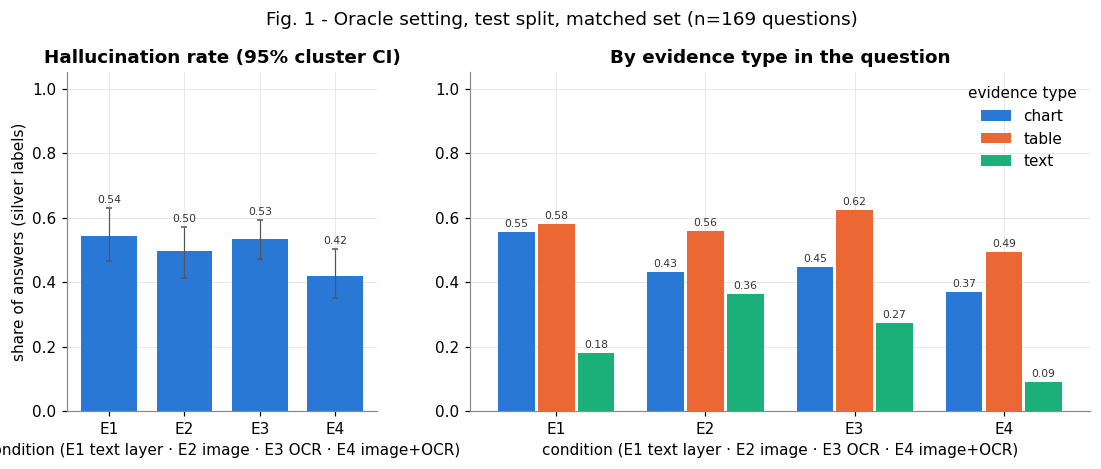

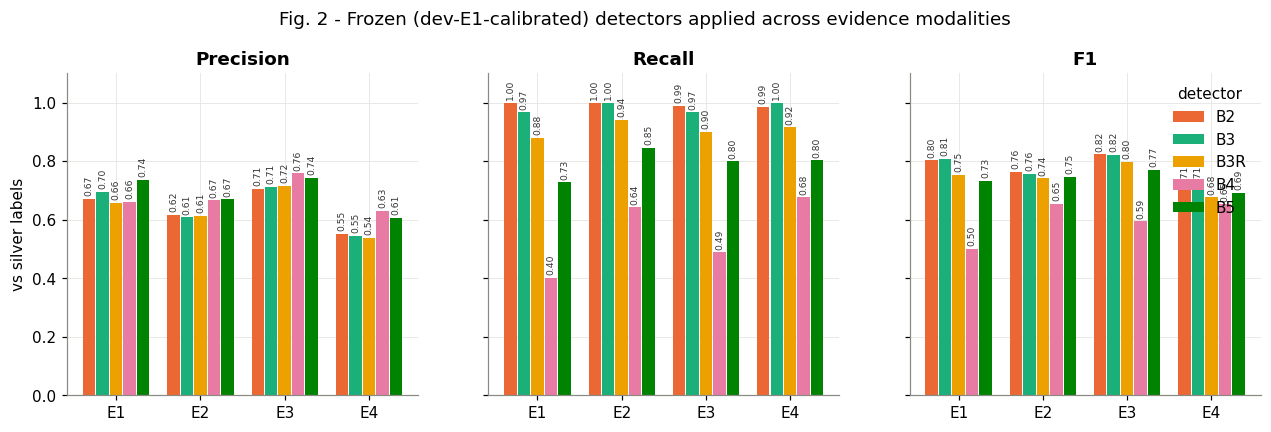

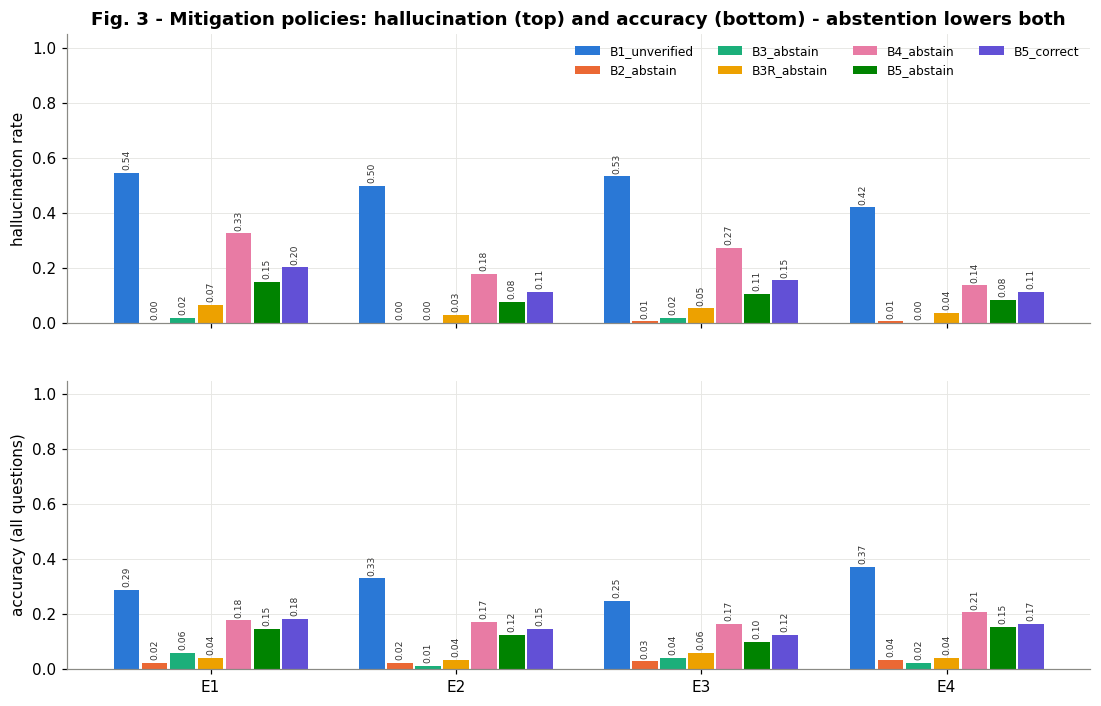

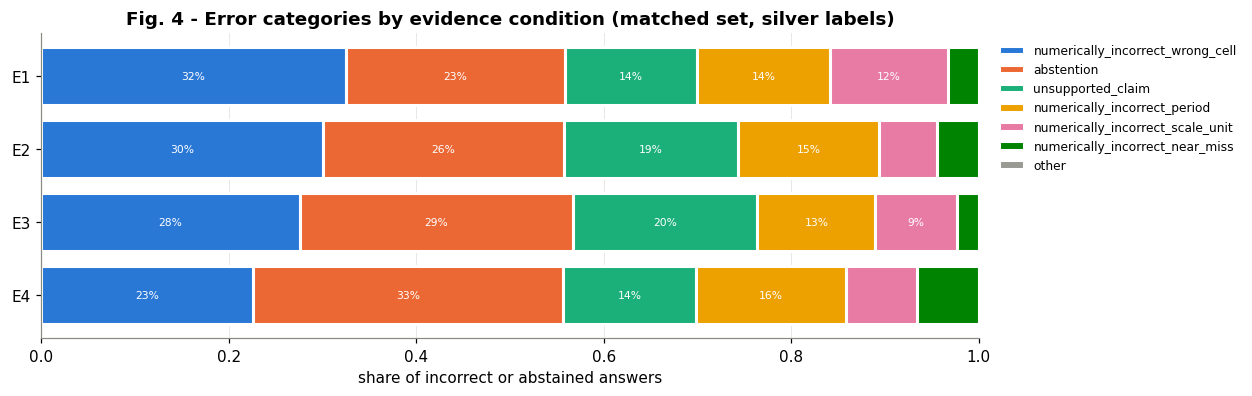

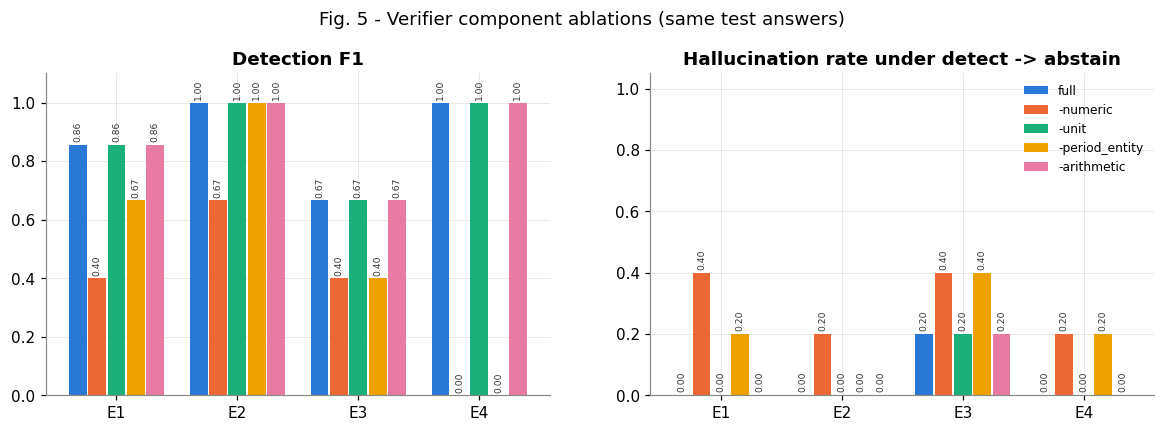

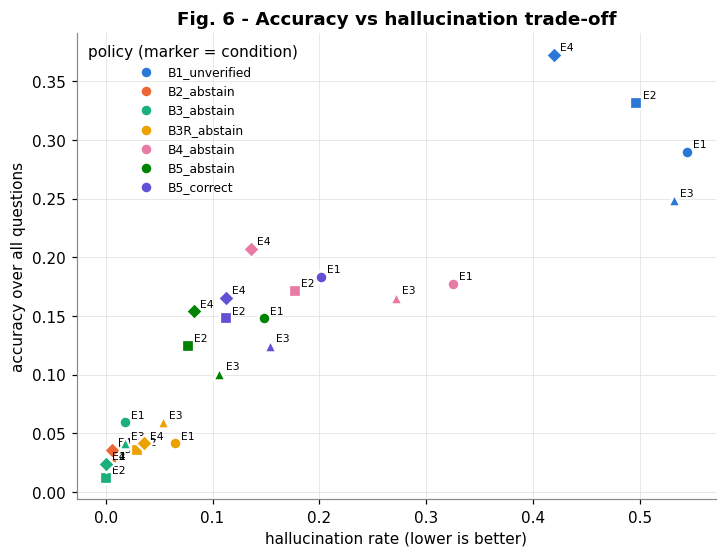

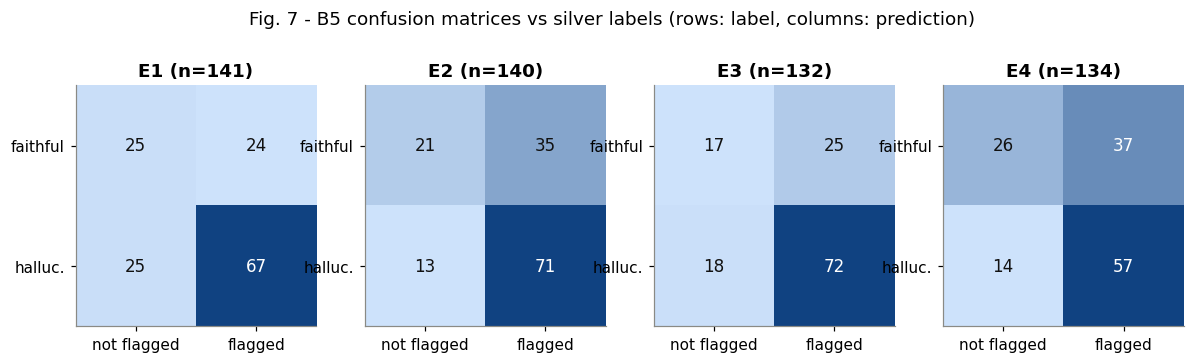

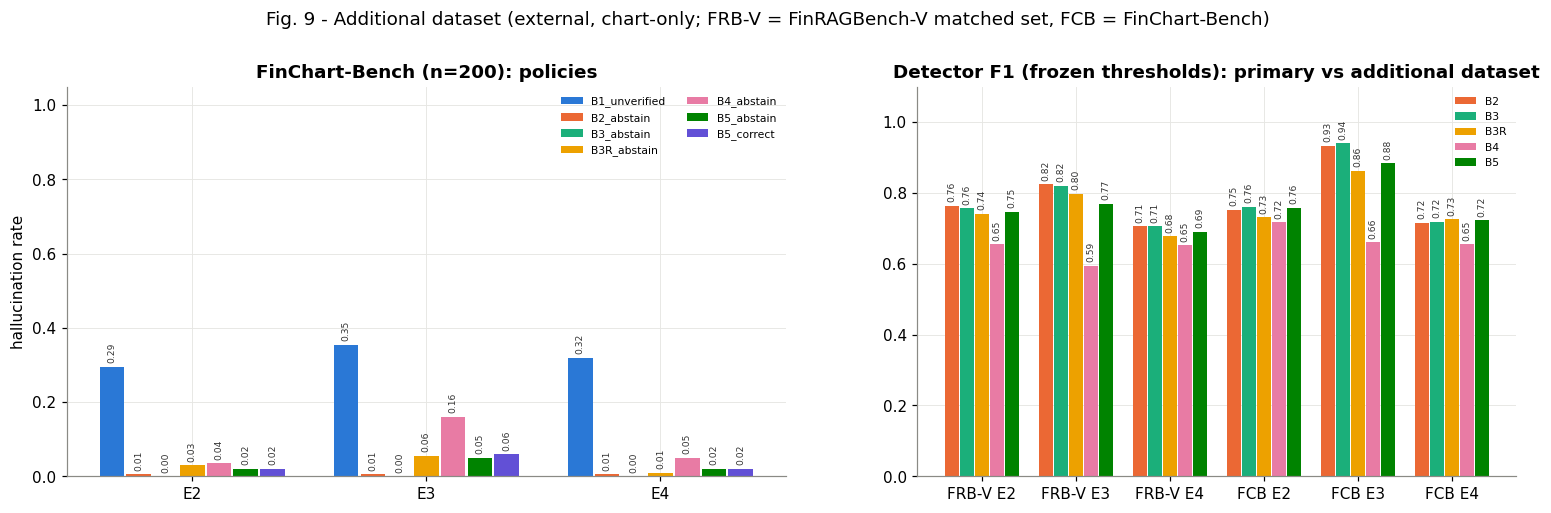

In [77]:
# ===================== 19. Visualizations =====================
import matplotlib
import matplotlib.pyplot as plt
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]   # fixed order (validated: CVD-separable)
OTHER_GRAY = "#9a9a94"
# colour follows the entity in every figure: a detector and its detect->abstain policy share a colour
COLOR_OF = {"B1_unverified": PALETTE[0], "B2_abstain": PALETTE[1], "B2": PALETTE[1], "B3_abstain": PALETTE[2], "B3": PALETTE[2],
            "B3R_abstain": PALETTE[3], "B3R": PALETTE[3], "B4_abstain": PALETTE[4], "B4": PALETTE[4],
            "B5_abstain": PALETTE[5], "B5": PALETTE[5], "B5_correct": PALETTE[6]}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "axes.edgecolor": "#8a8a85", "axes.titleweight": "bold", "legend.frameon": False})
FIG_LOG = []

def save_fig(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(DIRS["figures"] / f"{name}.{ext}", bbox_inches="tight")
    FIG_LOG.append(name); plt.show(); plt.close(fig)

def missing(name, why):
    print(f"[figure skipped] {name}: {why}"); FIG_LOG.append(f"SKIPPED:{name}:{why}")

def grouped_bars(ax, table: pd.DataFrame, err_lo=None, err_hi=None, fmt="{:.2f}"):
    """table: index = x groups, columns = series (fixed colour order by column position)."""
    n = len(table.columns); w = 0.8 / max(1, n); x = np.arange(len(table.index))
    for j, col in enumerate(table.columns):
        vals = table[col].values.astype(float)
        yerr = None
        if err_lo is not None and col in err_lo:
            yerr = np.vstack([vals - err_lo[col].values, err_hi[col].values - vals]); yerr = np.where(np.isnan(yerr), 0, yerr)
        bars = ax.bar(x + (j - (n - 1) / 2) * w, vals, w * 0.92, color=COLOR_OF.get(str(col), PALETTE[j % len(PALETTE)]), label=str(col),
                      yerr=yerr, capsize=2, error_kw={"elinewidth": 0.8, "ecolor": "#555"})
        for b, v in zip(bars, vals):
            if not np.isnan(v):
                top = v if yerr is None else err_hi[col].values[list(bars).index(b)]
                dense = n >= 5      # many series: vertical labels so neighbouring values never overlap
                ax.text(b.get_x() + b.get_width() / 2, (top if not np.isnan(top) else v) + 0.01, fmt.format(v),
                        ha="center", va="bottom", fontsize=6 if dense else 7, rotation=90 if dense else 0, color="#333")
    ax.set_xticks(x); ax.set_xticklabels(table.index)

# ---- Fig 1: hallucination rate by evidence condition and evidence type ----
q = QUALITY["primary_by_condition_and_type"]
if len(q):
    t = q["hallucination_rate"].unstack("evidence_type")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 2]})
    r = STATS.get("rates_with_ci", pd.DataFrame())
    r = r[r.metric == "silver_halluc"].set_index("condition") if len(r) else r
    if len(r):
        tt = r[["estimate"]].rename(columns={"estimate": "all types"})
        grouped_bars(axes[0], tt, r[["ci_low"]].rename(columns={"ci_low": "all types"}), r[["ci_high"]].rename(columns={"ci_high": "all types"}))
    else:
        grouped_bars(axes[0], QUALITY["primary_by_condition"][["hallucination_rate"]])
    axes[0].set_title("Hallucination rate (95% cluster CI)"); axes[0].set_ylabel("share of answers (silver labels)")
    grouped_bars(axes[1], t); axes[1].set_title("By evidence type in the question"); axes[1].legend(title="evidence type")
    for a in axes: a.set_ylim(0, 1.05); a.set_xlabel("condition (E1 text layer · E2 image · E3 OCR · E4 image+OCR)")
    fig.suptitle(f"Fig. 1 - Oracle setting, test split, matched set (n={PRIMARY.sample_id.nunique()} questions)", y=1.02)
    save_fig(fig, "fig1_hallucination_by_modality")
else:
    missing("fig1", "no primary matched results")

# ---- Fig 2: detector precision / recall / F1 by modality ----
d = DETECTION["primary_gen_text"]
if len(d) and d["positives"].sum() > 0:
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
    for ax, met in zip(axes, ["precision", "recall", "f1"]):
        grouped_bars(ax, d.pivot(index="condition", columns="detector", values=met)); ax.set_title(met.upper() if met == "f1" else met.capitalize())
        ax.set_ylim(0, 1.1)
    axes[0].set_ylabel("vs silver labels"); axes[-1].legend(title="detector", loc="upper right")
    fig.suptitle("Fig. 2 - Frozen (dev-E1-calibrated) detectors applied across evidence modalities", y=1.03)
    save_fig(fig, "fig2_detector_prf_by_modality")
else:
    missing("fig2", "no detection results with positive labels")

# ---- Fig 3: baseline vs proposed mitigation ----
m = MITIGATION["primary"]
if len(m):
    fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True)
    grouped_bars(axes[0], m.pivot(index="condition", columns="policy", values="hallucination_rate")[POLICIES])
    axes[0].set_ylabel("hallucination rate"); axes[0].set_ylim(0, 1.05); axes[0].legend(ncol=4, fontsize=8)
    grouped_bars(axes[1], m.pivot(index="condition", columns="policy", values="accuracy")[POLICIES])
    axes[1].set_ylabel("accuracy (all questions)"); axes[1].set_ylim(0, 1.05)
    axes[0].set_title("Fig. 3 - Mitigation policies: hallucination (top) and accuracy (bottom) - abstention lowers both")
    save_fig(fig, "fig3_mitigation_comparison")
else:
    missing("fig3", "no mitigation results")

# ---- Fig 4: financial error-category distribution ----
ec = PRIMARY[~PRIMARY.correct]
if len(ec):
    ct = pd.crosstab(ec.condition, ec.halluc_category, normalize="index")
    top = ct.sum().sort_values(ascending=False).index[:6]
    ct = pd.concat([ct[top], ct.drop(columns=top).sum(axis=1).rename("other")], axis=1)
    fig, ax = plt.subplots(figsize=(11, 3.6)); left = np.zeros(len(ct))
    for j, col in enumerate(ct.columns):
        col_color = OTHER_GRAY if col == "other" else PALETTE[j % len(PALETTE)]
        ax.barh(ct.index, ct[col], left=left, color=col_color, edgecolor="white", linewidth=2, label=col)
        for y, (l, v) in enumerate(zip(left, ct[col])):
            if v >= 0.08: ax.text(l + v / 2, y, f"{v:.0%}", ha="center", va="center", fontsize=7, color="white")
        left += ct[col].values
    ax.set_xlim(0, 1); ax.set_xlabel("share of incorrect or abstained answers"); ax.invert_yaxis()
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
    ax.set_title("Fig. 4 - Error categories by evidence condition (matched set, silver labels)")
    save_fig(fig, "fig4_error_categories")
else:
    missing("fig4", "no incorrect answers in the primary set")

# ---- Fig 5: ablations ----
ab = ABLATION_TABLE.dropna(subset=["f1"]) if "f1" in ABLATION_TABLE else pd.DataFrame()
if len(ab):
    order = [v for v in ABLATIONS if v in set(ab.variant)]
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
    grouped_bars(axes[0], ab.pivot(index="condition", columns="variant", values="f1")[order]); axes[0].set_title("Detection F1"); axes[0].set_ylim(0, 1.1)
    grouped_bars(axes[1], ab.pivot(index="condition", columns="variant", values="halluc_rate_after_abstain")[order])
    axes[1].set_title("Hallucination rate under detect -> abstain"); axes[1].set_ylim(0, 1.05); axes[1].legend(fontsize=8)
    fig.suptitle("Fig. 5 - Verifier component ablations (same test answers)", y=1.03)
    save_fig(fig, "fig5_ablations")
else:
    missing("fig5", "no ablation results")

# ---- Fig 6: accuracy vs hallucination trade-off ----
if len(m):
    fig, ax = plt.subplots(figsize=(7.5, 5.5))
    markers = dict(zip(CONDITIONS, ["o", "s", "^", "D"]))
    for j, p in enumerate(POLICIES):
        mm = m[m.policy == p]
        for r in mm.itertuples():
            ax.scatter(r.hallucination_rate, r.accuracy, s=60, color=COLOR_OF[p], marker=markers[r.condition],
                       edgecolor="white", linewidth=1.5, label=p if r.condition == mm.condition.iloc[0] else None, zorder=3)
            ax.annotate(r.condition, (r.hallucination_rate, r.accuracy), xytext=(4, 3), textcoords="offset points", fontsize=7)
    ax.set_xlabel("hallucination rate (lower is better)"); ax.set_ylabel("accuracy over all questions")
    ax.legend(fontsize=8, title="policy (marker = condition)")
    ax.set_title("Fig. 6 - Accuracy vs hallucination trade-off")
    save_fig(fig, "fig6_tradeoff")
else:
    missing("fig6", "no mitigation results")

# ---- Fig 7: confusion matrices (B5, frozen) ----
sc = PRIMARY[PRIMARY.scorable].dropna(subset=["B5_flag_gen_text"])
if len(sc):
    fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(13, 3.2))
    for ax, cond in zip(axes, CONDITIONS):
        dd = sc[sc.condition == cond]
        mt = det_metrics(dd.B5_flag_gen_text.astype(bool), dd.silver_halluc) if len(dd) else None
        cm = np.array([[mt["tn"], mt["fp"]], [mt["fn"], mt["tp"]]]) if mt else np.zeros((2, 2))
        ax.imshow(cm, cmap=matplotlib.colors.LinearSegmentedColormap.from_list("b", ["#cde2fb", "#104281"]))
        for (i, j), v in np.ndenumerate(cm):
            ax.text(j, i, int(v), ha="center", va="center", color="white" if v > cm.max() / 2 else "#111", fontsize=11)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["not flagged", "flagged"]); ax.set_yticks([0, 1])
        ax.set_yticklabels(["faithful", "halluc."]); ax.set_title(f"{cond} (n={len(dd)})"); ax.grid(False)
    fig.suptitle("Fig. 7 - B5 confusion matrices vs silver labels (rows: label, columns: prediction)", y=1.05)
    save_fig(fig, "fig7_confusion_b5")
else:
    missing("fig7", "no scorable B5 results")

# ---- Fig 9: additional dataset (FinChart-Bench) vs primary dataset ----
mx = MITIGATION.get("external", pd.DataFrame())
de, dp = DETECTION.get("external_gen_text", pd.DataFrame()), DETECTION["primary_gen_text"]
if len(mx) and len(de):
    fig, axes = plt.subplots(1, 2, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1.2, 1]})
    grouped_bars(axes[0], mx.pivot(index="condition", columns="policy", values="hallucination_rate")[[p for p in POLICIES if p in set(mx.policy)]])
    axes[0].set_ylim(0, 1.05); axes[0].set_ylabel("hallucination rate"); axes[0].legend(ncol=2, fontsize=7)
    axes[0].set_title(f"FinChart-Bench (n={EXTERNAL.sample_id.nunique()}): policies")
    comb = pd.concat([dp[dp.condition.isin(["E2", "E3", "E4"])].assign(ds="FRB-V"), de.assign(ds="FCB")])
    comb["group"] = comb.ds + " " + comb.condition
    order = [g for g in ["FRB-V E2", "FRB-V E3", "FRB-V E4", "FCB E2", "FCB E3", "FCB E4"] if g in set(comb.group)]
    grouped_bars(axes[1], comb.pivot(index="group", columns="detector", values="f1").reindex(order)[[d for d in DETECTORS if d in set(comb.detector)]])
    axes[1].set_ylim(0, 1.1); axes[1].set_title("Detector F1 (frozen thresholds): primary vs additional dataset"); axes[1].legend(fontsize=7)
    fig.suptitle("Fig. 9 - Additional dataset (external, chart-only; FRB-V = FinRAGBench-V matched set, FCB = FinChart-Bench)", y=1.03)
    save_fig(fig, "fig9_additional_dataset")
else:
    missing("fig9", "no external-dataset mitigation/detection results")



## 20. Failure-case analysis


/tmp/ipykernel_970/2177950534.py:17: UserWarning: Glyph 21152 (\N{CJK UNIFIED IDEOGRAPH-52A0}) missing from font(s) DejaVu Sans.
  fig.savefig(DIRS["figures"] / f"{name}.{ext}", bbox_inches="tight")
/tmp/ipykernel_970/2177950534.py:17: UserWarning: Glyph 25343 (\N{CJK UNIFIED IDEOGRAPH-62FF}) missing from font(s) DejaVu Sans.
  fig.savefig(DIRS["figures"] / f"{name}.{ext}", bbox_inches="tight")
/tmp/ipykernel_970/2177950534.py:17: UserWarning: Glyph 22823 (\N{CJK UNIFIED IDEOGRAPH-5927}) missing from font(s) DejaVu Sans.
  fig.savefig(DIRS["figures"] / f"{name}.{ext}", bbox_inches="tight")
/tmp/ipykernel_970/2177950534.py:17: UserWarning: Glyph 20013 (\N{CJK UNIFIED IDEOGRAPH-4E2D}) missing from font(s) DejaVu Sans.
  fig.savefig(DIRS["figures"] / f"{name}.{ext}", bbox_inches="tight")
/tmp/ipykernel_970/2177950534.py:17: UserWarning: Glyph 22830 (\N{CJK UNIFIED IDEOGRAPH-592E}) missing from font(s) DejaVu Sans.
  fig.savefig(DIRS["figures"] / f"{name}.{ext}", bbox_inches="tight")
/tmp/

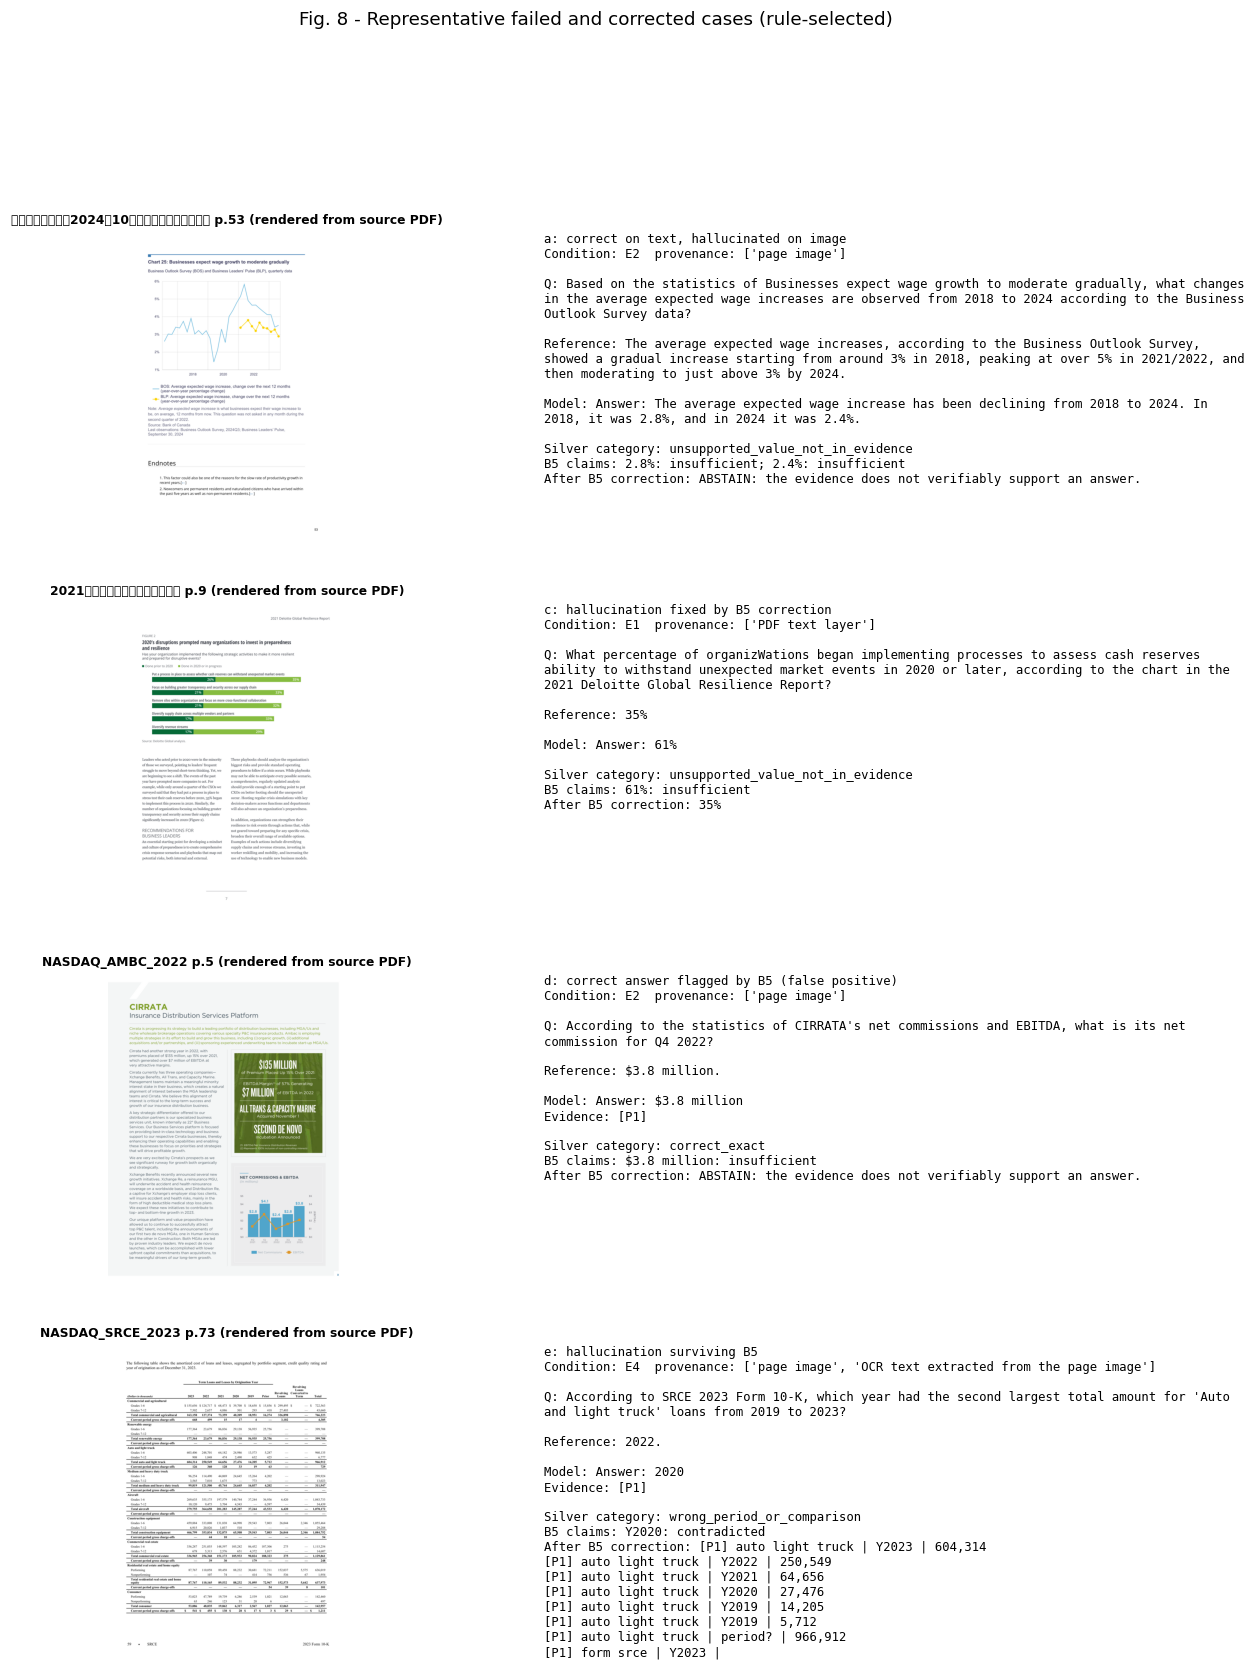


### a: correct on text, hallucinated on image
Q: Based on the statistics of Businesses expect wage growth to moderate gradually, what changes in the average expected wage increases are observed from 2018 to 2024 according to the Business Outlook Survey data?
ref: The average expected wage increases, according to the Business Outlook Survey, showed a gradual increase starting from around 3% in 2018, peaking at over 5% in 2021/2022, and then moderating to just above 3% by 2024.
model: Answer: The average expected wage increase has been declining from 2018 to 2024. In 2018, it was 2.8%, and in 2024 it was 2.4%.
B5: [{'raw': '2.8%', 'status': 'insufficient', 'reason': 'no aligned evidence value', 'periods': ['Y2018']}, {'raw': '2.4%', 'status': 'insufficient', 'reason': 'no aligned evidence value', 'periods': ['Y2024']}]

### c: hallucination fixed by B5 correction
Q: What percentage of organizWations began implementing processes to assess cash reserves ability to withstand unexpected mar

In [78]:
# ===================== 20. Failure-case analysis =====================
def _pick(df, n=1): return df.sort_values("sample_id").head(n)
cases = []
P = PRIMARY.set_index(["sample_id", "condition"])
both = [s for s in PRIMARY.sample_id.unique() if (s, "E1") in P.index and (s, "E2") in P.index]
a = [s for s in both if P.loc[(s, "E1"), "correct"] and P.loc[(s, "E2"), "silver_halluc"]]
if a: cases.append(("a: correct on text, hallucinated on image", PRIMARY[(PRIMARY.sample_id == sorted(a)[0]) & (PRIMARY.condition == "E2")].iloc[0]))
b = PRIMARY[(PRIMARY.condition == "E2") & PRIMARY.silver_halluc & (PRIMARY.get("B2_flag_gen_text") == False)]  # noqa: E712
if len(b): cases.append(("b: E2 hallucination missed by text detector B2", _pick(b).iloc[0]))
c = PRIMARY[PRIMARY.silver_halluc & (PRIMARY.B5_correct_correct == True)]  # noqa: E712
if len(c): cases.append(("c: hallucination fixed by B5 correction", _pick(c).iloc[0]))
dfp = PRIMARY[PRIMARY.correct & (PRIMARY.B5_flag_gen_text == True)]  # noqa: E712
if len(dfp): cases.append(("d: correct answer flagged by B5 (false positive)", _pick(dfp).iloc[0]))
e = PRIMARY[PRIMARY.silver_halluc & (PRIMARY.B5_correct_halluc == True)]  # noqa: E712
if len(e): cases.append(("e: hallucination surviving B5", _pick(e).iloc[0]))

case_json = []
for title, r in cases:
    s = SAMPLES[r.sample_id]; v = B5_CKPT.get(f"{r.key}|gen_text|B5full"); corr = CORR.get(r.key, {})
    case_json.append({"case": title, "gen_key": r.key, "query_id": s["query_id"], "doc_id": s["doc_id"], "page_no": s["page_no"],
                      "condition": r.condition, "evidence_provenance": r.evidence_provenance, "question": s["question"],
                      "reference_answer": s["reference_answer"], "model_output": r.raw_output, "silver_category": r.judge_error_category,
                      "b5_claims": [{k: c.get(k) for k in ("raw", "status", "reason", "periods")} for c in (v or {}).get("claims", [])],
                      "final_answer_B5_correct": corr.get("final_answer"), "image_path": s["image_path"]})
save_json(case_json, DIRS["cases"] / "failure_cases.json")

if cases:
    fig, axes = plt.subplots(len(cases), 2, figsize=(14, 4.2 * len(cases)), gridspec_kw={"width_ratios": [1, 1.6]})
    axes = np.atleast_2d(axes)
    for (ax_img, ax_txt), cj in zip(axes, case_json):
        img = Image.open(cj["image_path"]); img.thumbnail((700, 900))
        ax_img.imshow(img); ax_img.axis("off"); ax_img.set_title(f"{cj['doc_id'][:40]} p.{cj['page_no']} (rendered from source PDF)", fontsize=8)
        claims = "; ".join(f"{c['raw']}: {c['status']}" for c in cj["b5_claims"]) or "-"
        body = (f"{cj['case']}\nCondition: {cj['condition']}  provenance: {cj['evidence_provenance']}\n\n"
                f"Q: {cj['question']}\n\nReference: {cj['reference_answer']}\n\nModel: {cj['model_output']}\n\n"
                f"Silver category: {cj['silver_category']}\nB5 claims: {claims}\nAfter B5 correction: {cj['final_answer_B5_correct']}")
        ax_txt.text(0, 1, "\n".join(textwrap.fill(l, 95) for l in body.split("\n")), va="top", ha="left", fontsize=8, family="monospace")
        ax_txt.axis("off")
    fig.suptitle("Fig. 8 - Representative failed and corrected cases (rule-selected)", y=1.0)
    save_fig(fig, "fig8_failure_cases")
else:
    missing("fig8", "no cases matched the selection rules")
for cj in case_json:
    print(f"\n### {cj['case']}\nQ: {cj['question']}\nref: {cj['reference_answer']}\nmodel: {cj['model_output']}\nB5: {cj['b5_claims']}")


```markdown
## 21. Results summary (generated from the computed tables)
```

In [79]:
# ===================== 21. Results summary =====================
def _f(x, pct=True):
    return "n/a" if x is None or (isinstance(x, float) and math.isnan(x)) else (f"{x:.1%}" if pct else f"{x:.3f}")

L = [f"# Results summary - {EXECUTION_MODE} run `{CONFIG_HASH}`", "",
     f"Generator: `{GEN_MODEL_ID}` @ `{GEN_MODEL_REVISION}`; dataset `{CFG['dataset_id']}` @ `{DATASET_REVISION}`.",
     f"Labels: silver (automatic reference comparison). Human-label status: {HUMAN_STATUS}.",
     f"Primary matched population: {PRIMARY.sample_id.nunique()} test questions from {PRIMARY.doc_id.nunique()} documents, 4 conditions each.",
     f"Deviations recorded: {len(DEVIATIONS)} (see deviations.json).", ""]
L += ["## Retrieval (test)", RETRIEVAL_METRICS[RETRIEVAL_METRICS.split == "test"].round(3).to_markdown(index=False), ""]
L += ["## RQ1/RQ2 - answer quality by condition (matched set)", QUALITY["primary_by_condition"].round(3).to_markdown(), ""]
cc = STATS.get("condition_contrasts", pd.DataFrame())
if len(cc):
    L.append("Paired contrasts (difference in rate, 95% cluster-bootstrap CI, Holm-adjusted exact McNemar p):")
    for r in cc.itertuples():
        sig = "supported" if r.p_holm < CFG["alpha"] and not (r.ci_low <= 0 <= r.ci_high) else "NOT statistically supported"
        L.append(f"- {r.outcome}: {r.contrast} = {_f(r.diff)} [{_f(r.ci_low)}, {_f(r.ci_high)}], p_holm={r.p_holm:.3g} -> {sig}")
L.append("")
dt = DETECTION["primary_gen_text"]
if len(dt):
    L += ["## RQ1 - frozen detectors across modalities (primary interface)",
          dt[["condition", "detector", "n", "positives", "precision", "recall", "f1", "fpr", "auroc"]].round(3).to_markdown(index=False), ""]
tf = STATS.get("detector_transfer_f1", pd.DataFrame())
for r in tf.itertuples():
    L.append(f"- {r.detector}: {r.contrast} = {_f(r.diff, False)} [{_f(r.ci_low, False)}, {_f(r.ci_high, False)}]"
             + ("" if (r.ci_low > 0 or r.ci_high < 0) else " (CI includes 0)"))
L += ["", "## RQ3 - mitigation (matched set)", MITIGATION["primary"].round(3).to_markdown(index=False), ""]
mc = STATS.get("mitigation_contrasts", pd.DataFrame())
for r in mc[mc.policy == "B5_correct"].itertuples() if len(mc) else []:
    sig = "supported" if r.p_holm < CFG["alpha"] and not (r.ci_low <= 0 <= r.ci_high) else "NOT statistically supported"
    L.append(f"- {r.condition} {r.outcome}: B5_correct - B1 = {_f(r.diff_vs_B1)} [{_f(r.ci_low)}, {_f(r.ci_high)}], p_holm={r.p_holm:.3g} -> {sig}")
# explicit negative-result statement: does B5 beat the best simple baseline?
if len(MITIGATION["primary"]):
    for cond, d in MITIGATION["primary"].groupby("condition"):
        b5 = d[d.policy == "B5_correct"]; base = d[d.policy.isin(["B2_abstain", "B3_abstain", "B4_abstain"])]
        if len(b5) and len(base):
            best = base.sort_values("hallucination_rate").iloc[0]
            verdict = "lower" if b5.hallucination_rate.iloc[0] < best.hallucination_rate else "NOT lower"
            L.append(f"- {cond}: B5_correct hallucination {_f(b5.hallucination_rate.iloc[0])} is {verdict} than the best simple baseline "
                     f"({best.policy}: {_f(best.hallucination_rate)}); accuracy {_f(b5.accuracy.iloc[0])} vs {_f(best.accuracy)}.")
# ---- additional dataset ----
if len(EXTERNAL):
    L += ["", f"## Additional dataset - FinChart-Bench QA (external, n={EXTERNAL.sample_id.nunique()}, thresholds frozen)",
          QUALITY["external_by_condition"].round(3).to_markdown(), "",
          DETECTION["external_gen_text"][["condition", "detector", "n", "positives", "precision", "recall", "f1", "auroc"]].round(3).to_markdown(index=False)
          if len(DETECTION["external_gen_text"]) else "(no detection results)", "",
          MITIGATION["external"].round(3).to_markdown(index=False) if len(MITIGATION["external"]) else "(no mitigation results)", ""]

# ---- hypothesis verdicts (computed from the tables above; silver labels) ----
def _verdict(ok, undetermined=False):
    return "UNDETERMINED (insufficient data)" if undetermined else ("SUPPORTED" if ok else "NOT SUPPORTED")
V = []
tf = STATS.get("detector_transfer_f1", pd.DataFrame())
for r in tf.itertuples():
    und = any(isinstance(x, float) and math.isnan(x) for x in (r.diff, r.ci_low, r.ci_high))
    V.append({"hypothesis": "H1", "test": f"{r.detector}: {r.contrast}", "estimate": r.diff, "ci": f"[{r.ci_low:.3f}, {r.ci_high:.3f}]",
              "verdict": _verdict((not und) and r.ci_high < 0, und)})
cc = STATS.get("condition_contrasts", pd.DataFrame())
h2 = cc[(cc.outcome == "silver_halluc") & (cc.contrast == "E2 - E1")] if len(cc) else cc
for r in h2.itertuples():
    und = math.isnan(r.ci_low)
    V.append({"hypothesis": "H2", "test": "hallucination rate E2 - E1 (matched)", "estimate": r.diff, "ci": f"[{r.ci_low:.3f}, {r.ci_high:.3f}]",
              "verdict": _verdict((not und) and r.ci_low > 0 and r.p_holm < CFG["alpha"], und)})
mp = MITIGATION["primary"]
for r in (mc[(mc.policy == "B5_correct") & (mc.outcome == "halluc")].itertuples() if len(mc) else []):
    ret = mp[(mp.condition == r.condition) & (mp.policy == "B5_correct")].correct_answer_retention
    ret = float(ret.iloc[0]) if len(ret) else float("nan")
    und = math.isnan(r.ci_high) or math.isnan(ret)
    V.append({"hypothesis": "H3", "test": f"{r.condition}: B5_correct - B1 hallucination (retention={ret:.2f})", "estimate": r.diff_vs_B1,
              "ci": f"[{r.ci_low:.3f}, {r.ci_high:.3f}]", "verdict": _verdict((not und) and r.ci_high < 0 and r.p_holm < CFG["alpha"] and ret >= 0.90, und)})
if "f1" in ABLATION_TABLE and (ABLATION_TABLE.variant == "full").any():
    full = ABLATION_TABLE[ABLATION_TABLE.variant == "full"].set_index("condition").f1
    drops = {v: float((full - d.set_index("condition").f1).mean()) for v, d in ABLATION_TABLE[ABLATION_TABLE.variant.isin(list(ABLATIONS)[1:])].groupby("variant")}
    if drops and not all(math.isnan(x) for x in drops.values()):
        top = max(drops, key=lambda k: -1e9 if math.isnan(drops[k]) else drops[k])
        V.append({"hypothesis": "H4", "test": "largest mean F1 drop: " + ", ".join(f"{k}={v:.3f}" for k, v in drops.items()), "estimate": drops[top],
                  "ci": "descriptive", "verdict": _verdict(top in ("-numeric", "-period_entity"))})
em = STATS.get("external_mitigation_contrasts", pd.DataFrame())
for r in (em[(em.policy == "B5_correct") & (em.outcome == "halluc")].itertuples() if len(em) else []):
    und = math.isnan(r.ci_high)
    V.append({"hypothesis": "H5", "test": f"FinChart-Bench {r.condition}: B5_correct - B1 hallucination", "estimate": r.diff_vs_B1,
              "ci": f"[{r.ci_low:.3f}, {r.ci_high:.3f}]", "verdict": _verdict((not und) and r.ci_high < 0 and r.p_holm < CFG["alpha"], und)})
de_ = DETECTION.get("external_gen_text", pd.DataFrame()); dp_ = DETECTION["primary_gen_text"]
for det in ["B2", "B3", "B3R", "B4"]:
    a = de_[de_.detector == det].f1 if len(de_) else pd.Series(dtype=float)
    b = dp_[(dp_.detector == det) & (dp_.condition == "E1")].f1 if len(dp_) else pd.Series(dtype=float)
    if len(a) and len(b) and not (a.isna().all() or b.isna().all()):
        V.append({"hypothesis": "H5", "test": f"{det}: mean F1 on FinChart-Bench (E2-E4) vs FinRAGBench-V E1", "estimate": float(a.mean() - b.iloc[0]),
                  "ci": "descriptive", "verdict": _verdict(a.mean() < b.iloc[0])})
VERDICTS = pd.DataFrame(V)
VERDICTS.to_csv(DIRS["metrics"] / "hypothesis_verdicts.csv", index=False)
L += ["", "## Hypothesis verdicts (silver labels; see Section 1b for decision rules)",
      VERDICTS.round(3).to_markdown(index=False) if len(VERDICTS) else "(insufficient data)"]
L += ["", "## RQ4 - ablations", ABLATION_TABLE.round(3).to_markdown(index=False), "",
      "## Figures", *[f"- {x}" for x in FIG_LOG]]
SUMMARY_MD = "\n".join(L)
(RUN_DIR / "results_summary.md").write_text(SUMMARY_MD)
print(SUMMARY_MD)


# Results summary - FULL run `63bb09a3131b`

Generator: `Qwen/Qwen3-VL-2B-Instruct` @ `89644892e4d85e24eaac8bacfd4f463576704203`; dataset `zhaosuifeng/FinRAGBench-V` @ `d0d65255c94e687caa81ac9da7758ed25ff046a5`.
Labels: silver (automatic reference comparison). Human-label status: PENDING.
Primary matched population: 169 test questions from 52 documents, 4 conditions each.
Deviations recorded: 1 (see deviations.json).

## Retrieval (test)
| split   | method     |   recall@1 |   recall@3 |   recall@5 |   recall@10 |   mrr@10 |   n |
|:--------|:-----------|-----------:|-----------:|-----------:|------------:|---------:|----:|
| test    | bm25       |      0.362 |      0.557 |      0.61  |       0.686 |    0.471 | 210 |
| test    | dense      |      0.352 |      0.476 |      0.529 |       0.595 |    0.427 | 210 |
| test    | hybrid_rrf |      0.371 |      0.557 |      0.629 |       0.719 |    0.482 | 210 |

## RQ1/RQ2 - answer quality by condition (matched set)
| condition   |   n |   exa

```markdown
## 23. Export and download of experiment artifacts
```

In [80]:
# ===================== 23. Export =====================
REPRO = {"config_hash": CONFIG_HASH, "cfg": CFG, "environment": ENV_INFO, "model": MODEL_RECORD,
         "dense_retriever_revision": dense_info.sha, "nli_model_revision": nli_info.sha, "dataset": DATASET_PROVENANCE, "external_dataset": EXT_PROVENANCE,
         "page_numbering": "1-based" if PAGE_BASE == 1 else "0-based", "thresholds": THRESHOLDS, "deviations": DEVIATIONS,
         "n_candidates_selected": int(len(candidates)), "n_primary_matched": int(PRIMARY.sample_id.nunique()),
         "n_exclusions": len(exclusions), "human_label_status": HUMAN_STATUS,
         "sample_selection": "single-gold-page, numeric reference, document-level hash split (dev 30%), category-stratified hash order",
         "finished_utc": datetime.datetime.now(datetime.timezone.utc).isoformat()}
save_json(REPRO, RUN_DIR / "reproducibility_record.json")
pd.DataFrame(exclusions).to_csv(DIRS["metrics"] / "exclusions.csv", index=False)

zip_path = BASE_DIR / f"finx_artifacts_{EXECUTION_MODE.lower()}_{CONFIG_HASH}.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in RUN_DIR.rglob("*"):
        if p.is_file() and p.suffix != ".npy":
            zf.write(p, p.relative_to(RUN_DIR.parent))
print(f"Artifacts: {zip_path} ({zip_path.stat().st_size/1024**2:.1f} MB)")
if IN_COLAB:
    from google.colab import files
    files.download(str(zip_path))


Artifacts: /content/drive/MyDrive/finx_research/finx_artifacts_full_63bb09a3131b.zip (5.3 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>